# Montra Hospitality Intel 

Montra Hospitality Intel helps independent and mid-sized UK hotels turn operational data into business intelligence. Its platform already reports structured metrics (revenue, occupancy, bookings). This project extends it into **customer experience intelligence**: turning free-text guest reviews into measurable evidence of what guests talk about, how they feel about it, and where hotels should act.

## Business problem

Ratings tell a hotel **how** satisfied guests are, not **why**. The reasons sit in review text, which today must be read by hand. That creates operational inefficiency, inconsistent interpretation, and hidden recurring problems, especially because one review often mixes praise and complaints about different aspects of a stay.

View experiments: from the project root run `mlflow ui --backend-store-uri sqlite:///mlruns/mlflow.db`, then open http://127.0.0.1:5000.

## Setup

In [ ]:
import os, sys, re, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

# Paths
PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebook" else Path.cwd().resolve()
RAW_DIR   = PROJECT_ROOT / "data" / "raw"
PROC_DIR  = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
MLRUNS_DIR = PROJECT_ROOT / "mlruns"
for d in (RAW_DIR, PROC_DIR, MODEL_DIR, MLRUNS_DIR):
    d.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(PROJECT_ROOT / "src"))
from text_preprocessing import (clean_text, preprocess_corpus, split_sentences,
                                strip_connectors, normalise_unicode, LEVELS, STOP_WORDS)

# Run configuration
SEED = 42
# Pre-trained transformer used for topic embeddings and for the fine-tuned classifier:
# a Hugging Face model id, or a local folder containing a saved model.
TRANSFORMER_MODEL = os.getenv("MONTRA_TRANSFORMER", "roberta-base")
TRANSFORMER_LABEL = "RoBERTa-base" if "roberta" in TRANSFORMER_MODEL.lower() else Path(TRANSFORMER_MODEL).name
EMBEDDING_BACKEND = "auto"     # "auto": cached → sentence-transformers (all-MiniLM-L6-v2) → TRANSFORMER_MODEL mean-pooled → TF-IDF + SVD
RUN_BERT = "auto"              # "auto": fine-tune only if no saved results exist | True: always retrain | False: never train
WRITE_OUTPUTS_TO_DB = False    # also write model outputs to a separate Postgres table

np.random.seed(SEED)
NOTEBOOK_START = pd.Timestamp.now(tz="UTC")   # used to summarise this execution's MLflow runs
sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11})
SENT_ORDER  = ["negative", "neutral", "positive"]
SENT_COLORS = {"negative": "#C8553D", "neutral": "#B9B9B9", "positive": "#2A9D8F"}
pd.set_option("display.max_columns", 40, "display.width", 200, "display.max_colwidth", 120)
print("Project root:", PROJECT_ROOT)

Project root: D:\Amdari\Project_montra


---
# Business Understanding

**The business problem.** Montra's hotels know *how* satisfied guests are (ratings) but not *why*. The reasons sit in free-text reviews that are read by hand, slowly and inconsistently. Recurring complaints therefore stay hidden, and one review often mixes praise and complaints about different parts of a stay.

**Translating the brief's key questions into measurable analytical requirements:**

| Key question | Analytical requirement (what is measured) | Method | Answered in |
|---|---|---|---|
| What factors influence guest satisfaction? | Variation in rating explained by structured variables vs by what guests say about each aspect | Correlations, segment comparisons, regression of rating on aspect sentiment (R²) | 2.5–2.9, 5.3, 8.3–8.4 |
| What issues repeatedly appear in guest feedback? | Frequency of each complaint theme and the most repeated complaint statements | BERTopic themes + sentence-level sentiment | 4.5–4.6, 8.6 |
| Which topics generate positive or negative sentiment? | Positive, neutral and negative share and net sentiment per aspect, overall and per hotel | Topic sentiment analysis | 5.2, 5.4, 8.7 |
| How can management identify recurring customer experience problems? | A repeatable scoring pipeline with outputs linked by `review_id`; hotel × aspect gaps; trends over time | Model outputs table, heatmaps, trend monitor | 5.4, 8.1, 8.5 |
| Which modelling approach is most effective for classifying guest sentiment? | Accuracy, macro precision, recall and F1, confusion matrix on a held-out test set; cost and simplicity | Baselines vs fine-tuned BERT-family model, experiment grid tracked in MLflow | 6.2–6.4, 7.1–7.6 |

**Success criteria set up front:** the classifier is judged on *macro*-F1, so the smaller negative class counts equally, and a transformer must beat the best classical model by more than run-to-run noise to be preferred. Business findings must point to a specific aspect *and* a specific hotel or segment, so that they can be acted on.

---
# Data Collection 

### 1.1 Repeatable extraction pipeline

In [ ]:
from sqlalchemy import create_engine, text

SOURCE_TABLES = ["reviews", "bookings", "guests", "hotels"]

def get_engine():
    """Build a SQLAlchemy engine from the DATABASE_URL environment variable (or .env file).
    pool_pre_ping + pool_recycle stop Neon's serverless idle-timeouts from leaving stale connections."""
    url = os.getenv("DATABASE_URL")
    if not url:
        try:
            from dotenv import load_dotenv
            load_dotenv(PROJECT_ROOT / ".env")
            url = os.getenv("DATABASE_URL")
        except ImportError:
            pass
    if not url:
        return None
    return create_engine(url, pool_pre_ping=True, pool_recycle=300, connect_args={"connect_timeout": 10})

def extract_tables(refresh: bool = False) -> dict:
    """Extract Montra's source tables. Pulls from PostgreSQL when a connection is configured
    (and caches a raw snapshot), otherwise reads the cached snapshot in data/raw."""
    engine = get_engine()
    tables = {}
    for name in SOURCE_TABLES:
        cache = RAW_DIR / f"{name}.csv"
        if engine is not None and (refresh or not cache.exists()):
            with engine.connect() as conn:
                df = pd.read_sql(text(f"SELECT * FROM {name}"), conn)
            df.to_csv(cache, index=False)
            source = "PostgreSQL"
        else:
            df = pd.read_csv(cache)
            source = "cached snapshot"
        tables[name] = df
        print(f"{name:<9} {len(df):>7,} rows × {df.shape[1]} columns   [{source}]")
    return tables

raw = extract_tables(refresh=False)
reviews_raw, bookings_raw, guests_raw, hotels_raw = (raw[t] for t in SOURCE_TABLES)

reviews    35,000 rows × 8 columns   [cached snapshot]
bookings   35,000 rows × 9 columns   [cached snapshot]
guests     12,000 rows × 5 columns   [cached snapshot]
hotels         25 rows × 5 columns   [cached snapshot]


### 1.2 Source table profile

In [ ]:
keys = {"reviews": "review_id", "bookings": "booking_id", "guests": "guest_id", "hotels": "hotel_id"}
profile = pd.DataFrame([{
    "table": n, "rows": len(d), "columns": d.shape[1], "primary key": keys[n],
    "key unique": d[keys[n]].is_unique, "missing cells": int(d.isna().sum().sum()),
    "columns with missing": ", ".join(d.columns[d.isna().any()]) or "—",
} for n, d in raw.items()])
display(profile)
display(reviews_raw.head(3))

,table,rows,columns,primary key,key unique,missing cells,columns with missing
0,reviews,35000,8,review_id,True,0,—
1,bookings,35000,9,booking_id,True,0,—
2,guests,12000,5,guest_id,True,6036,loyalty_status
3,hotels,25,5,hotel_id,True,0,—


,review_id,booking_id,guest_id,hotel_id,review_text,rating_score,review_date,sentiment_label
0,1,1,6699,18,"The overall price was fair for what we paid. Might consider it again, might not.",3.2,2025-06-02,neutral
1,2,2,11380,23,The room was nothing out of the ordinary for what we paid. The overall price exceeded our expectations — a great dea...,4.0,2025-01-22,positive
2,3,3,4812,13,"Unfortunately, the pool was outdated — it clearly needed some upkeep. Wouldn't recommend it to others.",1.9,2025-03-13,negative


### 1.3 Referential integrity: can every review be linked to its context?

In [ ]:
chk = reviews_raw.merge(bookings_raw[["booking_id", "guest_id", "hotel_id", "check_in_date", "check_out_date"]],
                        on="booking_id", how="left", suffixes=("", "_bk"))
integrity = pd.DataFrame({
    "check": ["review → booking exists", "review → guest exists", "review → hotel exists",
              "review guest_id matches booking guest_id", "review hotel_id matches booking hotel_id",
              "one review per booking"],
    "violations": [
        int((~reviews_raw.booking_id.isin(bookings_raw.booking_id)).sum()),
        int((~reviews_raw.guest_id.isin(guests_raw.guest_id)).sum()),
        int((~reviews_raw.hotel_id.isin(hotels_raw.hotel_id)).sum()),
        int((chk.guest_id != chk.guest_id_bk).sum()),
        int((chk.hotel_id != chk.hotel_id_bk).sum()),
        int(reviews_raw.booking_id.duplicated().sum()),
    ]})
integrity["status"] = np.where(integrity.violations == 0, "PASS", "FAIL")
display(integrity)

,check,violations,status
0,review → booking exists,0,PASS
1,review → guest exists,0,PASS
2,review → hotel exists,0,PASS
3,review guest_id matches booking guest_id,0,PASS
4,review hotel_id matches booking hotel_id,0,PASS
5,one review per booking,0,PASS


### 1.4 Consolidated analytical table

In [ ]:
df_raw = (reviews_raw
          .merge(bookings_raw.drop(columns=["guest_id", "hotel_id"]), on="booking_id", how="left", validate="one_to_one")
          .merge(guests_raw, on="guest_id", how="left", validate="many_to_one")
          .merge(hotels_raw, on="hotel_id", how="left", validate="many_to_one"))
print("Consolidated table:", df_raw.shape)
print("Rows lost or duplicated by the joins:", len(df_raw) - len(reviews_raw))
df_raw.head(3)

Consolidated table: (35000, 22)
Rows lost or duplicated by the joins: 0


,review_id,booking_id,guest_id,hotel_id,review_text,rating_score,review_date,sentiment_label,room_type,booking_channel,check_in_date,check_out_date,total_amount,stay_duration,customer_type,loyalty_status,country,previous_stays,hotel_name,location,star_rating,total_rooms
0,1,1,6699,18,"The overall price was fair for what we paid. Might consider it again, might not.",3.2,2025-06-02,neutral,Suite,Direct Website,2025-05-25,2025-05-26,296.44,1,Leisure,NaN,France,4,The Aberdeen Grand,Aberdeen,4,118
1,2,2,11380,23,The room was nothing out of the ordinary for what we paid. The overall price exceeded our expectations — a great dea...,4.0,2025-01-22,positive,Deluxe,Corporate Portal,2025-01-09,2025-01-13,483.56,4,Business,Gold,Germany,4,Nottingham Park Hotel,Nottingham,4,95
2,3,3,4812,13,"Unfortunately, the pool was outdated — it clearly needed some upkeep. Wouldn't recommend it to others.",1.9,2025-03-13,negative,Executive,Travel Agent,2025-03-04,2025-03-06,415.59,2,Business,NaN,Ireland,4,The London Boutique,London,4,231


> **Insight — Objective 1 (Data collection).**
> - All four source tables were extracted and consolidated into one analytical table of **35,000 reviews × 22 columns**, covering **25 hotels in 14 UK cities**, **11,377 guests**, from **2 Jan 2025 to 30 Jun 2026**.
> - Referential integrity is perfect. Every review links to exactly one booking, guest and hotel, and the guest and hotel recorded on the review match the booking. The joins neither lost nor duplicated a single row.
> - The only missing field is `loyalty_status` (6,036 of 12,000 guests). It is **structural**: those guests are simply not enrolled. It is handled in Objective 3 rather than dropped.
> - **Repeatability:** `extract_tables()` reads the connection string from `.env`, refreshes snapshots on demand (`refresh=True`), and falls back to the cached CSVs when offline. Re-running the notebook on new data needs no code change.
>
> **Conclusion:** the data collection pipeline deliverable is complete. Reviews now carry their full booking, guest and hotel context, which is what makes the segment and hotel-level analytics later in the notebook possible.

---
# Exploratory Data Analysis 

Understand structure, distributions, relationships and patterns before modelling, covering review volumes, ratings, text, hotels, guests and bookings, and how ratings relate to what guests write.

In [ ]:
eda = df_raw.copy()
eda["review_date"] = pd.to_datetime(eda["review_date"])
eda["month"] = eda["review_date"].dt.to_period("M").dt.to_timestamp()
eda["word_count"] = eda["review_text"].str.split().str.len()
eda["char_count"] = eda["review_text"].str.len()
eda["n_sentences"] = eda["review_text"].map(lambda t: len(split_sentences(t)))
eda["rating_band"] = pd.cut(eda["rating_score"], [0, 2.5, 3.5, 5.01], right=False, labels=SENT_ORDER)
eda["is_negative"] = (eda["sentiment_label"] == "negative").astype(int)
print(f"{len(eda):,} reviews | {eda.hotel_id.nunique()} hotels in {eda.location.nunique()} cities | "
      f"{eda.guest_id.nunique():,} guests | {eda.review_date.min():%d %b %Y} → {eda.review_date.max():%d %b %Y}")

35,000 reviews | 25 hotels in 14 cities | 11,377 guests | 02 Jan 2025 → 30 Jun 2026


### 2.1 Sentiment labels and rating distribution

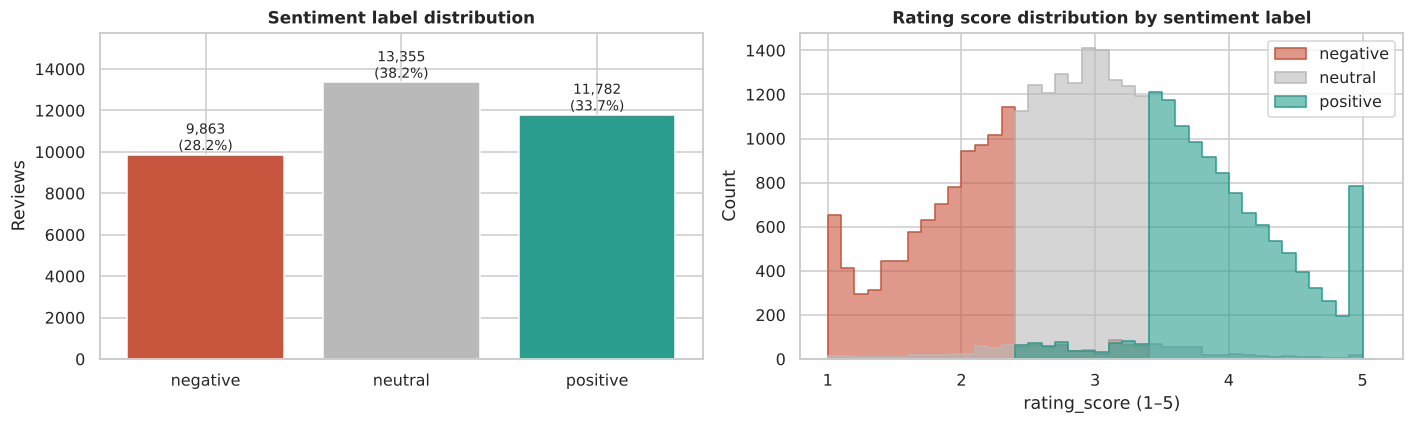

,count,mean,std,min,25%,50%,75%,max
sentiment_label,,,,,,,,
negative,9863.0,1.94,0.48,1.0,1.6,2.0,2.3,3.4
neutral,13355.0,2.96,0.37,1.0,2.7,3.0,3.2,5.0
positive,11782.0,4.01,0.51,2.5,3.6,3.9,4.4,5.0


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
vc = eda["sentiment_label"].value_counts().reindex(SENT_ORDER)
ax[0].bar(vc.index, vc.values, color=[SENT_COLORS[s] for s in vc.index])
for i, v in enumerate(vc.values):
    ax[0].text(i, v, f"{v:,}\n({v/len(eda):.1%})", ha="center", va="bottom", fontsize=9)
ax[0].set_title("Sentiment label distribution"); ax[0].set_ylabel("Reviews"); ax[0].set_ylim(0, vc.max() * 1.18)

for s in SENT_ORDER:
    sns.histplot(eda.loc[eda.sentiment_label == s, "rating_score"], bins=np.arange(1, 5.11, 0.1),
                 color=SENT_COLORS[s], label=s, ax=ax[1], alpha=0.6, element="step")
ax[1].set_title("Rating score distribution by sentiment label"); ax[1].set_xlabel("rating_score (1–5)"); ax[1].legend()
plt.tight_layout(); plt.show()
display(eda.groupby("sentiment_label")["rating_score"].describe().reindex(SENT_ORDER).round(2))

> **Insight — label and rating distributions.**
> - The classes are reasonably balanced: **neutral 38.2%**, positive 33.7%, negative 28.2%. No resampling is needed, but *macro*-averaged metrics are used throughout so the smallest class (negative) counts equally.
> - Ratings are centred on 3.0 (mean 3.03). Each label sits on a clear rating band (negative ≈ 1.9, neutral ≈ 3.0, positive ≈ 4.0), **but the bands overlap**: neutral reviews range from 1.0 to 5.0 and positive reviews go as low as 2.5.
> - **Implication:** ratings alone cannot reproduce the labels. The sentiment labels capture something about the *wording* that the number does not, which is exactly why text analysis is needed.

### 2.2 How consistent are the labels with the ratings?

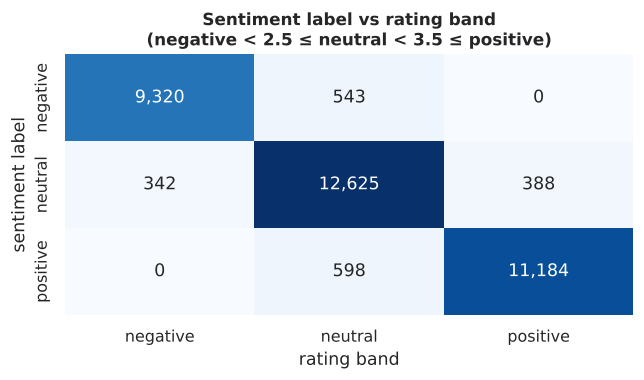

Label agrees with rating band: 94.65%   |   disagrees: 5.35% (1,871 reviews)
Positive labelled with a negative-band rating, or vice versa: 0


In [ ]:
ct = pd.crosstab(eda["sentiment_label"], eda["rating_band"]).reindex(SENT_ORDER)
fig, ax = plt.subplots(figsize=(6, 3.6))
sns.heatmap(ct, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax)
ax.set_title("Sentiment label vs rating band\n(negative < 2.5 ≤ neutral < 3.5 ≤ positive)")
ax.set_xlabel("rating band"); ax.set_ylabel("sentiment label")
plt.tight_layout(); plt.show()
agree = (eda["sentiment_label"] == eda["rating_band"].astype(str)).mean()
print(f"Label agrees with rating band: {agree:.2%}   |   disagrees: {1-agree:.2%} ({(1-agree)*len(eda):,.0f} reviews)")
print("Positive labelled with a negative-band rating, or vice versa:",
      int(((eda.sentiment_label == 'positive') & (eda.rating_band == 'negative')).sum() +
          ((eda.sentiment_label == 'negative') & (eda.rating_band == 'positive')).sum()))

> **Insight — label quality.**
> - **94.65%** of labels agree with the rating band. **1,871 reviews (5.35%) disagree**, for example a review rated 5.0 but labelled *neutral*.
> - Crucially, **no review jumps two classes** (positive label with a negative-band rating, or the reverse). All disagreements sit on the boundaries of neutral.
> - **Implication for modelling:** about 5% of labels are probably noisy. This sets a practical ceiling: a model that predicts the "true" sentiment perfectly would still be marked wrong on roughly 5% of reviews. Objective 7's error analysis tests this directly.

### 2.3 Review volume, ratings and sentiment over time

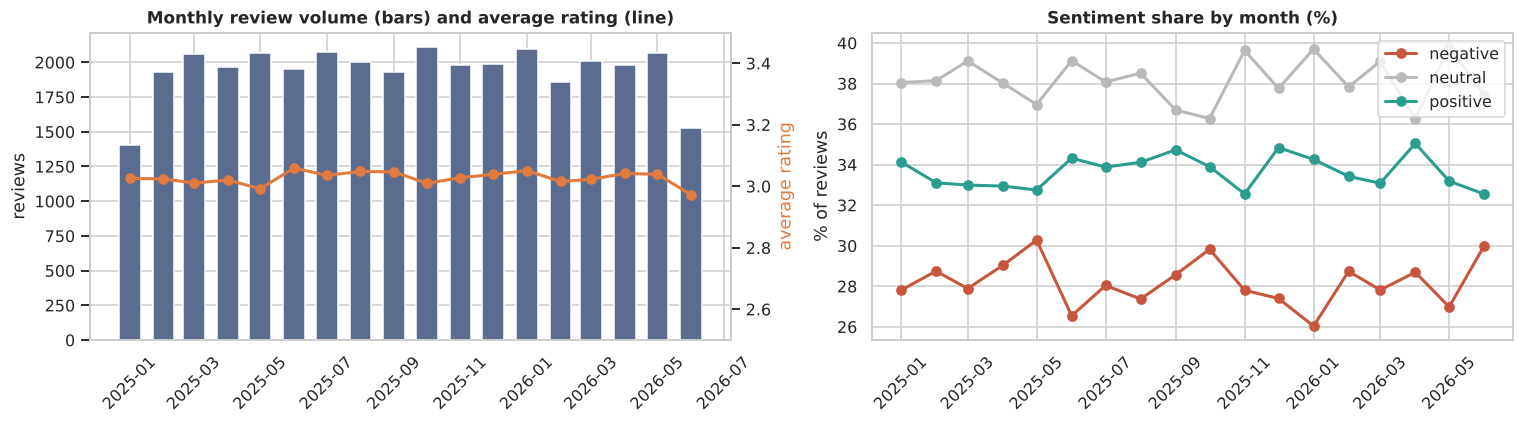

Monthly volume range: 1406 – 2109 | avg rating range: 2.97 – 3.06
Partial months: Jan 2025 (1406), Jun 2026 (1530)


In [ ]:
monthly = eda.groupby("month").agg(reviews=("review_id", "size"), avg_rating=("rating_score", "mean"))
share = pd.crosstab(eda["month"], eda["sentiment_label"], normalize="index").reindex(columns=SENT_ORDER)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].bar(monthly.index, monthly["reviews"], width=20, color="#5B6C8F")
ax0b = ax[0].twinx(); ax0b.plot(monthly.index, monthly["avg_rating"], color="#E07A3F", marker="o", lw=2)
ax0b.set_ylim(2.5, 3.5); ax0b.set_ylabel("average rating", color="#E07A3F"); ax0b.grid(False)
ax[0].set_title("Monthly review volume (bars) and average rating (line)"); ax[0].set_ylabel("reviews")
for s in SENT_ORDER:
    ax[1].plot(share.index, share[s] * 100, marker="o", color=SENT_COLORS[s], label=s, lw=2)
ax[1].set_title("Sentiment share by month (%)"); ax[1].set_ylabel("% of reviews"); ax[1].legend()
for a in ax: a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
print("Monthly volume range:", monthly.reviews.min(), "–", monthly.reviews.max(),
      "| avg rating range: %.2f – %.2f" % (monthly.avg_rating.min(), monthly.avg_rating.max()))
print("Partial months:", ", ".join(f"{m:%b %Y} ({n})" for m, n in monthly.reviews.items() if n < 0.8 * monthly.reviews.median()))

> **Insight — volume and trends.**
> - Review volume is steady at **~1,900–2,100 per month**. January 2025 and June 2026 are partial months (first and last month of the extract) and should not be read as dips.
> - The average rating barely moves (**2.97–3.06**) and sentiment shares are flat across 18 months.
> - **Implication:** there is no portfolio-wide deterioration or seasonality to explain. Any emerging problem will sit inside specific aspects or hotels, not in the overall trend. Section 8.5 therefore tracks trends *per aspect*.

### 2.4 Textual characteristics: review length and structure

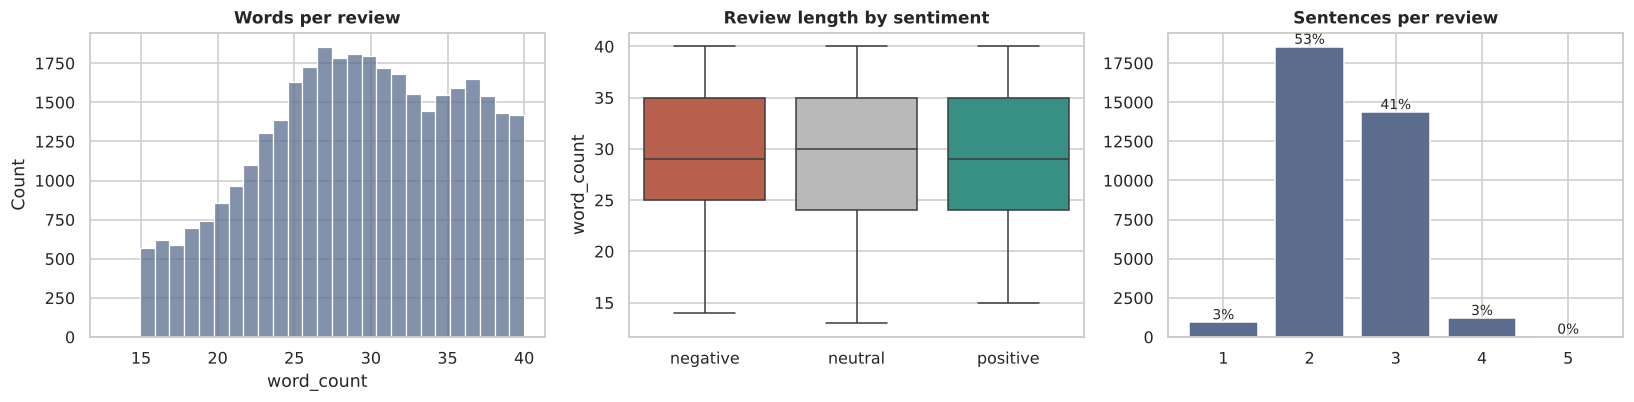

,count,mean,std,min,25%,50%,75%,max
word_count,35000.0,29.2,6.6,13.0,24.0,29.0,35.0,40.0
char_count,35000.0,171.9,39.8,67.0,143.0,172.0,203.0,280.0
n_sentences,35000.0,2.5,0.6,1.0,2.0,2.0,3.0,5.0


Correlation word_count ↔ rating: 0.002


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
sns.histplot(eda["word_count"], bins=28, color="#5B6C8F", ax=ax[0]); ax[0].set_title("Words per review")
sns.boxplot(data=eda, x="sentiment_label", y="word_count", order=SENT_ORDER, palette=SENT_COLORS, ax=ax[1])
ax[1].set_title("Review length by sentiment"); ax[1].set_xlabel("")
sc = eda["n_sentences"].value_counts().sort_index()
ax[2].bar(sc.index.astype(str), sc.values, color="#5B6C8F"); ax[2].set_title("Sentences per review")
for i, v in enumerate(sc.values): ax[2].text(i, v, f"{v/len(eda):.0%}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()
display(eda[["word_count", "char_count", "n_sentences"]].describe().T.round(1))
print("Correlation word_count ↔ rating: %.3f" % eda["word_count"].corr(eda["rating_score"]))

> **Insight — text characteristics.**
> - Reviews are short and uniform: **13–40 words** (mean 29), **2.5 sentences** on average. 53% have two sentences and 41% have three.
> - Length carries **no sentiment signal** (correlation with rating 0.002), and negative reviews are no longer than positive ones.
> - **Implications:**
>   - Every review fits comfortably inside a transformer's input window. ~60 tokens means `max_len=64` will hardly truncate anything (tested in 7.3).
>   - Because most reviews contain two or three sentences on different aspects, topic and aspect sentiment analysis should work **at sentence level** (Objective 4).

### 2.5 Hotel-level patterns

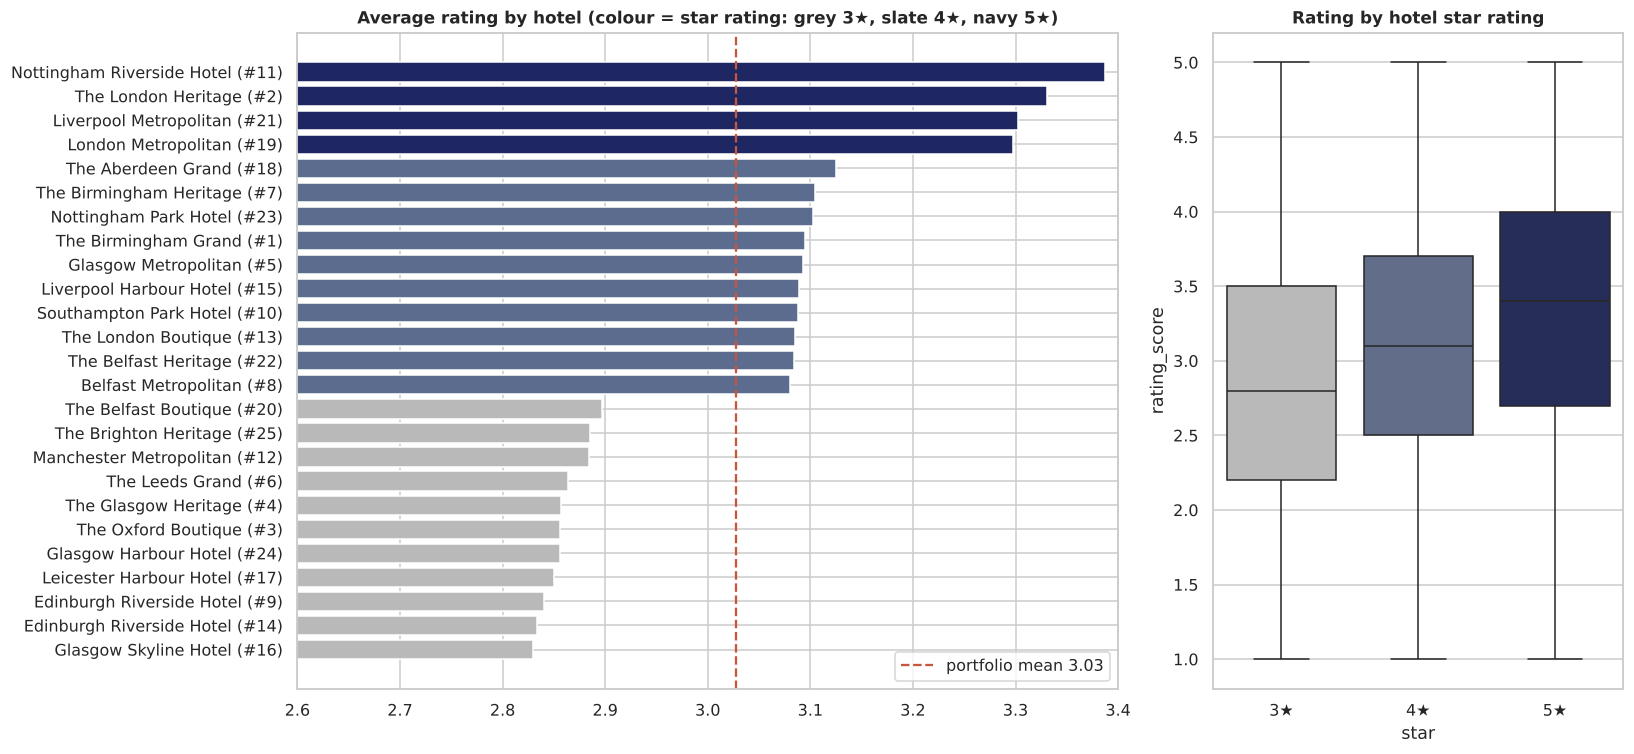

,hotels,reviews,avg_rating,negative_share
location,,,,
Nottingham,2,"2,872",3.25,20.9%
London,3,"4,145",3.24,21.3%
Liverpool,2,"2,695",3.19,22.9%
Aberdeen,1,"1,362",3.12,24.6%
Birmingham,2,"2,795",3.10,25.3%
Southampton,1,"1,460",3.09,26.0%
Belfast,3,"4,202",3.02,28.4%
Glasgow,4,"5,612",2.91,32.1%
Brighton,1,"1,399",2.88,33.2%


Spread between best and worst hotel average rating: 0.56 points
              mean  count
star_rating              
3            2.859  15450
4            3.094  14084
5            3.331   5466


In [ ]:
hotel = (eda.groupby(["hotel_id", "hotel_name", "location", "star_rating"])
         .agg(reviews=("review_id", "size"), avg_rating=("rating_score", "mean"), negative_share=("is_negative", "mean"))
         .reset_index().sort_values("avg_rating"))
hotel["label"] = hotel["hotel_name"] + " (#" + hotel["hotel_id"].astype(str) + ")"

fig, ax = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios": [2, 1]})
star_pal = {3: "#B9B9B9", 4: "#5B6C8F", 5: "#1E2761"}
ax[0].barh(hotel["label"], hotel["avg_rating"], color=hotel["star_rating"].map(star_pal))
ax[0].axvline(eda.rating_score.mean(), ls="--", color="#C8553D", label=f"portfolio mean {eda.rating_score.mean():.2f}")
ax[0].set_xlim(2.6, 3.4); ax[0].set_title("Average rating by hotel (colour = star rating: grey 3★, slate 4★, navy 5★)")
ax[0].legend(loc="lower right")
sns.boxplot(data=eda.assign(star=eda.star_rating.astype(str) + "★"), x="star", y="rating_score", order=["3★", "4★", "5★"],
            palette={f"{k}★": v for k, v in star_pal.items()}, ax=ax[1])
ax[1].set_title("Rating by hotel star rating")
plt.tight_layout(); plt.show()

loc = (eda.groupby("location").agg(hotels=("hotel_id", "nunique"), reviews=("review_id", "size"),
        avg_rating=("rating_score", "mean"), negative_share=("is_negative", "mean"))
        .sort_values("avg_rating", ascending=False))
display(loc.style.format({"avg_rating": "{:.2f}", "negative_share": "{:.1%}", "reviews": "{:,}"}))
print("Spread between best and worst hotel average rating: %.2f points" % (hotel.avg_rating.max() - hotel.avg_rating.min()))
print(eda.groupby("star_rating")["rating_score"].agg(["mean", "count"]).round(3))

> **Insight — hotel-level patterns.**
> - Hotel matters far more than anything in the booking. The best and worst hotels differ by **0.56 rating points**, and **star rating** is the strongest structured driver (3★ 2.86 → 4★ 3.09 → 5★ 3.33).
> - **By city:**
>   - **Nottingham (3.25, 20.9% negative)** and **London (3.24)** lead.
>   - **Edinburgh (2.84, 35.3% negative)**, **Leicester**, **Oxford** and **Leeds** trail.
>   - The bottom group is made up entirely of 3★ properties, so location and star level are confounded and should not be read as a "city effect".
> - **Implication:** hotel-level comparisons must account for star rating. A 3★ hotel scoring 2.9 may be performing to standard, while a 5★ hotel at 3.1 is under-performing.

### 2.6 Guest characteristics

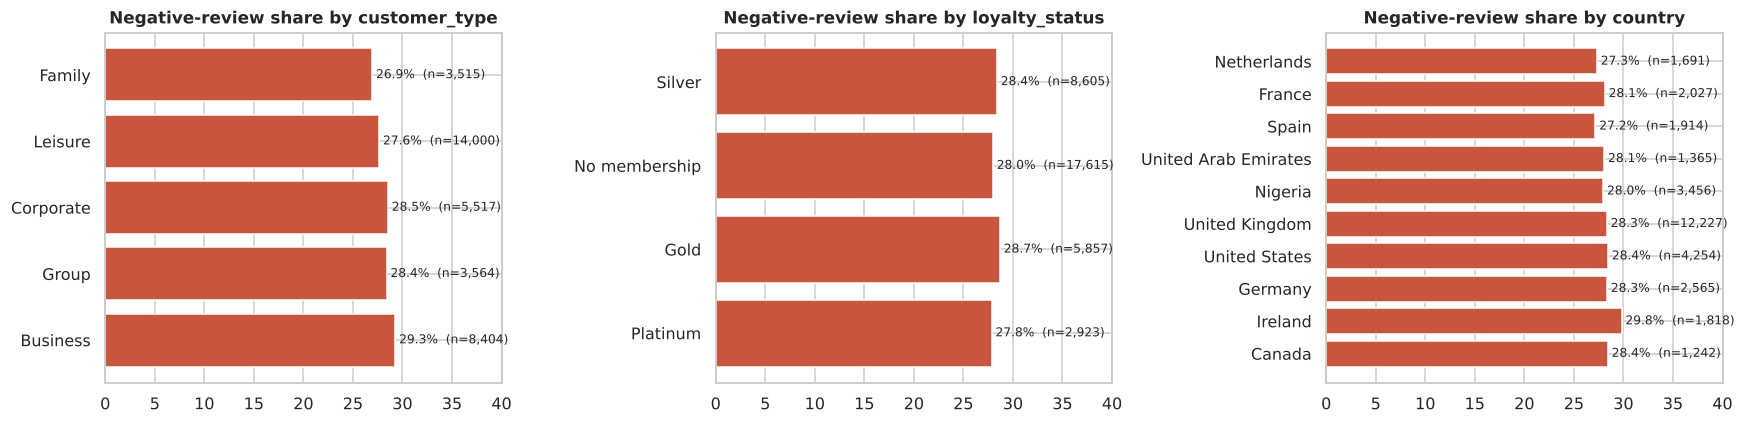

In [ ]:
eda["loyalty_status_f"] = eda["loyalty_status"].fillna("No membership")
top_c = eda["country"].value_counts().head(10).index
def seg_table(col, data=eda):
    return (data.groupby(col).agg(reviews=("review_id", "size"), avg_rating=("rating_score", "mean"),
            negative_share=("is_negative", "mean")).sort_values("avg_rating"))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, col, data in [(ax[0], "customer_type", eda), (ax[1], "loyalty_status_f", eda),
                     (ax[2], "country", eda[eda.country.isin(top_c)])]:
    t = seg_table(col, data)
    a.barh(t.index, t["negative_share"] * 100, color="#C8553D")
    for i, (v, n) in enumerate(zip(t["negative_share"], t["reviews"])):
        a.text(v * 100, i, f" {v:.1%}  (n={n:,})", va="center", fontsize=8)
    a.set_title(f"Negative-review share by {col.replace('_f','')}"); a.set_xlim(0, 40)
plt.tight_layout(); plt.show()

prev = eda.assign(prev_bin=pd.cut(eda.previous_stays, [-1, 0, 2, 5, 10, 100], labels=["0", "1–2", "3–5", "6–10", "10+"]))
seg_summary = pd.concat({c: seg_table(c, d) for c, d in [("customer_type", eda), ("loyalty_status_f", eda),
                          ("country (top 10)", eda[eda.country.isin(top_c)].rename(columns={"country": "country (top 10)"})),
                          ("previous_stays", prev.drop(columns="previous_stays").rename(columns={"prev_bin": "previous_stays"}))]})
display(seg_summary.style.format({"avg_rating": "{:.2f}", "negative_share": "{:.1%}", "reviews": "{:,}"}))

> **Insight — guest characteristics.**
> - Guest profile explains almost nothing about satisfaction. Average ratings by **customer type** range only 3.00 (Business) to 3.06 (Family). **Loyalty tier** spans 3.01–3.04 (Platinum guests are *not* happier). The top ten **countries** span 3.00–3.06, and **repeat stays** make no difference.
> - Negative-review shares cluster tightly around 27–29% in every segment.
> - **Implication:** dissatisfaction is driven by what happens *during* the stay (the property and its service), not by *who* the guest is. Segment analysis in Section 8 is still useful for targeting, but the levers are operational.

### 2.7 Booking characteristics

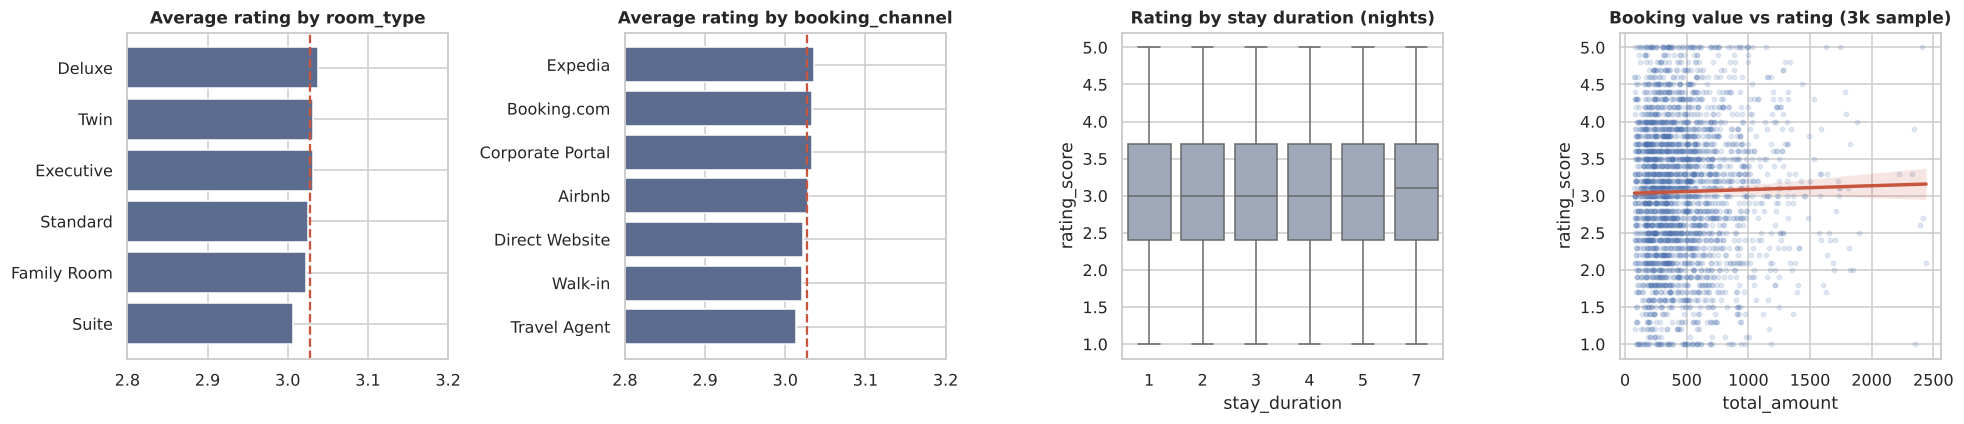

corr(rating, total_amount   ) = +0.003
corr(rating, stay_duration  ) = +0.008
corr(rating, previous_stays ) = +0.007
corr(rating, star_rating    ) = +0.182
corr(rating, total_rooms    ) = +0.074


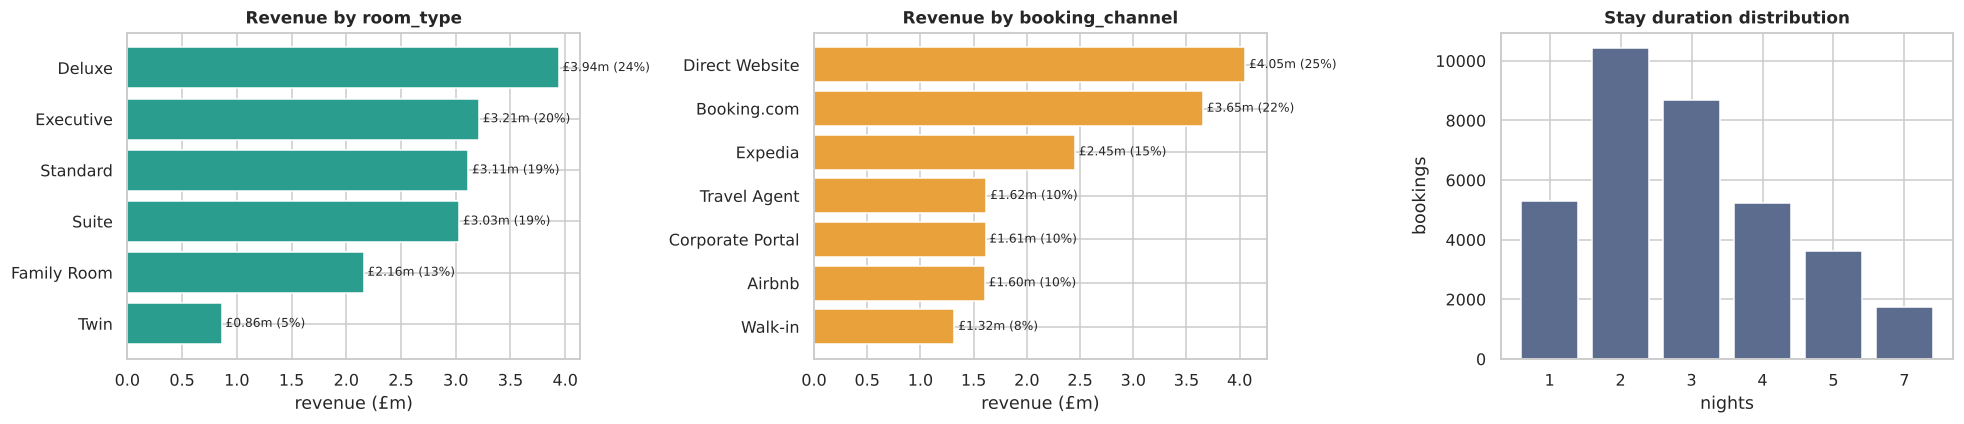

Total booking revenue: £16.31m | median stay 3 nights | 6-night stays: 0


In [ ]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, col in [(ax[0], "room_type"), (ax[1], "booking_channel")]:
    t = seg_table(col)
    a.barh(t.index, t["avg_rating"], color="#5B6C8F"); a.set_xlim(2.8, 3.2)
    a.axvline(eda.rating_score.mean(), ls="--", color="#C8553D"); a.set_title(f"Average rating by {col}")
sns.boxplot(data=eda, x="stay_duration", y="rating_score", color="#9AA8BF", ax=ax[2])
ax[2].set_title("Rating by stay duration (nights)")
samp = eda.sample(3000, random_state=SEED)
sns.regplot(data=samp, x="total_amount", y="rating_score", scatter_kws={"alpha": 0.15, "s": 8},
            line_kws={"color": "#C8553D"}, ax=ax[3])
ax[3].set_title("Booking value vs rating (3k sample)")
plt.tight_layout(); plt.show()
display(pd.concat({c: seg_table(c) for c in ["room_type", "booking_channel", "stay_duration"]})
        .style.format({"avg_rating": "{:.3f}", "negative_share": "{:.1%}", "reviews": "{:,}"}))
for c in ["total_amount", "stay_duration", "previous_stays", "star_rating", "total_rooms"]:
    print(f"corr(rating, {c:<15}) = {eda['rating_score'].corr(eda[c]):+.3f}")

# Commercial view (extends the booking EDA in data_extraction.ipynb): volume, revenue and value per booking
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
commercial = {}
for a, col, colour in [(ax[0], "room_type", "#2A9D8F"), (ax[1], "booking_channel", "#E9A23B")]:
    t = (bookings_raw.groupby(col).agg(bookings=("booking_id", "size"), revenue=("total_amount", "sum"),
                                       avg_booking_value=("total_amount", "mean"))
         .sort_values("revenue"))
    t["revenue_share"] = t["revenue"] / t["revenue"].sum()
    commercial[col] = t
    a.barh(t.index, t["revenue"] / 1e6, color=colour)
    for i, (v, sh) in enumerate(zip(t["revenue"] / 1e6, t["revenue_share"])):
        a.text(v, i, f" £{v:.2f}m ({sh:.0%})", va="center", fontsize=8)
    a.set_xlabel("revenue (£m)"); a.set_title(f"Revenue by {col}")
stay_counts = bookings_raw["stay_duration"].value_counts().sort_index()
ax[2].bar(stay_counts.index.astype(str), stay_counts.values, color="#5B6C8F")
ax[2].set_xlabel("nights"); ax[2].set_ylabel("bookings"); ax[2].set_title("Stay duration distribution")
plt.tight_layout(); plt.show()
display(pd.concat(commercial).style.format({"bookings": "{:,}", "revenue": "£{:,.0f}", "avg_booking_value": "£{:,.0f}", "revenue_share": "{:.1%}"}))
print(f"Total booking revenue: £{bookings_raw.total_amount.sum()/1e6:.2f}m | median stay {bookings_raw.stay_duration.median():.0f} nights "
      f"| 6-night stays: {int((bookings_raw.stay_duration == 6).sum())}")

> **Insight — booking characteristics.**
> - **Satisfaction:**
>   - **Room type** (3.01–3.04), **booking channel** (3.01–3.04) and **length of stay** (3.02–3.05) show no meaningful differences in rating.
>   - **Booking value is uncorrelated with satisfaction** (r = +0.003). Paying more does not buy a better-rated stay.
>   - Among the structured variables, only hotel **star rating (+0.18)** and **size (+0.07)** correlate with rating at all.
> - **Commercial view** (this extends the booking EDA started in `data_extraction.ipynb`): total booking revenue is **£16.31m**.
>   - **Deluxe** rooms earn the most (£3.94m, 24%).
>   - **Suites** are 10% of bookings but 19% of revenue, at an average of £855 a booking.
>   - **Standard** rooms are 30% of bookings but only 19% of revenue, at £294 a booking.
>   - **Average booking value is the same on every channel** (£459–472), so channel revenue simply mirrors volume. Direct Website (24.8%) and Booking.com (22.4%) bring in almost half of revenue.
> - **Stay length:** 2 nights is the most common (30%); the median is 3. **No booking lasts 6 nights**, although 7-night stays exist. That gap should be confirmed with the data owner.
> - **Implication:** revenue mix and satisfaction are decoupled. The highest-value rooms are rated no better than the cheapest, and structured booking data cannot explain why guests are satisfied, which validates the project's premise that the explanation lives in the text.

### 2.8 Ratings and review content: which words separate the sentiments?

negative : disappointed, left, turned, sadly, really, really affected, affected, affected stay, desired, left lot
neutral  : fine, fairly, expected, ordinary, unremarkable, stood way, hotel fine, fairly ordinary, fine unremarkable, unremarkable choice
positive : genuinely, honestly, genuinely impressed, impressed, expectations, exceeded expectations, exceeded, great, excellent, visiting


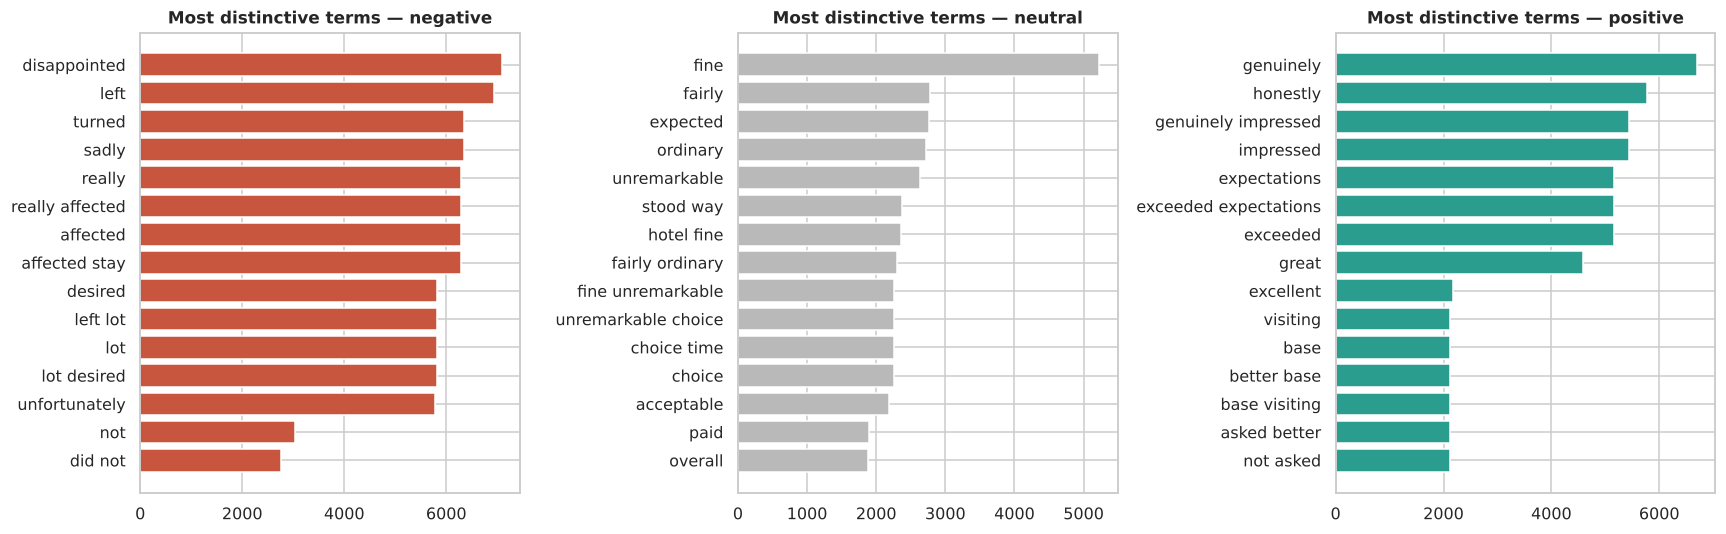

sentiment_label,negative %,neutral %,positive %
contrast connector (but/however/that said/on the other hand),36.1,40.2,28.7
negation (not/no/never/n't),47.9,18.5,12.4
hedging (fine/okay/acceptable/nothing special/as expected),19.5,81.9,18.6


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_selection import chi2

cv = CountVectorizer(ngram_range=(1, 2), min_df=20, binary=True, stop_words=list(STOP_WORDS - {"not", "no", "never"}))
X_terms = cv.fit_transform(preprocess_corpus(eda["review_text"], "standard"))
terms = np.array(cv.get_feature_names_out())
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
for a, s in zip(ax, SENT_ORDER):
    y = (eda["sentiment_label"] == s).astype(int)
    score, _ = chi2(X_terms, y)
    rate_in = np.asarray(X_terms[y.values == 1].mean(0)).ravel(); rate_out = np.asarray(X_terms[y.values == 0].mean(0)).ravel()
    keep = np.where(rate_in > rate_out)[0]                       # over-represented in this class only
    top = keep[np.argsort(-score[keep])[:15]][::-1]
    a.barh(terms[top], score[top], color=SENT_COLORS[s]); a.set_title(f"Most distinctive terms — {s}")
    print(f"{s:<9}:", ", ".join(terms[top][::-1][:10]))
plt.tight_layout(); plt.show()

markers = pd.DataFrame({
    "contrast connector (but/however/that said/on the other hand)": eda.review_text.str.contains(r"\b(?:but|however|that said|on the other hand|although)\b", case=False),
    "negation (not/no/never/n't)": eda.review_text.str.contains(r"\b(?:not|no|never)\b|n't", case=False),
    "hedging (fine/okay/acceptable/nothing special/as expected)": eda.review_text.str.contains(r"\b(?:fine|okay|acceptable|nothing special|about what we expected|standard)\b", case=False),
})
display((markers.groupby(eda["sentiment_label"]).mean().reindex(SENT_ORDER).T * 100).round(1).add_suffix(" %"))

> **Insight — what separates the sentiments in the text.**
> - **Negative** reviews are marked by *disappointed, left a lot to be desired, turned out, sadly, really affected the stay*.
> - **Neutral** by *fine, fairly ordinary, as expected, unremarkable*.
> - **Positive** by *genuinely impressed, exceeded expectations, great, excellent*.
> - **Negation** appears in **47.9%** of negative reviews against 12.4% of positive ones, so it is a genuine signal and must not be stripped carelessly.
> - **Hedging** language (*fine, acceptable, nothing special*) appears in **81.9%** of neutral reviews, but also in ~19% of positive and negative ones. That is why neutral will be the hardest class.
> - **Contrast connectors** (*but, however, that said*) appear in 29–40% of every class, a sign that reviews often discuss more than one aspect.

### 2.9 Correlation between numeric variables

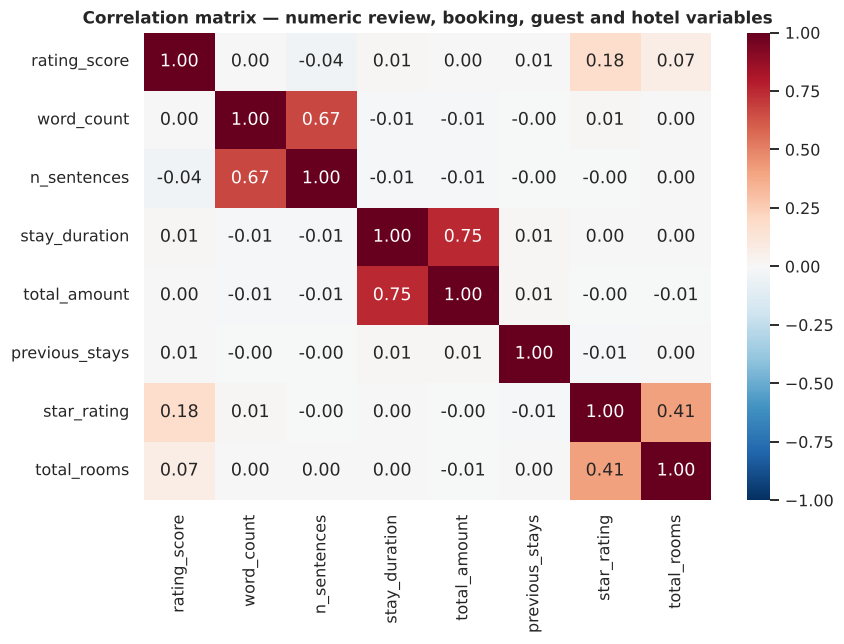

In [ ]:
num = eda[["rating_score", "word_count", "n_sentences", "stay_duration", "total_amount",
           "previous_stays", "star_rating", "total_rooms"]]
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation matrix — numeric review, booking, guest and hotel variables")
plt.tight_layout(); plt.show()

> **Insight — correlations.** Among all numeric variables, rating correlates only with hotel **star rating (0.18)** and **total rooms (0.07)**. Review length, stay duration, booking value and previous stays all sit at ~0. No pair of predictors is strongly correlated, so there is no multicollinearity to manage. The structured data is uninformative about satisfaction, and the information lives in the text.

### EDA summary

| Question | Finding |
|---|---|
| How is sentiment distributed? | Balanced: 38% neutral, 34% positive, 28% negative |
| Do labels match ratings? | 94.7%. About 5% of labels are probably noisy, which caps achievable accuracy |
| Is satisfaction changing over time? | No: flat ratings and sentiment for 18 months |
| What explains satisfaction in structured data? | Mainly the hotel and its star rating. Guest profile, room type, channel, stay length and price do not |
| What does the text tell us? | Distinct vocabularies per sentiment, heavy hedging in neutral reviews, negation concentrated in negative ones |
| What does this mean for modelling? | Work at sentence level, keep negation, use macro-F1, expect neutral to be hardest, and treat ~94–95% as the realistic accuracy ceiling |

---
# Phase 4 — Data Cleaning and Preparation (Objective 3)

**Goal:** a reliable, validated dataset for analytics and a clean, standardised text corpus for NLP. Every rule below is driven by a finding from Objectives 1–2, and every change is counted.

In [ ]:
df = df_raw.copy()
cleaning_log = []          # (step, rows affected, action)
def log(step, n, action): cleaning_log.append({"step": step, "rows affected": int(n), "action": action})

### 3.1 Missing values

In [ ]:
display(df.isna().sum()[df.isna().sum() > 0].rename("missing").to_frame()
        .assign(share=lambda t: (t.missing / len(df)).map("{:.1%}".format)))
n = df["loyalty_status"].isna().sum()
df["loyalty_status"] = df["loyalty_status"].fillna("No membership")
log("Missing loyalty_status", n, "Structural (guest not enrolled) → 'No membership'")
print("Missing values remaining:", int(df.isna().sum().sum()))

,missing,share
loyalty_status,17615,50.3%


Missing values remaining: 0


### 3.2 Duplicates

In [ ]:
exact_dups = df.duplicated().sum()
id_dups = df["review_id"].duplicated().sum()
dup_text_mask = df["review_text"].duplicated(keep=False)
groups = df[dup_text_mask].groupby("review_text")["sentiment_label"].nunique()
conflicting_texts = set(groups[groups > 1].index)
print(f"Exact duplicate rows: {exact_dups} | duplicate review_id: {id_dups}")
print(f"Identical review text: {dup_text_mask.sum():,} reviews in {df[dup_text_mask].review_text.nunique():,} text groups")
print(f"…of which text groups carrying CONFLICTING sentiment labels: {len(conflicting_texts)} "
      f"({df.review_text.isin(conflicting_texts).sum()} reviews)")
display(df[df.review_text.isin(conflicting_texts)].sort_values("review_text")[["review_id", "guest_id", "hotel_id", "review_text", "rating_score", "sentiment_label"]].head(6))

# Analytics table: keep all reviews (different guests/bookings — genuine, if templated, feedback).
# Modelling corpus (built in 3.7): one row per unique text, conflicting-label texts removed.
df["dup_text"] = dup_text_mask
df["conflicting_label_text"] = df["review_text"].isin(conflicting_texts)
log("Duplicate review text", dup_text_mask.sum(), "Kept for analytics; de-duplicated for modelling (prevents train/test leakage)")
log("Same text, conflicting labels", df.conflicting_label_text.sum(), "Excluded from the modelling corpus (contradictory supervision)")

Exact duplicate rows: 0 | duplicate review_id: 0
Identical review text: 829 reviews in 365 text groups
…of which text groups carrying CONFLICTING sentiment labels: 76 (196 reviews)


,review_id,guest_id,hotel_id,review_text,rating_score,sentiment_label
4307,4295,5488,23,I'd describe getting around from the hotel as fine — nothing was within walking distance but transport was easy enough.,2.2,negative
12424,12409,9550,2,I'd describe getting around from the hotel as fine — nothing was within walking distance but transport was easy enough.,2.6,neutral
22282,22266,8253,20,I'd describe getting around from the hotel as fine — nothing was within walking distance but transport was easy enough.,3.2,neutral
27072,27066,9270,11,I'd describe getting around from the hotel as fine — nothing was within walking distance but transport was easy enough.,3.3,negative
6511,6498,4758,8,I'd describe getting around from the hotel as not the most convenient but manageable — it was a short ride to most p...,2.8,neutral
8345,8330,2972,19,I'd describe getting around from the hotel as not the most convenient but manageable — it was a short ride to most p...,3.9,positive


### 3.3 Validity: ratings, identifiers, dates

In [ ]:
for c in ["review_date", "check_in_date", "check_out_date"]:
    df[c] = pd.to_datetime(df[c], errors="coerce")
validity = pd.DataFrame({
    "rule": ["rating_score within 1–5", "review_text not empty", "identifiers present",
             "dates parse", "review_date ≥ check_out_date", "stay_duration = check-out − check-in", "total_amount > 0"],
    "violations": [
        int((~df.rating_score.between(1, 5)).sum()),
        int((df.review_text.str.strip().str.len() == 0).sum()),
        int(df[["review_id", "booking_id", "guest_id", "hotel_id"]].isna().any(axis=1).sum()),
        int(df[["review_date", "check_in_date", "check_out_date"]].isna().any(axis=1).sum()),
        int((df.review_date < df.check_out_date).sum()),
        int(((df.check_out_date - df.check_in_date).dt.days != df.stay_duration).sum()),
        int((df.total_amount <= 0).sum()),
    ]})
validity["status"] = np.where(validity.violations == 0, "PASS", "FIX")
display(validity)
df["days_to_review"] = (df.review_date - df.check_out_date).dt.days
print("Days from check-out to review: median %d, max %d" % (df.days_to_review.median(), df.days_to_review.max()))

,rule,violations,status
0,rating_score within 1–5,0,PASS
1,review_text not empty,0,PASS
2,identifiers present,0,PASS
3,dates parse,0,PASS
4,review_date ≥ check_out_date,0,PASS
5,stay_duration = check-out − check-in,0,PASS
6,total_amount > 0,0,PASS


Days from check-out to review: median 7, max 14


### 3.4 Inconsistent values

In [ ]:
name_dupes = hotels_raw[hotels_raw.hotel_name.duplicated(keep=False)]
display(name_dupes)
df["hotel_label"] = df["hotel_name"]
amb = df.hotel_name.isin(name_dupes.hotel_name)
df.loc[amb, "hotel_label"] = df.loc[amb, "hotel_name"] + " (#" + df.loc[amb, "hotel_id"].astype(str) + ")"
log("Two hotels share one name", amb.sum(), "Disambiguated display name → 'Edinburgh Riverside Hotel (#9 / #14)'")

cat_cols = ["room_type", "booking_channel", "customer_type", "loyalty_status", "country", "location", "sentiment_label"]
changed = 0
for c in cat_cols:
    before = df[c].copy()
    df[c] = df[c].astype(str).str.strip()
    df[c] = df[c].str.lower() if c == "sentiment_label" else df[c]
    changed += int((before != df[c]).sum())
log("Categorical whitespace/case", changed, "Stripped and standardised")
print({c: df[c].nunique() for c in cat_cols})

,hotel_id,hotel_name,location,star_rating,total_rooms
8,9,Edinburgh Riverside Hotel,Edinburgh,3,71
13,14,Edinburgh Riverside Hotel,Edinburgh,3,215


{'room_type': 6, 'booking_channel': 7, 'customer_type': 5, 'loyalty_status': 4, 'country': 15, 'location': 14, 'sentiment_label': 3}


### 3.5 Text cleaning and normalisation

In [ ]:
n_unicode = df.review_text.str.contains(r"[^\x00-\x7F]").sum()
examples = df.loc[[1, 2], "review_text"].tolist()
for t in examples:
    print("ORIGINAL   :", t)
    for lvl in LEVELS:
        print(f"{lvl:<11}:", clean_text(t, lvl))
    print()
df["text_clean"] = preprocess_corpus(df["review_text"], "standard")
df["tokens"] = df["text_clean"].str.split()
log("Non-ASCII typography (em-dash, accented chars)", n_unicode, "Unicode-normalised to ASCII equivalents")
log("Review text", len(df), "Lower-cased, contractions expanded (negation kept as 'not'), punctuation/digits removed")
print("Tokens per review — mean %.1f, max %d | vocabulary size: %d"
      % (df.tokens.str.len().mean(), df.tokens.str.len().max(), len(set(w for t in df.tokens for w in t))))

ORIGINAL   : The room was nothing out of the ordinary for what we paid. The overall price exceeded our expectations — a great deal, and the quality easily matched the price.
minimal    : the room was nothing out of the ordinary for what we paid. the overall price exceeded our expectations - a great deal, and the quality easily matched the price.
standard   : the room was nothing out of the ordinary for what we paid the overall price exceeded our expectations a great deal and the quality easily matched the price
aggressive : room ordinary paid overall price exceeded expectations great deal quality easily matched price

ORIGINAL   : Unfortunately, the pool was outdated — it clearly needed some upkeep. Wouldn't recommend it to others.
minimal    : unfortunately, the pool was outdated - it clearly needed some upkeep. wouldn't recommend it to others.
standard   : unfortunately the pool was outdated it clearly needed some upkeep would not recommend it to others
aggressive : unfortunately poo

Tokens per review — mean 29.5, max 43 | vocabulary size: 513


### 3.6 Data quality validation with Great Expectations

In [ ]:
import great_expectations as gx
import logging; logging.getLogger("great_expectations").setLevel(logging.ERROR)

context = gx.get_context(mode="ephemeral")
batch = (context.data_sources.add_pandas("montra")
         .add_dataframe_asset(name="reviews_clean")
         .add_batch_definition_whole_dataframe("full")
         .get_batch(batch_parameters={"dataframe": df}))
E = gx.expectations
suite = [
    E.ExpectColumnValuesToBeUnique(column="review_id"),
    E.ExpectColumnValuesToNotBeNull(column="review_text"),
    E.ExpectColumnValuesToNotBeNull(column="loyalty_status"),
    E.ExpectColumnValuesToBeBetween(column="rating_score", min_value=1, max_value=5),
    E.ExpectColumnValuesToBeInSet(column="sentiment_label", value_set=SENT_ORDER),
    E.ExpectColumnValueLengthsToBeBetween(column="text_clean", min_value=20),
    E.ExpectColumnValuesToBeBetween(column="days_to_review", min_value=0),
    E.ExpectColumnValuesToBeBetween(column="stay_duration", min_value=1, max_value=30),
    E.ExpectColumnValuesToBeInSet(column="customer_type", value_set=["Leisure", "Business", "Corporate", "Group", "Family"]),
    E.ExpectTableRowCountToEqual(value=len(reviews_raw)),
]
import contextlib, io
res = []
for exp in suite:
    with contextlib.redirect_stderr(io.StringIO()):       # hide GX progress bars
        r = batch.validate(exp)
    res.append({"expectation": type(exp).__name__, "column": getattr(exp, "column", "—"),
                "success": r.success, "unexpected": r.result.get("unexpected_count", 0)})
gx_report = pd.DataFrame(res)
display(gx_report)
print(f"{gx_report.success.sum()}/{len(gx_report)} expectations passed")

,expectation,column,success,unexpected
0,ExpectColumnValuesToBeUnique,review_id,True,0
1,ExpectColumnValuesToNotBeNull,review_text,True,0
2,ExpectColumnValuesToNotBeNull,loyalty_status,True,0
3,ExpectColumnValuesToBeBetween,rating_score,True,0
4,ExpectColumnValuesToBeInSet,sentiment_label,True,0
5,ExpectColumnValueLengthsToBeBetween,text_clean,True,0
6,ExpectColumnValuesToBeBetween,days_to_review,True,0
7,ExpectColumnValuesToBeBetween,stay_duration,True,0
8,ExpectColumnValuesToBeInSet,customer_type,True,0
9,ExpectTableRowCountToEqual,—,True,0


10/10 expectations passed


### 3.7 Final datasets

In [ ]:
def rating_band(x): return "negative" if x < 2.5 else ("neutral" if x < 3.5 else "positive")
df["label_rating_conflict"] = df["sentiment_label"] != df["rating_score"].map(rating_band)

# (a) analytics table — every review with full context
analytics_cols = ["review_id", "booking_id", "guest_id", "hotel_id", "hotel_label", "location", "star_rating",
                  "review_date", "review_text", "text_clean", "rating_score", "sentiment_label",
                  "room_type", "booking_channel", "stay_duration", "total_amount", "check_in_date",
                  "customer_type", "loyalty_status", "country", "previous_stays", "label_rating_conflict"]
reviews_clean = df[analytics_cols].copy()
reviews_clean.to_csv(PROC_DIR / "reviews_clean.csv", index=False)

# (b) NLP modelling corpus — one row per unique text, contradictory labels removed
nlp_corpus = (df[~df.conflicting_label_text].drop_duplicates("review_text")
              [["review_id", "review_text", "text_clean", "rating_score", "sentiment_label", "label_rating_conflict"]])
nlp_corpus.to_csv(PROC_DIR / "nlp_corpus.csv", index=False)
log("Modelling corpus", len(df) - len(nlp_corpus), "Rows removed by de-duplication / label conflicts")

print(f"reviews_clean.csv : {reviews_clean.shape}")
print(f"nlp_corpus.csv    : {nlp_corpus.shape}")
display(pd.DataFrame(cleaning_log))
display(nlp_corpus.sentiment_label.value_counts(normalize=True).reindex(SENT_ORDER).rename("share").map("{:.1%}".format).to_frame())

reviews_clean.csv : (35000, 22)
nlp_corpus.csv    : (34460, 6)


,step,rows affected,action
0,Missing loyalty_status,17615,Structural (guest not enrolled) → 'No membership'
1,Duplicate review text,829,Kept for analytics; de-duplicated for modelling (prevents train/test leakage)
2,"Same text, conflicting labels",196,Excluded from the modelling corpus (contradictory supervision)
3,Two hotels share one name,2909,Disambiguated display name → 'Edinburgh Riverside Hotel (#9 / #14)'
4,Categorical whitespace/case,0,Stripped and standardised
5,"Non-ASCII typography (em-dash, accented chars)",12398,Unicode-normalised to ASCII equivalents
6,Review text,35000,"Lower-cased, contractions expanded (negation kept as 'not'), punctuation/digits removed"
7,Modelling corpus,540,Rows removed by de-duplication / label conflicts


,share
sentiment_label,
negative,28.2%
neutral,37.9%
positive,33.9%


> **Insight — Objective 3 (Cleaning and preparation).**
> - **Missing values:** the only gap, `loyalty_status` (17,615 review rows), was structural and is now *No membership*. No rows were dropped.
> - **Duplicates:**
>   - No duplicate rows or IDs.
>   - **829 reviews share their text with another review** (365 text groups, from different guests at different hotels). They are kept for analytics because they are genuine feedback.
>   - They are **de-duplicated for modelling**, so the same sentence can never appear in both training and test data and inflate the scores.
>   - **76 of those groups carry contradictory labels** (196 reviews: identical text labelled negative *and* neutral). These are removed from the modelling corpus because no model can learn from contradictory supervision. This is a second confirmation of the label noise seen in 2.2.
> - **Validity:** ratings are all within 1–5, identifiers are complete, every date parses, every review is posted 0–14 days after check-out (median 7), stay lengths match the check-in/check-out dates, and all amounts are positive.
> - **Inconsistencies:** two different hotels (#9, 71 rooms, and #14, 215 rooms) are both called *Edinburgh Riverside Hotel*. They are now labelled separately, so their 2,909 reviews are never merged in hotel rankings.
> - **Text:**
>   - 12,398 reviews contained typographic characters (em-dashes, accents), which are now normalised.
>   - Contractions are expanded so negation survives as an explicit *not* ("wouldn't" → "would not").
>   - The standardised pipeline lives in `src/text_preprocessing.py`, so the notebook, the experiments and the saved model all clean text identically.
> - **Validation:** **10/10 Great Expectations checks pass** on the cleaned table.
>
> **Conclusion:** the deliverables are a validated analytics table (`reviews_clean.csv`, 35,000 rows), a leakage-free **NLP corpus (`nlp_corpus.csv`, 34,460 unique reviews)**, and a reusable **preprocessing pipeline**. The source data was already of high technical quality. The real quality issue is the **~5% of labels that disagree with their rating**, which is carried forward as a flag (`label_rating_conflict`) for the error analysis.

---
# Phase 5 — Topic Modelling with BERTopic (Objective 4)

**Goal:** discover the recurring themes guests write about, using BERTopic (transformer embeddings → UMAP → HDBSCAN clustering → c-TF-IDF topic representations), and turn them into business aspects management can act on.

**Two design decisions, both driven by the EDA:**
1. **Model sentences, not whole reviews.** Most reviews contain two or three sentences, each about a different aspect of the stay, and more than a third pivot with "but / however / that said". A whole-review topic would blur, say, "great breakfast" and "rude staff" into one cluster.
2. **Cluster on aspect words, not on sentiment words.** The same aspect is described with heavily templated praise or complaint phrases. Left in, these phrases dominate the embeddings and topics form around *how* something is said ("left a lot to be desired") rather than *what* it is about. Aspect words are identified from the data: a word that appears equally in positive, neutral and negative sentences (*pool, breakfast, desk*) describes an aspect, while a word concentrated in one sentiment class (*outdated, spotless, fair*) describes an opinion. Evaluative words that the aspect lexicon needs for validation (*spotless, rude, overpriced, convenient*) are removed from the clustering text as well: they say how something is judged, not what it is, and left in they would group *"the pool was spotless"* with *"the room was spotless"*. What remains is what each sentence is about (*pool*, *breakfast*, *check-in desk*). Sentiment is analysed separately in Objective 5. Configuration A below tests this choice explicitly.

### 4.1 Sentence-level corpus

In [ ]:
rows = []
for rid, txt in zip(reviews_clean["review_id"], reviews_clean["review_text"]):
    for i, s in enumerate(split_sentences(txt)):
        rows.append((rid, i, s, strip_connectors(s)))
sentences = pd.DataFrame(rows, columns=["review_id", "sent_idx", "sentence_raw", "sentence"])
sentences["key"] = sentences["sentence"].str.lower()
sent_freq = sentences["key"].value_counts()
print(f"{len(sentences):,} sentences from {sentences.review_id.nunique():,} reviews "
      f"({len(sentences)/sentences.review_id.nunique():.2f} per review)")
print(f"Unique sentences: {sentences.key.nunique():,} ({sentences.key.nunique()/len(sentences):.1%}). The corpus is highly templated,")
print("so each unique sentence is embedded and clustered once, then mapped back to every review that contains it.")
display(sentences.head(6)[["review_id", "sent_idx", "sentence_raw", "sentence"]])

85,829 sentences from 35,000 reviews (2.45 per review)
Unique sentences: 6,764 (7.9%). The corpus is highly templated,
so each unique sentence is embedded and clustered once, then mapped back to every review that contains it.


,review_id,sent_idx,sentence_raw,sentence
0,1,0,The overall price was fair for what we paid.,The overall price was fair for what we paid.
1,1,1,"Might consider it again, might not.","Might consider it again, might not."
2,2,0,The room was nothing out of the ordinary for what we paid.,The room was nothing out of the ordinary for what we paid.
3,2,1,"The overall price exceeded our expectations - a great deal, and the quality easily matched the price.","The overall price exceeded our expectations - a great deal, and the quality easily matched the price."
4,3,0,"Unfortunately, the pool was outdated - it clearly needed some upkeep.",the pool was outdated - it clearly needed some upkeep.
5,3,1,Wouldn't recommend it to others.,Wouldn't recommend it to others.


### 4.2 Separating aspect words from sentiment words

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

lab = sentences.merge(reviews_clean[["review_id", "sentiment_label"]], on="review_id")

PHRASES = [  # multi-word expressions whose meaning is lost if the words are read separately
    (r"getting around( from the hotel)?", "transport"),
    (r"surrounding area|local area", "neighborhood"),
    (r"(bathroom|shower) area", r"\1"),
    (r"common areas?", "commonareas"),
    (r"room service", "roomservice"),
    (r"in-house|in house", "inhouse"),
    (r"\b(business|conference|solo|anniversary|family|weekend|work) (trip|stopover|getaway|holiday|escape)\b", "trip"),
    (r"wi-fi", "wifi"),
    # "staff" mentioned only in passing, while the sentence is about something else
    (r"staff kept it in great condition", "it was kept in great condition"),        # a facility or room
    (r"staff must clean", "it must be cleaned"),                                     # cleanliness
    (r"the staff had everything prepared", "everything was prepared"),               # check-in
    (r"point out to staff", "point out"),                                            # cleanliness complaint
]
def normalise_phrases(t: str) -> str:
    t = t.lower()
    for pattern, repl in PHRASES:
        t = re.sub(pattern, repl, t)
    return t

# Polarity skew: how far a word's sentence-level label mix departs from the overall label mix.
# Aspect nouns (pool, breakfast, desk) appear in positive, neutral and negative sentences alike -> skew ~ 0.
# Opinion words (outdated, spotless, fair) are concentrated in one class -> high skew.
cvp = CountVectorizer(binary=True, min_df=20)
Xp = cvp.fit_transform(lab["sentence"].map(lambda t: clean_text(normalise_phrases(t))))
vocab = np.array(cvp.get_feature_names_out())
Y = pd.get_dummies(lab["sentiment_label"])[SENT_ORDER].values.astype(float)
df_w = np.asarray(Xp.sum(0)).ravel()
skew = np.abs((Xp.T @ Y) / df_w[:, None] - Y.mean(0)).max(axis=1)
word_skew = pd.Series(skew, index=vocab).sort_values()
SKEW_THRESHOLD = 0.12

ASPECT_LEXICON = {
    "Staff & Service":      {"staff", "team", "service", "manager", "receptionist", "concierge", "request", "names", "luggage",
                             "friendly", "professional", "courteous", "rude", "unhelpful", "helpful", "complaints", "attentive",
                             "welcoming", "polite", "dismissive", "indifferent", "overworked", "respond", "night", "bartender"},
    "Cleanliness":          {"clean", "dusty", "musty", "stained", "neglected", "spotless", "scrubbed", "wiped", "unhygienic",
                             "hygiene", "dirty", "housekeeping", "freshly", "sparkling", "grubby", "unkempt", "kept", "tidy",
                             "grimy", "filthy", "immaculate", "pristine", "gleaming", "spick"},
    "Rooms & Common Areas": {"room", "suite", "bed", "bedding", "carpet", "bathroom", "decor", "cor", "comfortable", "quiet",
                             "noise", "shower", "commonareas", "furniture"},
    "Food & Dining":        {"breakfast", "buffet", "restaurant", "dining", "cafe", "food", "pastries", "dishes", "menu",
                             "dinner", "fare", "edible", "variety", "roomservice", "inhouse"},
    "Location & Transport": {"location", "neighborhood", "surrounding", "central", "transport", "city", "situated", "links",
                             "car", "parking", "reach", "nearby", "walk", "public", "convenient", "placed", "exploring"},
    # "worth" is deliberately absent: guests use it for food ("worth waking up early for") as often as for price
    "Pricing & Value":      {"price", "cost", "rate", "pricing", "value", "deal", "affordable", "overpriced",
                             "expensive", "charge", "amenities", "money"},
    "Facilities":           {"pool", "gym", "fitness", "spa", "lounge", "business", "center", "facilities", "wifi", "wi",
                             "fi", "equipped", "equipment", "connection"},
    "Check-in & Arrival":   {"check", "checkin", "checked", "arrival", "desk", "queue", "ready", "process", "front", "waited"},
}
ASPECT_WORDS = set().union(*ASPECT_LEXICON.values())
# Lexicon words that judge rather than name: needed to validate a sentence's aspect (4.6), but kept out of the
# clustering text so that topics form around WHAT guests discuss, not how they judge it.
ASPECT_DESCRIPTORS = {
    "friendly", "professional", "courteous", "rude", "unhelpful", "helpful", "attentive", "welcoming", "polite",
    "dismissive", "indifferent", "overworked", "respond", "complaints",
    "clean", "dusty", "musty", "stained", "neglected", "spotless", "scrubbed", "wiped", "unhygienic", "dirty",
    "freshly", "sparkling", "grubby", "unkempt", "kept", "tidy", "grimy", "filthy", "immaculate", "pristine",
    "gleaming", "spick", "comfortable", "quiet", "noise", "edible", "central", "convenient", "situated", "placed",
    "exploring", "reach", "nearby", "affordable", "overpriced", "expensive", "equipped", "waited"}
CITY_WORDS = {c.lower() for c in hotels_raw["location"].unique()}
GENERIC = {"hotel", "hotels", "stay", "time", "overall", "experience", "options", "similar", "recommend", "travelers",
           "trip", "solo", "conference", "work", "stopover", "romantic", "escape", "anniversary", "family", "holiday",
           "weekend", "getaway", "quick", "visit", "town", "booking", "needed", "paid", "getting", "area"}
ASPECT_VOCAB_WITH_DESCRIPTORS = ({w for w, sk in word_skew.items() if sk < SKEW_THRESHOLD}
                                  - set(STOP_WORDS) - CITY_WORDS - GENERIC) | ASPECT_WORDS
ASPECT_VOCAB = ASPECT_VOCAB_WITH_DESCRIPTORS - ASPECT_DESCRIPTORS

def aspect_text(sentence: str, vocab=None) -> str:
    """Keep only aspect vocabulary: low-polarity-skew content words plus the lexicon's aspect nouns."""
    vocab = ASPECT_VOCAB if vocab is None else vocab
    return " ".join(w for w in clean_text(normalise_phrases(sentence)).split() if w in vocab)

uniq = sentences.drop_duplicates("key")[["key", "sentence"]].copy()
uniq["aspect_text"] = uniq["sentence"].map(aspect_text)
uniq["aspect_desc"] = uniq["sentence"].map(lambda t: aspect_text(t, ASPECT_VOCAB_WITH_DESCRIPTORS))   # shown for comparison only
uniq["freq"] = uniq["key"].map(sent_freq)
uniq["clean"] = uniq["sentence"].map(lambda t: clean_text(normalise_phrases(t)))
print(f"Aspect vocabulary: {len(ASPECT_VOCAB)} words (polarity skew < {SKEW_THRESHOLD} or an aspect noun of the lexicon; "
      f"{len(ASPECT_DESCRIPTORS)} evaluative lexicon words excluded)")
print("Lowest-skew words (aspects):  ", ", ".join(word_skew.drop(list(CITY_WORDS & set(word_skew.index)), errors="ignore").index[:20]))
print("Highest-skew words (opinions):", ", ".join(word_skew.index[::-1][:20]))
display(uniq.sample(8, random_state=3)[["sentence", "aspect_desc", "aspect_text"]]
        .rename(columns={"aspect_desc": "with evaluative words", "aspect_text": "aspect_text (what the vector is pooled over)"}))
overall_share = (uniq.loc[uniq.aspect_text.str.strip() == "", "freq"].sum() / uniq.freq.sum())
print(f"Sentences with no aspect words left (overall-impression statements, e.g. 'We had a wonderful time…'): {overall_share:.1%}")

Aspect vocabulary: 80 words (polarity skew < 0.12 or an aspect noun of the lexicon; 52 evaluative lexicon words excluded)
Lowest-skew words (aspects):   pricing, staff, commonareas, restaurant, suite, facilities, fitness, checked, getting, neighborhood, pool, process, in, buffet, breakfast, receptionist, arrival, bedding, night, the
Highest-skew words (opinions): nightmare, car, indifferent, from, shelves, dust, tag, match, scrubbed, little, dark, around, outdated, unkempt, frustrating, inconveniently, reach, grimy, slowly, moved


,sentence,with evaluative words,aspect_text (what the vector is pooled over)
11085,We were disappointed that our suite was dusty.,suite dusty,suite
5640,"the Wi-Fi was standard, nothing more and nothing less.",wifi,wifi
12912,the business center was poorly maintained - it clearly needed some upkeep.,business center maintained,business center maintained
36504,"the night staff exceeded our expectations - warm and welcoming, and nothing was ever too much trouble for them.",night staff welcoming,night staff
7983,the front desk team was professional and courteous.,front desk team professional courteous,front desk team
1633,"The concierge was fine, nothing special for what we paid.",concierge,concierge
21402,"the in-house cafe exceeded our expectations - impressively varied, and the pastries alone were worth the stay.",inhouse cafe pastries,inhouse cafe pastries
6032,"the overall price was surprisingly affordable given the quality, and the quality easily matched the price.",price affordable price,price price


Sentences with no aspect words left (overall-impression statements, e.g. 'We had a wonderful time…'): 29.4%


### 4.3 Sentence embeddings focused on the aspect

Each unique sentence is turned into a transformer embedding, a 768-number vector that places sentences about similar things close together. BERTopic then clusters these vectors.

**Aspect-focused pooling.** The transformer reads the **whole sentence**, so every word is understood in context, but the sentence vector is the average of the token vectors of its **aspect words only** (the `aspect_text` words from 4.2). *"The pool was outdated"* and *"the pool was superb"* therefore land next to each other (both are about the pool), while *"the pool was outdated"* and *"the gym was outdated"* do not. A plain average over all tokens is kept as configuration A, to show what happens when sentiment words drive the clustering.

**Model, in order of preference:**
1. **cached embeddings** from a previous run (`data/processed/sentence_embeddings.npz`), so re-runs reproduce the same topics
2. **sentence-transformers `all-MiniLM-L6-v2`**, a model trained specifically for sentence similarity (last layer)
3. **`TRANSFORMER_MODEL` (RoBERTa-base)**, using the average of hidden layers 4–8: the last layers of a pre-trained transformer specialise in its training task, while middle layers carry more general word meaning. Its vectors are post-processed with "all-but-the-top" (the mean and the top two principal components are removed), because raw BERT-family vectors all point in a few shared directions, which makes every text look alike.
4. a TF-IDF + SVD fallback, so the notebook still runs fully offline

A TF-IDF embedding of the aspect words is also computed as a non-transformer **benchmark** for 4.4. The backend actually used is printed and logged to MLflow with every topic model.

In [ ]:
import hashlib
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

EMB_CACHE_PATH = PROC_DIR / "sentence_embeddings.npz"
_EMB_CACHE = {}
EMB_VERSION = "tokpool_v1"      # part of the cache key: changing the pooling recipe invalidates old caches
ST_MODEL = "sentence-transformers/all-MiniLM-L6-v2"

def _texts_key(texts, tag):
    return f"{tag}_{hashlib.sha1((EMB_VERSION + chr(10) + chr(10).join(texts)).encode()).hexdigest()[:16]}"

def all_but_the_top(E, n_components=2):
    """Raw BERT-family vectors share a few dominant directions ('anisotropy'), which makes every sentence look
    similar. Removing the mean and the top principal components (Mu & Viswanath, 2018) restores useful similarity."""
    from sklearn.decomposition import PCA
    X = E - E.mean(axis=0)
    P = PCA(n_components, random_state=SEED).fit(X).components_
    return normalize(X - X @ P.T @ P)

def _pooled(texts, model_name, layers, focus_vocab=None, batch_size=64):
    """One vector per text: the transformer reads the whole (whitespace-tokenised) text; token vectors from `layers`
    are averaged over the words in `focus_vocab` only (all words if None)."""
    import torch
    from transformers import AutoTokenizer, AutoModel
    try:
        tok = AutoTokenizer.from_pretrained(model_name, add_prefix_space=True)   # needed for RoBERTa on word lists
    except Exception:
        tok = AutoTokenizer.from_pretrained(model_name)
    mdl = AutoModel.from_pretrained(model_name, output_hidden_states=True).eval()
    words = [t.split() for t in texts]
    out = []
    with torch.no_grad():
        for i in range(0, len(words), batch_size):
            batch = words[i:i + batch_size]
            enc = tok(batch, is_split_into_words=True, padding=True, truncation=True, max_length=96, return_tensors="pt")
            hs = mdl(**enc).hidden_states
            H = torch.stack([hs[l] for l in layers]).mean(0)
            for j, ws in enumerate(batch):
                ids = enc.word_ids(j)
                keep = [k for k, w in enumerate(ids) if w is not None and (focus_vocab is None or ws[w] in focus_vocab)]
                keep = keep or [k for k, w in enumerate(ids) if w is not None]
                out.append(H[j, keep].mean(0).numpy())
    return np.vstack(out)

def get_embeddings(texts, backend=EMBEDDING_BACKEND, tag="", focus_vocab=None):
    texts = list(texts)
    key = _texts_key(texts, tag)
    if key in _EMB_CACHE:
        return _EMB_CACHE[key]
    stored = dict(np.load(EMB_CACHE_PATH, allow_pickle=True)) if EMB_CACHE_PATH.exists() else {}
    if backend == "auto" and key in stored:
        out = (stored[key].astype(np.float32), str(stored[key + "__backend"]))
        print(f"[{tag}] loaded cached embeddings ({out[1]}) from {EMB_CACHE_PATH.name}")
        _EMB_CACHE[key] = out
        return out
    out, t0 = None, time.time()
    if backend in ("auto", "sentence-transformers"):
        try:
            out = (normalize(_pooled(texts, ST_MODEL, layers=[-1], focus_vocab=focus_vocab)),
                   "sentence-transformers / all-MiniLM-L6-v2")
        except Exception as e:
            print(f"[{tag}] all-MiniLM-L6-v2 unavailable ({type(e).__name__}) → trying {TRANSFORMER_LABEL}")
    if out is None and backend in ("auto", "transformer"):
        try:
            out = (all_but_the_top(_pooled(texts, TRANSFORMER_MODEL, layers=range(4, 9), focus_vocab=focus_vocab)),
                   f"{TRANSFORMER_LABEL} (layers 4-8, all-but-the-top)")
        except Exception as e:
            print(f"[{tag}] {TRANSFORMER_LABEL} unavailable ({type(e).__name__}) → TF-IDF + SVD fallback")
    if out is None:
        tf = TfidfVectorizer(sublinear_tf=True, min_df=1).fit_transform(texts)
        out = (normalize(TruncatedSVD(n_components=min(100, tf.shape[1] - 1), random_state=SEED).fit_transform(tf)),
               "tfidf-svd")
    else:
        print(f"[{tag}] embedded {len(texts):,} texts with {out[1]} in {time.time() - t0:.0f}s")
    out = (out[0].astype(np.float16).astype(np.float32), out[1])     # use exactly what is cached, so re-runs reproduce
    if backend == "auto":                                           # the cheap TF-IDF benchmark is never cached
        stored[key], stored[key + "__backend"] = out[0].astype(np.float16), np.array(out[1])   # float16 halves the size
        np.savez_compressed(EMB_CACHE_PATH, **stored)
    _EMB_CACHE[key] = out
    return out

model_docs = uniq[uniq.aspect_text.str.strip() != ""].reset_index(drop=True)
# What each configuration clusters. "doc" is the text BERTopic describes with c-TF-IDF (topic words);
# the embedding decides which sentences are grouped together.
aspect_strings = (model_docs.groupby("aspect_text", sort=True).agg(freq=("freq", "sum")).reset_index()
                  .rename(columns={"aspect_text": "doc"}))
FIT_UNITS = {"all_tokens":    model_docs.assign(doc=model_docs["clean"])[["doc", "freq"]],
             "aspect_tokens": model_docs.assign(doc=model_docs["aspect_text"])[["doc", "freq"]],
             # identical aspect strings have identical TF-IDF vectors, so the benchmark clusters each distinct string once
             "aspect_strings": aspect_strings}
EMB = {"all_tokens": get_embeddings(model_docs["clean"].tolist(), tag="all_tokens")[0]}
EMB["aspect_tokens"], EMB_NAME = get_embeddings(model_docs["clean"].tolist(), tag="aspect_tokens", focus_vocab=ASPECT_VOCAB)
EMB["aspect_strings"], _ = get_embeddings(aspect_strings["doc"].tolist(), backend="tfidf-svd", tag="tfidf_benchmark")
print(f"Embedding backend: {EMB_NAME} | {EMB['aspect_tokens'].shape[0]:,} unique sentences × {EMB['aspect_tokens'].shape[1]} dimensions")
print(f"TF-IDF benchmark: {len(aspect_strings):,} distinct aspect strings")

[all_tokens] loaded cached embeddings (RoBERTa-base (layers 4-8, all-but-the-top)) from sentence_embeddings.npz


[aspect_tokens] loaded cached embeddings (RoBERTa-base (layers 4-8, all-but-the-top)) from sentence_embeddings.npz


Embedding backend: RoBERTa-base (layers 4-8, all-but-the-top) | 6,575 unique sentences × 768 dimensions
TF-IDF benchmark: 243 distinct aspect strings


### 4.4 Topic modelling configuration experiments

| Config | Sentence vector | HDBSCAN `min_cluster_size` | Topic reduction |
|---|---|---|---|
| A | transformer, averaged over **all** tokens (sentiment words included) | 80 | none |
| B | transformer, averaged over **aspect** tokens | 40 | none |
| C | transformer, averaged over aspect tokens | 80 | none |
| D | transformer, averaged over aspect tokens | 120 | none |
| E | transformer, averaged over aspect tokens | 80 | merged to 30 topics |
| F | TF-IDF of the aspect words (benchmark) | 3 distinct strings | none |

All configurations cluster the 6,575 unique sentences, except the TF-IDF benchmark: identical aspect strings have identical TF-IDF vectors, so it clusters each of the few hundred distinct strings once (hence the small `min_cluster_size`).

**Evaluation**, weighted by how often each sentence occurs:
- **Coherence (NPMI):** do a topic's top words actually co-occur in sentences? Higher means more interpretable.
- **Diversity:** share of unique words across all topics' top-10 lists. Higher means less overlap between topics.
- **Aspect purity:** how cleanly each topic maps to one business aspect. Higher means more actionable.
- **Outlier share:** sentences HDBSCAN refuses to assign. Lower is better.
- **Sentiment leakage:** how far each topic's mix of positive, neutral and negative sentences departs from the overall mix. An aspect topic such as *breakfast* contains praise, neutral remarks and complaints. A topic made of only complaints is a sentiment cluster, not a theme. Lower is better.

**Selection rule:** among the transformer-embedding configurations (A–E), at most 35% outliers, then the highest *coherence + diversity + aspect purity − sentiment leakage*.

**Why the TF-IDF benchmark (F) is reported but not selectable.** TF-IDF clusters sentences by their exact words. Coherence and aspect purity are also computed from exact words, so these metrics partly measure TF-IDF against itself and will tend to favour it. On a templated corpus like this one TF-IDF looks strong. But it cannot recognise that *spotless* and *immaculate*, or *rude* and *dismissive*, mean the same, which matters as soon as real guests write in their own words. F is therefore a reference point: it shows how much of the topic structure plain word overlap already explains.

Every run is logged to MLflow (`montra-topic-modelling`).

In [ ]:
import mlflow
from bertopic import BERTopic
from umap import UMAP
from hdbscan import HDBSCAN
from scipy import sparse

TRACKING_URI = f"sqlite:///{(MLRUNS_DIR / 'mlflow.db').as_posix()}"
mlflow.set_tracking_uri(TRACKING_URI)
def use_experiment(name):
    exp = mlflow.get_experiment_by_name(name)
    if exp is None:
        mlflow.create_experiment(name, artifact_location=(MLRUNS_DIR / "artifacts" / name).resolve().as_uri())
    mlflow.set_experiment(name)

# Reference corpus for coherence: binary word presence in every cleaned unique sentence
ref_cv = CountVectorizer(binary=True, min_df=2)
REF = ref_cv.fit_transform(model_docs["clean"]).tocsc()
REF_IDX = {w: i for i, w in enumerate(ref_cv.get_feature_names_out())}
N_REF = REF.shape[0]

def npmi_coherence(topic_words):
    scores = []
    for words in topic_words:
        ids = [REF_IDX[w] for w in words if w in REF_IDX][:10]
        for a in range(len(ids)):
            for b in range(a + 1, len(ids)):
                ca, cb = REF[:, ids[a]], REF[:, ids[b]]
                pa, pb = ca.sum() / N_REF, cb.sum() / N_REF
                pab = ca.multiply(cb).sum() / N_REF
                if pab == 0:
                    scores.append(-1.0)
                else:
                    scores.append(np.log(pab / (pa * pb)) / -np.log(pab))
    return float(np.mean(scores)) if scores else np.nan

def map_aspect(word_weights):
    """Score a topic against the business-aspect lexicon using its c-TF-IDF word weights."""
    scores = dict.fromkeys(ASPECT_LEXICON, 0.0)
    for w, wt in word_weights:
        for tok in w.split():
            for a, lex in ASPECT_LEXICON.items():
                if tok in lex:
                    scores[a] += wt
    total = sum(scores.values())
    best = max(scores, key=scores.get)
    return (best, scores[best] / total) if total > 0 else ("Other", 0.0)

def keyword_aspect(txt):
    """Transparent lexicon rule: the aspect with the most lexicon words in the sentence."""
    hits = {a: sum(w in lex for w in txt.split()) for a, lex in ASPECT_LEXICON.items()}
    best = max(hits, key=hits.get)
    return best if hits[best] > 0 else "Other"

def fit_bertopic(docs, emb, min_cluster_size, nr_topics=None):
    tm = BERTopic(
        umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=SEED),
        hdbscan_model=HDBSCAN(min_cluster_size=min_cluster_size, min_samples=min(5, min_cluster_size), prediction_data=True),
        vectorizer_model=CountVectorizer(ngram_range=(1, 2), min_df=1, stop_words=list(STOP_WORDS)),
        nr_topics=nr_topics, calculate_probabilities=False, verbose=False)
    topics, _ = tm.fit_transform(docs, emb)
    return tm, np.asarray(topics)

# label mix of every unique sentence (from the review it belongs to) for the sentiment-leakage metric
_lab = sentences.merge(reviews_clean[["review_id", "sentiment_label"]], on="review_id")
LABEL_MIX = pd.crosstab(_lab["key"], _lab["sentiment_label"])[SENT_ORDER]
LABEL_PRIOR = _lab["sentiment_label"].value_counts(normalize=True)[SENT_ORDER].values

def sentiment_leakage(topics):
    d = model_docs.assign(topic=topics)
    d = d[d.topic != -1]
    counts = pd.DataFrame(LABEL_MIX.reindex(d["key"]).fillna(0).values, columns=SENT_ORDER).assign(topic=d["topic"].values)
    t = counts.groupby("topic")[SENT_ORDER].sum(); size = t.sum(axis=1)
    return float((np.abs(t.div(size, axis=0).values - LABEL_PRIOR).max(axis=1) * size).sum() / size.sum())

def evaluate_topics(tm, topics, weights):
    tids = [t for t in tm.get_topics() if t != -1]
    words = [[w for w, _ in tm.get_topic(t) if w and " " not in w][:10] for t in tids]   # unigrams; skip c-TF-IDF padding
    flat = [w for ws in words for w in ws]
    purity = [map_aspect(tm.get_topic(t))[1] for t in tids]
    return {"n_topics": len(tids),
            "outlier_share": float(weights[topics == -1].sum() / weights.sum()),
            "coherence_npmi": npmi_coherence(words),
            "diversity": len(set(flat)) / max(len(flat), 1),
            "aspect_purity": float(np.mean(purity)) if purity else 0.0,
            "sentiment_leakage": sentiment_leakage(topics)}

CONFIGS = [
    {"config": "A_all_tokens_mcs80",         "text": "all_tokens",     "min_cluster_size": 80,  "nr_topics": None},
    {"config": "B_aspect_tokens_mcs40",      "text": "aspect_tokens",  "min_cluster_size": 40,  "nr_topics": None},
    {"config": "C_aspect_tokens_mcs80",      "text": "aspect_tokens",  "min_cluster_size": 80,  "nr_topics": None},
    {"config": "D_aspect_tokens_mcs120",     "text": "aspect_tokens",  "min_cluster_size": 120, "nr_topics": None},
    {"config": "E_aspect_tokens_mcs80_nr30", "text": "aspect_tokens",  "min_cluster_size": 80,  "nr_topics": 30},
    {"config": "F_tfidf_benchmark_mcs3",     "text": "aspect_strings", "min_cluster_size": 3,   "nr_topics": None},
]
use_experiment("montra-topic-modelling")
weights = model_docs["freq"].values

def expand_topics(fit_topics, unit):
    """Topic per unique sentence (model_docs row); the benchmark's string topics map back to every sentence sharing it."""
    if unit != "aspect_strings":
        return np.asarray(fit_topics)
    return model_docs["aspect_text"].map(dict(zip(aspect_strings["doc"], fit_topics))).values.astype(int)

topic_results, topic_models = [], {}
for cfg in CONFIGS:
    t0 = time.time()
    emb = EMB[cfg["text"]]
    fit_docs = FIT_UNITS[cfg["text"]]["doc"].tolist()
    tm, fit_topics = fit_bertopic(fit_docs, emb, cfg["min_cluster_size"], cfg["nr_topics"])
    topics = expand_topics(fit_topics, cfg["text"])
    m = evaluate_topics(tm, topics, weights)
    m["selection_score"] = m["coherence_npmi"] + m["diversity"] + m["aspect_purity"] - m["sentiment_leakage"]
    topic_models[cfg["config"]] = (tm, fit_topics, cfg["text"])
    with mlflow.start_run(run_name=cfg["config"]):
        mlflow.log_params({**cfg, "embedding": "tfidf-svd benchmark" if cfg["text"] == "aspect_strings" else EMB_NAME,
                           "umap_n_neighbors": 15, "umap_n_components": 5})
        mlflow.log_metrics({k: v for k, v in m.items() if pd.notna(v)})
    topic_results.append({**cfg, **m, "fit_seconds": round(time.time() - t0, 1)})
    print(f"{cfg['config']:<22} topics={m['n_topics']:<3} outliers={m['outlier_share']:.1%} "
          f"NPMI={m['coherence_npmi']:.3f} diversity={m['diversity']:.2f} purity={m['aspect_purity']:.2f} leakage={m['sentiment_leakage']:.3f}")

topic_results = pd.DataFrame(topic_results).set_index("config")
MAX_OUTLIERS = 0.35
eligible = topic_results[topic_results["outlier_share"] <= MAX_OUTLIERS]
pool = eligible if len(eligible) else topic_results
is_bench = pool.index.str.contains("tfidf_benchmark")
best_trf = pool[~is_bench]["selection_score"].idxmax()
best_bench = topic_results.loc[topic_results.index.str.contains("tfidf_benchmark"), "selection_score"].max()
# The TF-IDF benchmark is a reference point, not a candidate: purity and coherence are computed from the same
# word counts TF-IDF clusters on, so scoring it with them is partly circular (see the selection rule above).
BEST_TOPIC_CONFIG = best_trf
print(f"Best transformer configuration: {best_trf} ({pool.loc[best_trf, 'selection_score']:.3f}) | "
      f"TF-IDF reference: {best_bench:.3f} ({best_bench - pool.loc[best_trf, 'selection_score']:+.3f} on word-based metrics)")
display(topic_results[["n_topics", "outlier_share", "coherence_npmi", "diversity", "aspect_purity", "sentiment_leakage", "selection_score"]]
        .style.format({"outlier_share": "{:.1%}", "coherence_npmi": "{:.3f}", "diversity": "{:.2f}",
                       "aspect_purity": "{:.2f}", "sentiment_leakage": "{:.3f}", "selection_score": "{:.3f}"})
        .apply(lambda r: ["background-color:#cdeee9" if r.name == BEST_TOPIC_CONFIG else "" for _ in r], axis=1))
print(f"Selected configuration: {BEST_TOPIC_CONFIG} (outliers ≤ {MAX_OUTLIERS:.0%}; highest coherence + diversity + purity − leakage "
      f"among transformer-embedding configurations)")

2026/10/14 02:54:07 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/14 02:54:07 INFO mlflow.store.db.utils: Updating database tables


A_all_tokens_mcs80     topics=39  outliers=18.0% NPMI=0.081 diversity=0.74 purity=0.83 leakage=0.451


B_aspect_tokens_mcs40  topics=67  outliers=11.9% NPMI=0.075 diversity=0.41 purity=0.91 leakage=0.139


C_aspect_tokens_mcs80  topics=39  outliers=15.7% NPMI=0.072 diversity=0.63 purity=0.92 leakage=0.075


D_aspect_tokens_mcs120 topics=21  outliers=25.2% NPMI=-0.181 diversity=0.69 purity=0.83 leakage=0.059


E_aspect_tokens_mcs80_nr30 topics=29  outliers=15.7% NPMI=0.031 diversity=0.71 purity=0.90 leakage=0.057


F_tfidf_benchmark_mcs3 topics=22  outliers=0.2% NPMI=0.005 diversity=0.90 purity=0.87 leakage=0.011
Best transformer configuration: E_aspect_tokens_mcs80_nr30 (1.583) | TF-IDF reference: 1.763 (+0.180 on word-based metrics)


,n_topics,outlier_share,coherence_npmi,diversity,aspect_purity,sentiment_leakage,selection_score
config,,,,,,,
A_all_tokens_mcs80,39,18.0%,0.081,0.74,0.83,0.451,1.197
B_aspect_tokens_mcs40,67,11.9%,0.075,0.41,0.91,0.139,1.253
C_aspect_tokens_mcs80,39,15.7%,0.072,0.63,0.92,0.075,1.549
D_aspect_tokens_mcs120,21,25.2%,-0.181,0.69,0.83,0.059,1.280
E_aspect_tokens_mcs80_nr30,29,15.7%,0.031,0.71,0.90,0.057,1.583
F_tfidf_benchmark_mcs3,22,0.2%,0.005,0.90,0.87,0.011,1.763


Selected configuration: E_aspect_tokens_mcs80_nr30 (outliers ≤ 35%; highest coherence + diversity + purity − leakage among transformer-embedding configurations)


> **Insight — topic modelling configurations.** Six BERTopic configurations were compared and logged to MLflow (`montra-topic-modelling`): five on RoBERTa-base transformer embeddings and one TF-IDF reference.
> - **Pooling over the whole sentence fails (config A).** Its topics form around *how* guests feel rather than *what* they discuss. Sentiment leakage is **0.451**, and its top words are phrases such as *"genuinely impressed"*, *"disappointed"* or *"turned out"*. Pooling over the aspect words only (B–E) cuts leakage to **0.06–0.14**, so topics become themes rather than moods.
> - **Granularity trades against coverage and overlap:**
>   - A small minimum cluster size (B, 40) gives 67 topics that repeat each other (diversity 0.41).
>   - A large one (D, 120) leaves **25% of sentences as outliers**.
>   - **E** (min cluster size 80, merged to 30 topics) combines low leakage (0.057), high aspect purity (0.90) and the best score among transformer configurations (**1.583**), so it is **selected**. C, the same model before merging, is a close second (1.549).
> - **TF-IDF scores higher on these metrics (1.763), as expected.** Coherence and purity are computed from the same word counts TF-IDF clusters on. It is reported as a reference, not selected, because it cannot recognise that two different words mean the same thing.

### 4.5 Final topic model: discovered themes

2026-10-14 02:55:25,050 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


Outliers: 15.7% of sentences. Outlier reduction would re-assign 5.7% of sentences, and 100% of those land in a topic whose aspect matches their own words.
→ applied.


,Topic,sentences,aspect,aspect_purity,top_words
3,2,"7,018",Pricing & Value,1.00,"price, cost, rate, charge, deal, price price, price cost, cost price"
0,-1,"6,101",Outlier,0.00,—
7,6,"4,160",Check-in & Arrival,0.82,"arrival, arrival arrival, room ready, ready, ready arrival, room, arrival room, arrival check"
2,1,"3,081",Rooms & Common Areas,0.55,"bathroom bathroom, bathroom, desk bathroom, check desk, bathroom check, check, desk, desk check"
1,0,"3,034",Staff & Service,1.00,"manager, receptionist, concierge, manager manager, receptionist manager, manager concierge, concierge manager, receptionist receptionist"
25,24,"3,028",Location & Transport,1.00,"neighborhood neighborhood, neighborhood"
4,3,"2,925",Food & Dining,0.92,"pastries, buffet, breakfast, buffet breakfast, pastries buffet, breakfast buffet, pastries breakfast, buffet buffet"
5,4,"2,816",Staff & Service,0.62,"service team, service, pool, team, team service, pool service, pool pool, team pool"
19,18,"2,563",Location & Transport,0.90,"transport, transport transport, car, city center, city, transport neighborhood, car transport, neighborhood car"
16,15,"2,379",Food & Dining,0.97,"roomservice, roomservice roomservice, fare, variety, roomservice dining, variety roomservice, fare roomservice, dining"


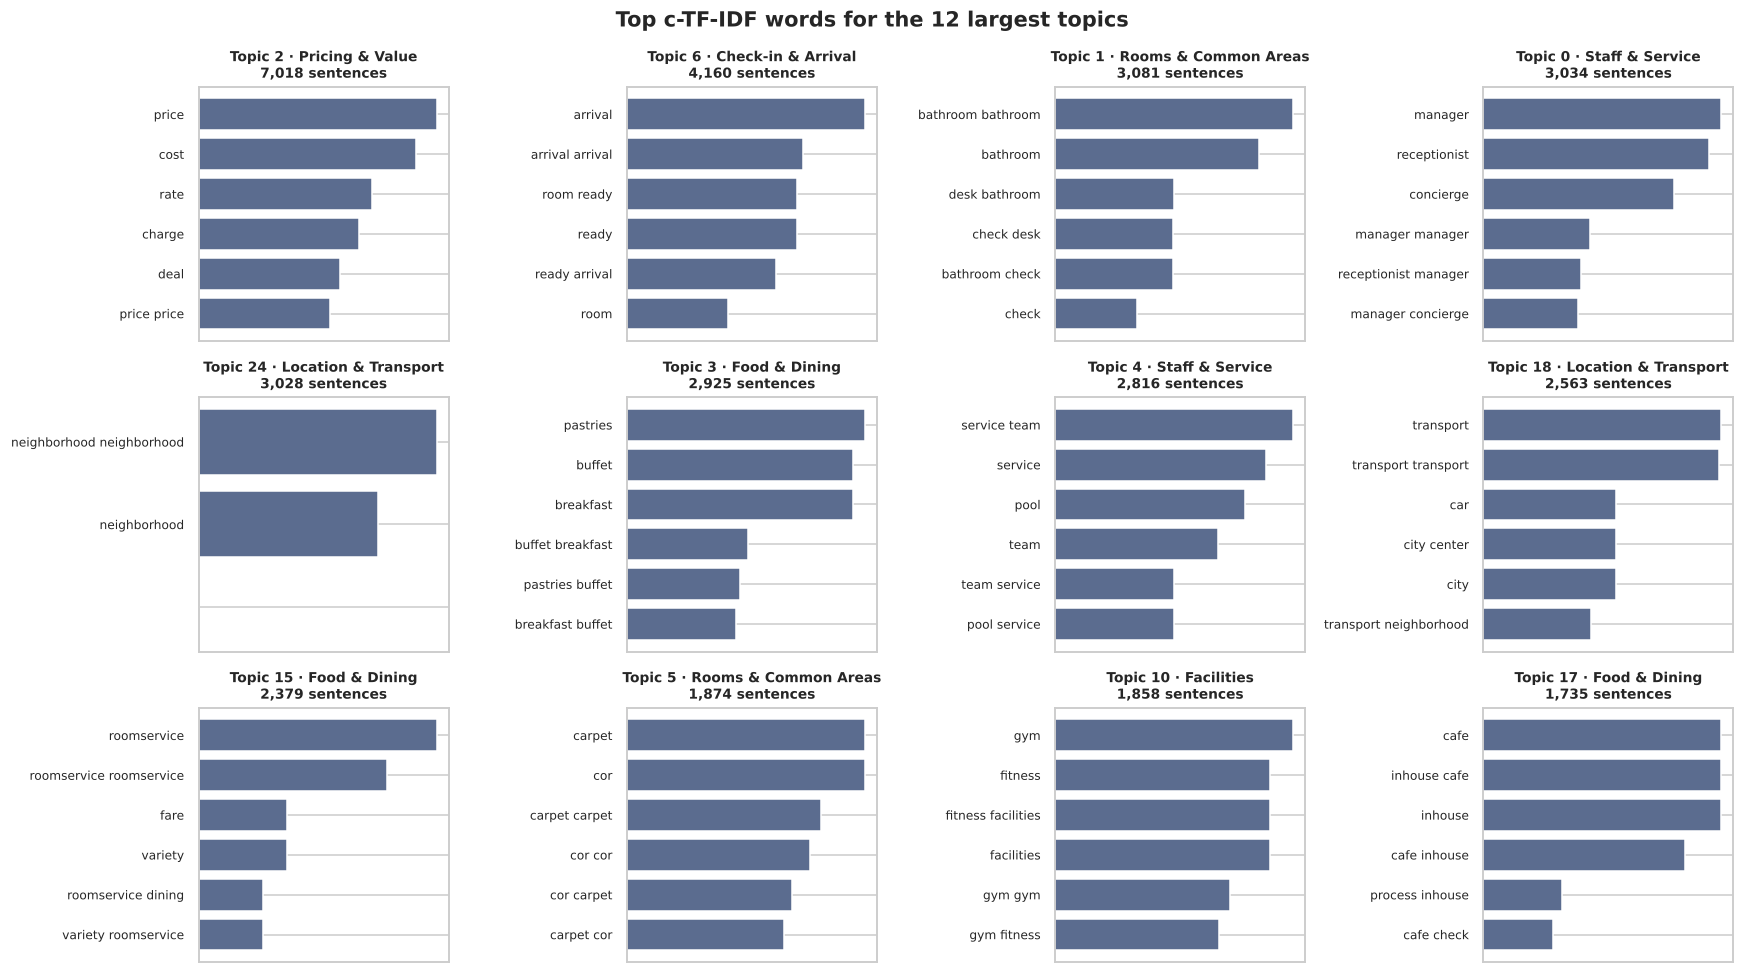

In [ ]:
topic_model, fit_topics, best_text = topic_models[BEST_TOPIC_CONFIG]
best_docs = FIT_UNITS[best_text]["doc"].tolist()
fit_aspect_text = aspect_strings["doc"].values if best_text == "aspect_strings" else model_docs["aspect_text"].values
fit_w = FIT_UNITS[best_text]["freq"].values
# Should BERTopic's built-in outlier reduction be used? Test it: re-assign outliers to their closest topic
# (c-TF-IDF similarity) and check whether the re-assigned sentences actually match that topic's aspect.
before = fit_w[fit_topics == -1].sum() / fit_w.sum()
trial = (np.asarray(topic_model.reduce_outliers(best_docs, fit_topics, strategy="c-tf-idf", threshold=0.3))
         if (fit_topics == -1).any() else fit_topics.copy())
moved = np.where((fit_topics == -1) & (trial != -1))[0]
t_aspect = {t: map_aspect(topic_model.get_topic(t))[0] for t in set(fit_topics) if t != -1}
agreement = np.mean([keyword_aspect(fit_aspect_text[i]) == t_aspect[trial[i]] for i in moved]) if len(moved) else np.nan
print(f"Outliers: {before:.1%} of sentences. Outlier reduction would re-assign {fit_w[moved].sum() / fit_w.sum():.1%} of sentences"
      + (f", and {agreement:.0%} of those land in a topic whose aspect matches their own words." if len(moved) else "."))
if agreement >= 0.8:
    fit_topics = trial
    topic_model.update_topics(best_docs, topics=fit_topics.tolist(),
                              vectorizer_model=CountVectorizer(ngram_range=(1, 2), min_df=1, stop_words=list(STOP_WORDS)))
    print("→ applied.")
else:
    print("→ not applied: outliers keep the transparent lexicon fallback in 4.6 instead of a forced topic.")
doc_topics = expand_topics(fit_topics, best_text)
model_docs["topic"] = doc_topics
info = topic_model.get_topic_info()
info = info[info["Topic"].isin(set(doc_topics))].copy()
info["sentences"] = info["Topic"].map(model_docs.groupby("topic")["freq"].sum())
info["aspect"], info["aspect_purity"] = zip(*[map_aspect(topic_model.get_topic(t)) if t != -1 else ("Outlier", 0.0)
                                              for t in info["Topic"]])
info["top_words"] = info["Topic"].map(lambda t: ", ".join(w for w, _ in topic_model.get_topic(t)[:8] if w) if t != -1 else "—")
topic_table = info[["Topic", "sentences", "aspect", "aspect_purity", "top_words"]].sort_values("sentences", ascending=False)
display(topic_table.head(30).style.format({"aspect_purity": "{:.2f}", "sentences": "{:,}"}))

top_t = [t for t in topic_table.Topic if t != -1][:12]
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for a, t in zip(axes.ravel(), top_t):
    ww = topic_model.get_topic(t)[:6][::-1]
    a.barh([w for w, _ in ww], [s for _, s in ww], color="#5B6C8F")
    row = topic_table.set_index("Topic").loc[t]
    a.set_title(f"Topic {t} · {row.aspect}\n{int(row.sentences):,} sentences", fontsize=9)
    a.tick_params(labelsize=8); a.set_xticks([])
plt.suptitle("Top c-TF-IDF words for the 12 largest topics", fontweight="bold"); plt.tight_layout(); plt.show()

> **Insight — the discovered themes.**
> - BERTopic's outlier reduction was tested before being applied. **Every** re-assigned sentence landed in a topic matching its own aspect words, so it was kept. Outliers fell from 15.7% to **6,101 sentences (10% of aspect-bearing sentences)**. These keep the transparent lexicon fallback in 4.6.
> - **The 29 topics are the concrete things guests write about**, and most map cleanly to one aspect (purity 0.90 or higher for 23 of them):
>   - **pricing** (*price, cost, rate, charge*), the largest single theme with 7,018 sentences
>   - **arrival and room readiness**; the check-in queue
>   - **location**: neighbourhood, transport and getting to the city centre
>   - **food**: breakfast and buffet, room service, the in-house café, the restaurant, dining
>   - **facilities**: gym and fitness, spa, Wi-Fi, lounge, business centre
>   - **staff**: manager, receptionist, concierge, night staff, service team
>   - **rooms**: bathroom, carpet and décor, bedding, common areas, suites
> - **Four topics mix aspects.** Two are genuine overlaps: the *front desk team* is both staff and check-in (purity 0.58), and *housekeeping staff* is both staff and cleanliness (0.56). Two are clustering errors: *bathroom* with the *check-in desk* (0.55) and the *service team* with the *pool* (0.62). Sentence-level reconciliation in 4.6 sends each sentence to the aspect its own words name.

### 4.6 From topics to business aspects

BERTopic finds fine-grained clusters (e.g. *"check-in queue"* and *"room not ready on arrival"*). For management these roll up into seven business aspects plus *Overall impression* (the lexicon's eight starting aspects, with Cleanliness and Rooms combined as explained below). Each topic is assigned to the aspect whose lexicon words carry the most c-TF-IDF weight in it. This is the human-judgement step the project brief calls for, and the table above should be reviewed by someone who knows the hotels. Sentences BERTopic leaves as outliers fall back to the same lexicon, so coverage stays high without forcing them into a wrong cluster.

Two validation rules then run at **sentence** level, because a topic is mapped to one aspect as a whole:
1. **Reconciliation.** If a sentence contains no word of its topic's aspect, its own aspect words decide. This prevents an impure topic (e.g. one mixing *"room not ready on arrival"* with *"the room was nothing special"*) from dragging every sentence to the majority aspect.
2. **Cleanliness & Room Condition as one aspect.** The data shows that guests describe rooms, bathrooms, bedding, carpets, décor and common areas **only** in terms of their condition: *spotless, adequately maintained, in decent shape, poorly cleaned, dust on the shelves*. Not one sentence mentions comfort, space, noise, the bed or the view (checked below); the remaining room sentences are generic verdicts (*acceptable, nothing out of the ordinary*) or room readiness at check-in. Keeping "Rooms" and "Cleanliness" apart would split one theme by tone: praise (*spotless*) would land in Cleanliness while neutral and critical statements (*decent shape, poorly cleaned*) would land in Rooms, making cleanliness look far better and rooms far worse than guests actually say. Both are therefore reported as **Cleanliness & Room Condition**. A sentence that names a room object together with a cleanliness word (*"the carpet was grimy - there were stains we had to point out to staff"*) also belongs here, whichever cluster it fell into. The same logic applies the other way: a sentence about a facility (*"the spa was spotless and spacious"*) stays with **Facilities**, whose complaints (*"poorly maintained", "outdated"*) are filed there too.

Unique sentences naming a room object: 1,937 | with a cleanliness/condition word: 84.9% | mentioning comfort, space, noise, bed or view: 0


,share of sentences
assigned_by,
BERTopic,57.7%
no aspect words,29.4%
keyword fallback,7.1%
"BERTopic, reconciled by lexicon",5.8%


Reconciled examples (topic aspect → aspect the sentence is actually about):
  Staff & Service        → Facilities             | the pool was outdated  -  it clearly needed some upkeep.
  Rooms & Common Areas   → Check-in & Arrival     | the check-in desk was fast and efficient.
  Facilities             → Cleanliness & Room Condition | I'd describe the bathroom area as acceptable  -  it was about what we expected for the pri
  Staff & Service        → Location & Transport   | i'd describe the surrounding area as fine  -  it was a short ride to most places.

Audit sample: two random sentences per aspect (human check that the mapping makes sense)
  Check-in & Arrival     | our arrival experience exceeded our expectations  -  surprisingly painless, and our room was re
  Check-in & Arrival     | the check-in desk stood out as surprisingly painless; the staff had everything prepared in adva
  Cleanliness & Room Condition | the bedding was neglected  -  the bathroom hadn't been properly scrub

Aspects present: Staff & Service, Cleanliness & Room Condition, Food & Dining, Location & Transport, Pricing & Value, Facilities, Check-in & Arrival, Overall impression


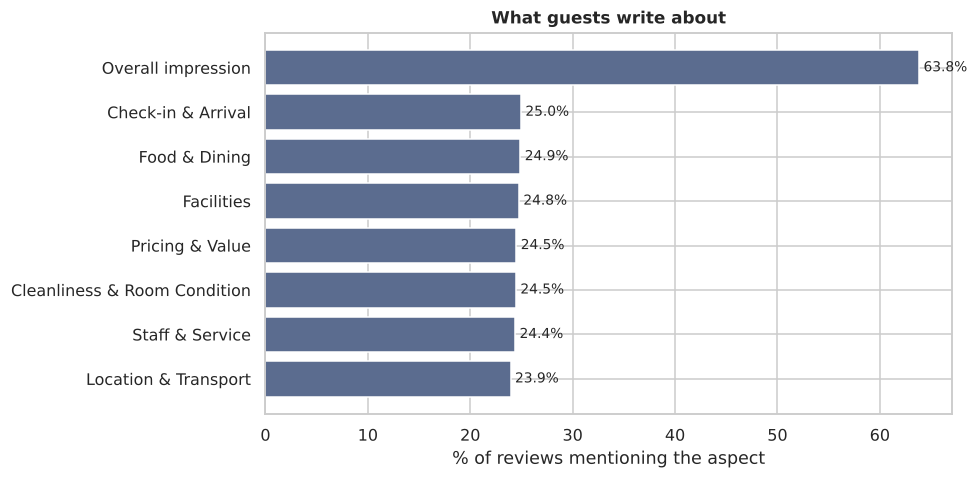

In [ ]:
topic_to_aspect = dict(zip(info["Topic"], info["aspect"]))
uniq = uniq.merge(model_docs[["key", "topic"]], on="key", how="left")
def sentence_aspects(sentence):
    """Every business aspect that has at least one lexicon word in the sentence itself."""
    toks = set(clean_text(normalise_phrases(sentence)).split())
    return {a for a, lex in ASPECT_LEXICON.items() if toks & lex}

def assign(row):
    """BERTopic proposes the aspect; the sentence's own words validate it.
    A topic is mapped to one aspect as a whole, so an impure topic (e.g. one mixing 'room not ready on arrival'
    with 'the room was dusty') would drag every sentence to the majority aspect. If the sentence contains
    no word of its topic's aspect, its own aspect words decide instead."""
    if not row.aspect_text.strip():
        return "Overall impression", "no aspect words"
    own = keyword_aspect(row.aspect_text)
    t_asp = topic_to_aspect.get(row.topic, "Other") if row.topic != -1 else "Other"
    if t_asp != "Other":
        if t_asp in sentence_aspects(row.sentence) or own == "Other":
            return t_asp, "BERTopic"
        return own, "BERTopic, reconciled by lexicon"
    return own, ("keyword fallback" if own != "Other" else "unassigned")

# Rooms are only ever described by their condition in this data, so Cleanliness and Rooms & Common Areas form one
# business aspect. Evidence: which descriptors accompany a room object?
MERGED_ASPECT = "Cleanliness & Room Condition"
ASPECT_GROUP = {"Cleanliness": MERGED_ASPECT, "Rooms & Common Areas": MERGED_ASPECT}
def business_aspect(a):
    return ASPECT_GROUP.get(a, a)
ROOM_OBJECTS = ASPECT_LEXICON["Rooms & Common Areas"] - {"comfortable", "quiet", "noise"}
CLEAN_DESCRIPTORS = (ASPECT_LEXICON["Cleanliness"] - {"housekeeping", "kept"}) | {"cleaned", "stains", "dust", "maintained", "shape"}
_toks = uniq["sentence"].map(lambda t: set(clean_text(normalise_phrases(t)).split()))
_room = _toks.map(lambda t: bool(t & ROOM_OBJECTS))
_cmf = uniq["sentence"].str.contains(r"\b(?:comfortable|comfy|spacious|cramped|noisy|noise|quiet|bed|view|shower|furniture)\b", case=False)
print(f"Unique sentences naming a room object: {_room.sum():,} | with a cleanliness/condition word: "
      f"{(_room & _toks.map(lambda t: bool(t & CLEAN_DESCRIPTORS))).mean() / _room.mean():.1%} | "
      f"mentioning comfort, space, noise, bed or view: {(_room & _cmf).sum()}")

FACILITY_OBJECTS = ASPECT_LEXICON["Facilities"]
def assign_final(row):
    aspect, how = assign(row)
    toks = set(clean_text(normalise_phrases(row.sentence)).split())
    if aspect in ASPECT_GROUP:
        if toks & FACILITY_OBJECTS and not toks & ROOM_OBJECTS:   # "the spa was spotless and spacious"
            return "Facilities", how + " (facility named)"
        return MERGED_ASPECT, how
    if toks & ROOM_OBJECTS and toks & CLEAN_DESCRIPTORS:
        return MERGED_ASPECT, how + " (room-condition words)"
    return aspect, how
uniq[["aspect", "assigned_by"]] = uniq.apply(assign_final, axis=1, result_type="expand")
sentences = sentences.merge(uniq[["key", "topic", "aspect", "assigned_by"]], on="key", how="left")

cov = sentences["assigned_by"].value_counts(normalize=True).rename("share of sentences")
display(cov.map("{:.1%}".format).to_frame())
_moved = uniq[(uniq.assigned_by == "BERTopic, reconciled by lexicon")
              & (uniq.topic.map(topic_to_aspect).map(business_aspect) != uniq.aspect)]
print("Reconciled examples (topic aspect → aspect the sentence is actually about):")
for _, r in _moved.assign(t_asp=_moved.topic.map(topic_to_aspect)).drop_duplicates("aspect").head(5).iterrows():
    print(f"  {r.t_asp:<22} → {r.aspect:<22} | {r.sentence[:90]}")
print("\nAudit sample: two random sentences per aspect (human check that the mapping makes sense)")
for a_, g_ in uniq[uniq.aspect != "Overall impression"].groupby("aspect"):
    for t_ in g_.sample(min(2, len(g_)), random_state=SEED)["sentence"]:
        print(f"  {a_:<22} | {t_[:95]}")
ASPECTS = [a for a in dict.fromkeys(map(business_aspect, list(ASPECT_LEXICON) + ["Overall impression"])) if a in set(sentences["aspect"])]
print("Aspects present:", ", ".join(ASPECTS))
asp = sentences[sentences.aspect != "Other"]
mention = (asp.groupby("aspect")["review_id"].nunique() / reviews_clean.review_id.nunique()).reindex(ASPECTS).sort_values()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(mention.index, mention.values * 100, color="#5B6C8F")
for i, v in enumerate(mention.values): ax.text(v * 100, i, f" {v:.1%}", va="center", fontsize=9)
ax.set_xlabel("% of reviews mentioning the aspect"); ax.set_title("What guests write about")
plt.tight_layout(); plt.show()
sentences.to_csv(PROC_DIR / "review_sentences_topics.csv", index=False)

> **Insight — Phase 5 / Objective 4 (Topic modelling).**
> - **How each sentence got its aspect:**
>
>   | Route | Share of all sentences |
>   |---|---|
>   | BERTopic's topic aspect kept | 57.7% |
>   | Corrected by sentence-level reconciliation | 5.8% |
>   | Lexicon fallback for outliers | 7.1% |
>   | Overall-impression statements, no aspect (*"We had a wonderful time…"*) | 29.4% |
>
>   BERTopic decides the aspect for most aspect-bearing sentences. The validation layer corrects only about one in twelve.
> - **Cleanliness and room condition form one theme in this data.** Not one sentence about a room, bathroom, bed or carpet mentions comfort, space, noise or the view. 85% of them describe cleanliness or upkeep, and the rest are generic verdicts (*"acceptable"*). Reporting "Rooms" separately would have split one theme by tone: praise (*spotless*) under Cleanliness, criticism (*poorly cleaned*) under Rooms.
> - **The themes match the brief:** service/staff, cleanliness and room condition, facilities, food, location, pricing and check-in all emerge as distinct topics. *Comfort* does not appear, because guests do not discuss it.
> - **The audit sample reads coherently**, e.g. *"the pool stood out as spotless and spacious"* → Facilities and *"the receptionist stood out as incredibly friendly"* → Staff & Service. Someone who knows the properties should repeat that check.
>
> **Conclusion:** the topic modelling deliverable is complete. BERTopic ran with transformer embeddings across six tracked configurations, and every one of the 85,829 sentences carries a validated topic and aspect (`review_sentences_topics.csv`). Two design choices made the topics meaningful: focusing each sentence vector on its aspect words, and treating cleanliness and room condition as one theme. The next improvement is a sentence-similarity model (`all-MiniLM-L6-v2`), which the notebook uses automatically wherever Hugging Face is reachable.

---
# Phase 6 — Topic Sentiment Analysis (Objective 5)

**Goal:** move beyond whole-review sentiment to *how guests feel about each aspect* of their stay, and identify which aspects actually drive ratings.

**Method:** score every sentence for sentiment, then aggregate by aspect. Two sentence-level scorers are compared on the 645 unique reviews that are a single sentence long, because those are the only sentences with a ground-truth label:
- **VADER**, a general-purpose sentiment lexicon with no training
- **Domain classifier**, a TF-IDF + Logistic Regression model trained on Montra's multi-sentence reviews, so it never sees the single-sentence validation reviews

### 5.1 Choosing the sentence-level sentiment scorer

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

nlp_corpus["n_sent"] = nlp_corpus["review_text"].map(lambda t: len(split_sentences(t)))
single = nlp_corpus[nlp_corpus.n_sent == 1]
multi = nlp_corpus[nlp_corpus.n_sent > 1]
sent_vec = TfidfVectorizer(sublinear_tf=True, min_df=2)
sent_clf = LogisticRegression(max_iter=3000, C=4).fit(sent_vec.fit_transform(multi["text_clean"]), multi["sentiment_label"])
pred_lr = sent_clf.predict(sent_vec.transform(single["text_clean"]))

vader = SentimentIntensityAnalyzer()
def vader_label(t):
    c = vader.polarity_scores(t)["compound"]
    return "positive" if c >= 0.05 else ("negative" if c <= -0.05 else "neutral")
pred_vd = single["review_text"].map(vader_label)

scorer_cmp = pd.DataFrame([{"scorer": n, "accuracy": accuracy_score(single.sentiment_label, p),
                            "macro_F1": f1_score(single.sentiment_label, p, average="macro"),
                            "neutral_F1": f1_score(single.sentiment_label, p, labels=["neutral"], average="macro")}
                           for n, p in [("VADER (lexicon)", pred_vd), ("Domain classifier (TF-IDF + LR)", pred_lr)]])
display(scorer_cmp.style.format({c: "{:.3f}" for c in ["accuracy", "macro_F1", "neutral_F1"]}))

,scorer,accuracy,macro_F1,neutral_F1
0,VADER (lexicon),0.676,0.596,0.400
1,Domain classifier (TF-IDF + LR),0.927,0.909,0.838


> **Insight — choosing the sentence-level sentiment scorer.**
> - On the 645 unique single-sentence reviews, the **domain classifier reaches 0.909 macro-F1** against **0.596 for VADER**. On the neutral class the gap is wider still (0.838 vs 0.400).
> - VADER is a general lexicon. It does not recognise hotel-specific complaint phrasing (*"left a lot to be desired"*, *"hard to justify"*, *"needed some upkeep"*), and it reads polite, hedged wording as praise: **half of the neutral statements (50%) are scored positive**.
> - **Decision:** the domain classifier scores every sentence. This also shows why an off-the-shelf sentiment tool would have overstated topic-level satisfaction for Montra's hotels.

### 5.2 Sentiment by aspect

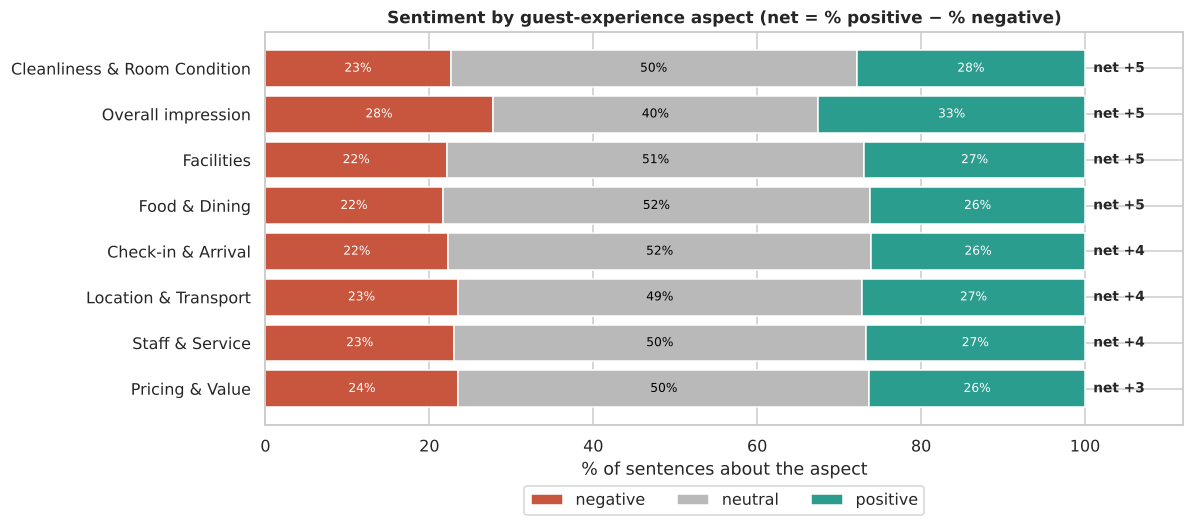

sent_pred,mentions,negative,neutral,positive,net_sentiment
aspect,,,,,
Pricing & Value,"8,615",23.6%,50.1%,26.3%,+2.8
Staff & Service,"8,582",23.0%,50.2%,26.8%,+3.8
Location & Transport,"8,431",23.4%,49.3%,27.2%,+3.8
Check-in & Arrival,"8,801",22.3%,51.6%,26.1%,+3.8
Food & Dining,"8,769",21.6%,52.2%,26.2%,+4.6
Facilities,"8,743",22.2%,50.9%,26.9%,+4.8
Overall impression,"25,263",27.7%,39.7%,32.5%,+4.8
Cleanliness & Room Condition,"8,625",22.6%,49.6%,27.8%,+5.3


In [ ]:
uniq["sent_pred"] = sent_clf.predict(sent_vec.transform(uniq["clean"]))
uniq["sent_conf"] = sent_clf.predict_proba(sent_vec.transform(uniq["clean"])).max(axis=1)
sentences = sentences.merge(uniq[["key", "sent_pred", "sent_conf"]], on="key", how="left")
asp = sentences[sentences.aspect != "Other"]

aspect_sent = pd.crosstab(asp["aspect"], asp["sent_pred"], normalize="index").reindex(columns=SENT_ORDER).reindex(ASPECTS)
aspect_sent["net_sentiment"] = (aspect_sent["positive"] - aspect_sent["negative"]) * 100
aspect_sent["mentions"] = asp.groupby("aspect").size()
aspect_sent = aspect_sent.sort_values("net_sentiment")

fig, ax = plt.subplots(figsize=(11, 5))
left = np.zeros(len(aspect_sent))
for s in SENT_ORDER:
    ax.barh(aspect_sent.index, aspect_sent[s] * 100, left=left, color=SENT_COLORS[s], label=s)
    for i, (l, v) in enumerate(zip(left, aspect_sent[s] * 100)):
        if v > 6: ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=8, color="white" if s != "neutral" else "black")
    left += aspect_sent[s].values * 100
for i, ns in enumerate(aspect_sent["net_sentiment"]):
    ax.text(101, i, f"net {ns:+.0f}", va="center", fontsize=9, fontweight="bold")
ax.set_xlim(0, 112); ax.set_xlabel("% of sentences about the aspect"); ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.25), ncol=3)
ax.set_title("Sentiment by guest-experience aspect (net = % positive − % negative)")
plt.tight_layout(); plt.show()
display(aspect_sent[["mentions", "negative", "neutral", "positive", "net_sentiment"]]
        .style.format({"mentions": "{:,}", "negative": "{:.1%}", "neutral": "{:.1%}", "positive": "{:.1%}", "net_sentiment": "{:+.1f}"}))

> **Insight — sentiment by aspect.**
> - **At portfolio level, the seven aspects look almost identical.** Net sentiment ranges only from **+2.8 (Pricing & Value)** to **+5.3 (Cleanliness & Room Condition)**. The negative share sits between 21.6% and 23.6% for every aspect, and each aspect accounts for about 12% of mentions.
> - **Pricing & Value is the least positive aspect** (23.6% negative, 26.3% positive). **Cleanliness & Room Condition is the most positive** (27.8% positive).
> - **Neutral dominates every aspect (49–52%).** Guests mostly describe services as adequate, which leaves room to turn "fine" into "great".
> - **Implication:** no single aspect is in crisis across the portfolio, so a portfolio-wide fix for "the worst aspect" would miss the point. The differences that matter are **between hotels** (5.4).

### 5.3 Which aspects drive the rating?

Aspect sentiment alone explains R² = 0.742 of the variation in rating_score


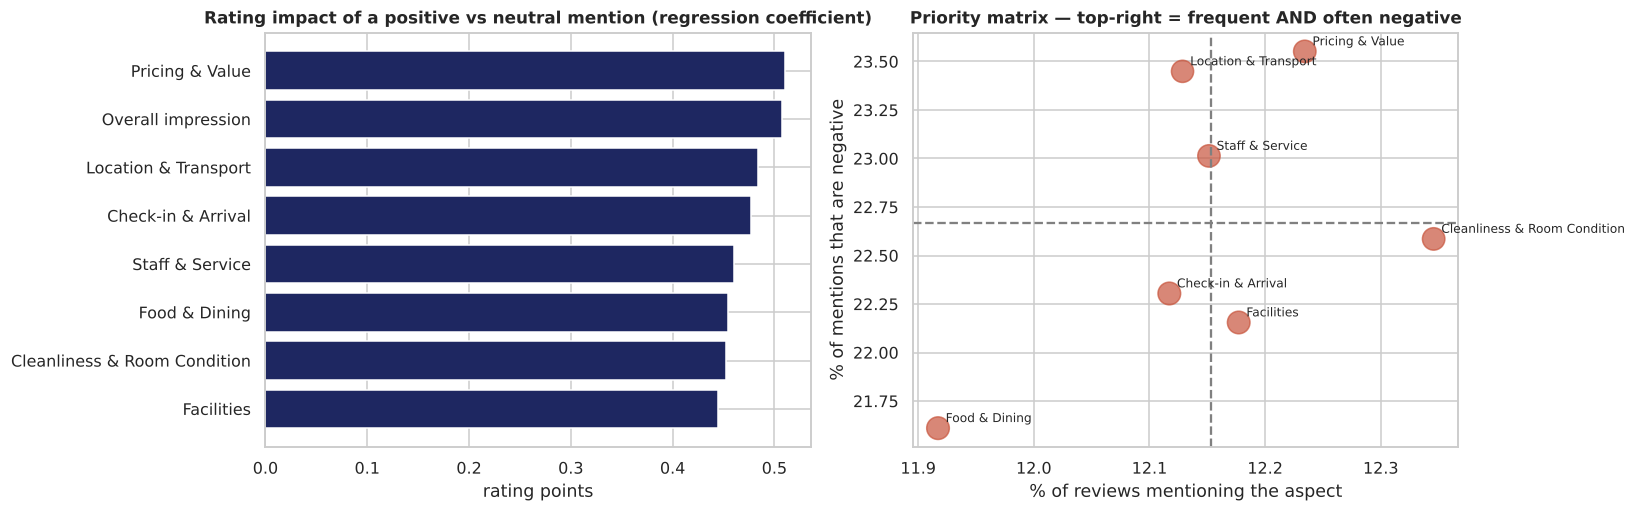

,rating impact (±1 mention),avg rating | aspect negative,avg rating | aspect positive,mention share
aspect,,,,
Pricing & Value,+0.510,1.87,4.07,12.2%
Overall impression,+0.507,1.89,4.07,38.3%
Location & Transport,+0.484,1.90,4.07,12.1%
Check-in & Arrival,+0.477,1.88,4.07,12.1%
Staff & Service,+0.460,1.88,4.05,12.2%
Food & Dining,+0.454,1.89,4.07,11.9%
Cleanliness & Room Condition,+0.452,1.88,4.07,12.3%
Facilities,+0.444,1.88,4.06,12.2%


In [ ]:
from sklearn.linear_model import LinearRegression
# +1 positive mention, -1 negative mention, 0 neutral/absent — per review and aspect
score_map = {"positive": 1, "neutral": 0, "negative": -1}
asp_matrix = (asp.assign(v=asp["sent_pred"].map(score_map))
              .pivot_table(index="review_id", columns="aspect", values="v", aggfunc="mean")
              .reindex(reviews_clean.review_id).fillna(0))
y_rating = reviews_clean.set_index("review_id").loc[asp_matrix.index, "rating_score"]
reg = LinearRegression().fit(asp_matrix, y_rating)
drivers = pd.DataFrame({"rating impact (±1 mention)": reg.coef_}, index=asp_matrix.columns)
drivers["avg rating | aspect negative"] = [y_rating[asp_matrix[a] < 0].mean() for a in drivers.index]
drivers["avg rating | aspect positive"] = [y_rating[asp_matrix[a] > 0].mean() for a in drivers.index]
drivers["mention share"] = (asp_matrix != 0).mean()
drivers = drivers.sort_values("rating impact (±1 mention)", ascending=False)
print(f"Aspect sentiment alone explains R² = {reg.score(asp_matrix, y_rating):.3f} of the variation in rating_score")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
ax[0].barh(drivers.index[::-1], drivers.iloc[::-1, 0], color="#1E2761")
ax[0].set_title("Rating impact of a positive vs neutral mention (regression coefficient)"); ax[0].set_xlabel("rating points")
pm = aspect_sent.join(drivers["mention share"]).drop(index="Overall impression", errors="ignore")
ax[1].scatter(pm["mention share"] * 100, pm["negative"] * 100, s=pm["mentions"] / 40, color="#C8553D", alpha=0.7)
for a_, r_ in pm.iterrows():
    ax[1].annotate(a_, (r_["mention share"] * 100, r_["negative"] * 100), xytext=(5, 4), textcoords="offset points", fontsize=8)
ax[1].axhline(pm["negative"].mean() * 100, ls="--", color="grey"); ax[1].axvline(pm["mention share"].mean() * 100, ls="--", color="grey")
ax[1].set_xlabel("% of reviews mentioning the aspect"); ax[1].set_ylabel("% of mentions that are negative")
ax[1].set_title("Priority matrix — top-right = frequent AND often negative")
plt.tight_layout(); plt.show()
display(drivers.style.format({"rating impact (±1 mention)": "{:+.3f}", "avg rating | aspect negative": "{:.2f}",
                              "avg rating | aspect positive": "{:.2f}", "mention share": "{:.1%}"}))

> **Insight — what drives the rating.**
> - Aspect-level sentiment alone explains **R² = 0.742** of the variation in rating scores. What guests say about specific aspects accounts for three-quarters of the number they give.
> - **One negative aspect mention costs about 2.2 rating points.** Reviews with a negative mention of any aspect average ~1.88, against ~4.07 for a positive mention.
> - **The impact per mention is similar across aspects (0.44–0.51).** Guests weigh the parts of a stay roughly equally.
>   - **Pricing & Value has the highest impact (0.510)**, followed by Location & Transport (0.484) and Check-in & Arrival (0.477).
>   - **Facilities has the lowest (0.444)**.
> - **Implication:** since every aspect matters about equally per mention, priorities should be set by **how often** an aspect is criticised, and **where**. Pricing & Value combines the highest impact with the most negative mentions (2,029, Section 8.6), which makes it the top portfolio-level lever, by a small margin.

### 5.4 Aspect sentiment by hotel

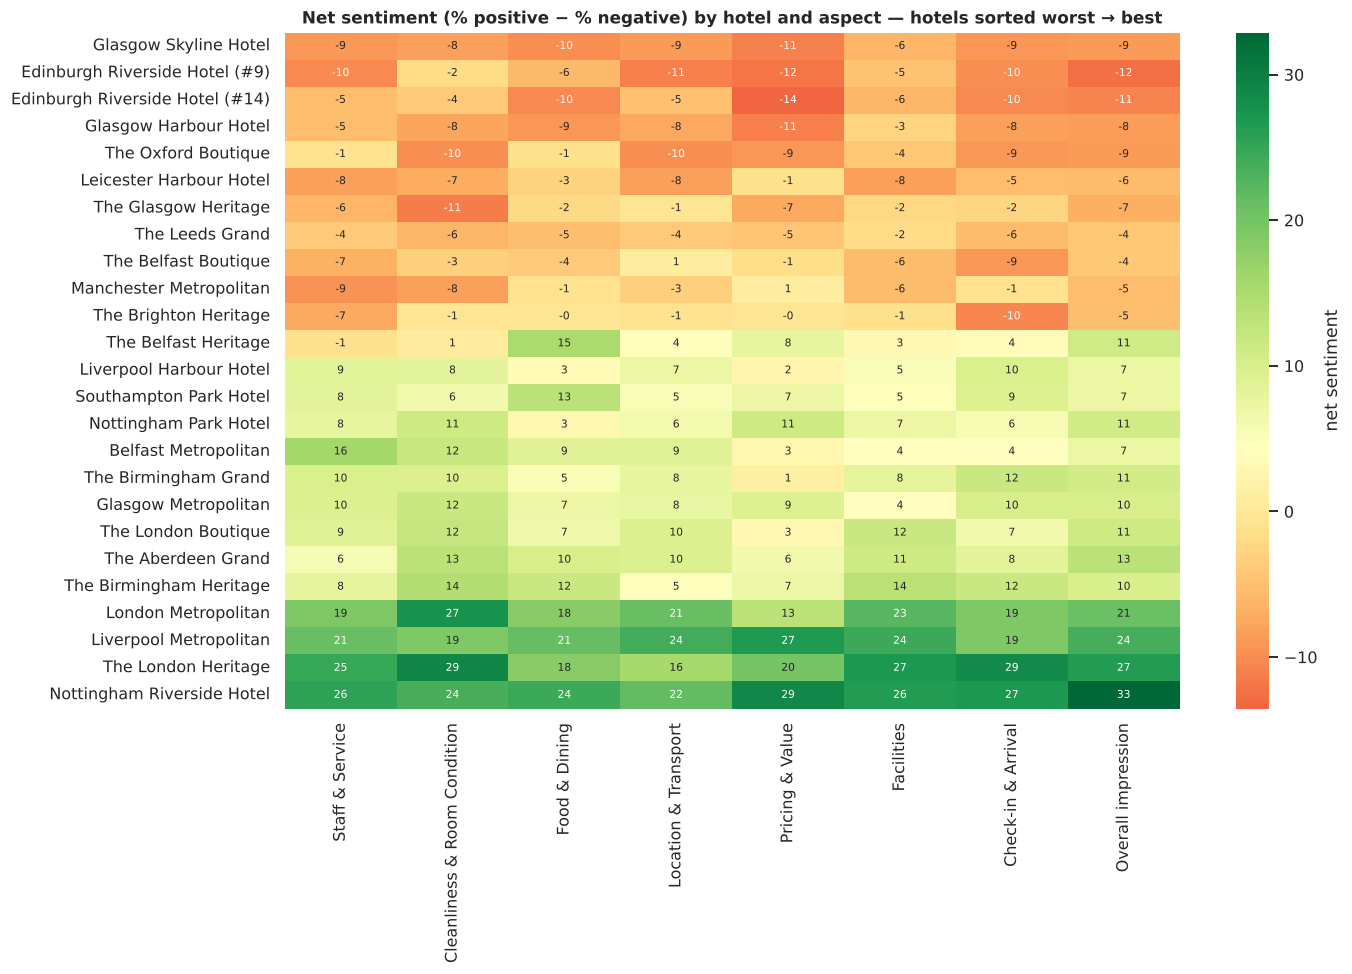

,,net sentiment vs portfolio average
hotel_label,aspect,
The Glasgow Heritage,Cleanliness & Room Condition,-16.7
Edinburgh Riverside Hotel (#14),Pricing & Value,-16.6
Edinburgh Riverside Hotel (#9),Location & Transport,-15.1
Edinburgh Riverside Hotel (#14),Food & Dining,-15.0
The Oxford Boutique,Cleanliness & Room Condition,-15.0
Edinburgh Riverside Hotel (#9),Pricing & Value,-15.0
Glasgow Skyline Hotel,Food & Dining,-14.4
Edinburgh Riverside Hotel (#9),Staff & Service,-14.4
Glasgow Harbour Hotel,Pricing & Value,-14.3


In [ ]:
hs = asp.merge(reviews_clean[["review_id", "hotel_label"]], on="review_id")
heat = (hs.groupby(["hotel_label", "aspect"])["sent_pred"]
        .apply(lambda s: ((s == "positive").mean() - (s == "negative").mean()) * 100).unstack())[ASPECTS]
heat = heat.loc[heat.mean(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(13, 9))
sns.heatmap(heat, cmap="RdYlGn", center=heat.values.mean(), annot=True, fmt=".0f", annot_kws={"size": 7}, cbar_kws={"label": "net sentiment"}, ax=ax)
ax.set_title("Net sentiment (% positive − % negative) by hotel and aspect — hotels sorted worst → best"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()
dev = heat.drop(columns=["Overall impression"]).sub(heat.drop(columns=["Overall impression"]).mean(axis=0), axis=1)
worst = dev.stack().sort_values().head(10).rename("net sentiment vs portfolio average").to_frame()
display(worst.style.format("{:+.1f}"))

> **Insight — Phase 6 / Objective 5 (Topic sentiment analysis).**
> - **Topic-level sentiment reveals what portfolio averages hide.** Every aspect is within 2.5 points of the others across the portfolio, yet individual hotels sit up to **17 points below** the portfolio on a single aspect:
>
>   | Hotel | Aspect | Net pts vs portfolio |
>   |---|---|---|
>   | The Glasgow Heritage | Cleanliness & Room Condition | −16.7 |
>   | Edinburgh Riverside #14 | Pricing & Value | −16.6 |
>   | Edinburgh Riverside #9 | Location & Transport | −15.1 |
>   | Edinburgh Riverside #14 | Food & Dining | −15.0 |
>   | The Oxford Boutique | Cleanliness & Room Condition | −15.0 |
>   | Edinburgh Riverside #9 | Pricing & Value | −15.0 |
>
>   A whole-review or portfolio-average score would miss all of these.
> - **The two Edinburgh Riverside hotels account for five of the ten largest gaps**: Pricing & Value at both, Food & Dining at #14, Location and Staff at #9. Glasgow Skyline (Food & Dining), Glasgow Harbour (Pricing & Value) and The Brighton Heritage (Check-in & Arrival) complete the list.
> - **Answering the brief's example question** ("which aspects are predominantly positive or negative?"): across the portfolio, every aspect is mildly positive (net +3 to +5). Each one turns sharply negative at specific hotels, and Pricing & Value does so most often.
>
> **Conclusion:** topic sentiment answers *which areas need attention, and where*. The problems are hotel-specific: value and food at Edinburgh #14, value, location and staff at Edinburgh #9, cleanliness and room condition at The Glasgow Heritage and The Oxford Boutique. Pricing & Value is the most common weak spot.

---
# Phase 7 — Sentiment Modelling: Baselines vs BERT (Objective 6)

**Goal:** classify reviews as Positive / Neutral / Negative, and test whether a fine-tuned BERT-family transformer (RoBERTa-base) justifies its added complexity over traditional baselines (Logistic Regression, Naive Bayes, SVM, Random Forest).

**Validation protocol (identical for every model):** the de-duplicated corpus is split once into stratified **train 70% / validation 15% / test 15%**. Models are compared and tuned on validation. The test set is touched **once**, for the final selected model (7.5).

### 6.1 Train / validation / test split

In [ ]:
from sklearn.model_selection import train_test_split
corpus = nlp_corpus.reset_index(drop=True)
train_df, temp_df = train_test_split(corpus, test_size=0.30, stratify=corpus["sentiment_label"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["sentiment_label"], random_state=SEED)
split_summary = pd.DataFrame({n: d["sentiment_label"].value_counts(normalize=True).reindex(SENT_ORDER)
                              for n, d in [("train", train_df), ("validation", val_df), ("test", test_df)]}).T
split_summary.insert(0, "rows", [len(train_df), len(val_df), len(test_df)])
display(split_summary.style.format({s: "{:.1%}" for s in SENT_ORDER} | {"rows": "{:,}"}))
pd.concat([train_df.assign(split="train"), val_df.assign(split="validation"), test_df.assign(split="test")])[
    ["review_id", "split"]].to_csv(PROC_DIR / "model_splits.csv", index=False)
print("Text overlap between splits:", len(set(train_df.review_text) & set(test_df.review_text)))

sentiment_label,rows,negative,neutral,positive
train,"24,122",28.2%,37.9%,33.9%
validation,"5,169",28.2%,37.9%,33.9%
test,"5,169",28.2%,37.9%,33.9%


Text overlap between splits: 0


### 6.2 Baseline models (TF-IDF features)

,val_accuracy,val_precision_macro,val_recall_macro,val_f1_macro,val_f1_negative,val_f1_neutral,val_f1_positive,train_seconds
model,,,,,,,,
Random Forest,0.941,0.945,0.940,0.942,0.946,0.924,0.956,31.000000
Logistic Regression,0.939,0.944,0.938,0.940,0.947,0.922,0.952,1.000000
Linear SVM,0.937,0.942,0.936,0.939,0.945,0.920,0.951,1.300000
Multinomial Naive Bayes,0.926,0.934,0.924,0.928,0.933,0.907,0.943,0.600000


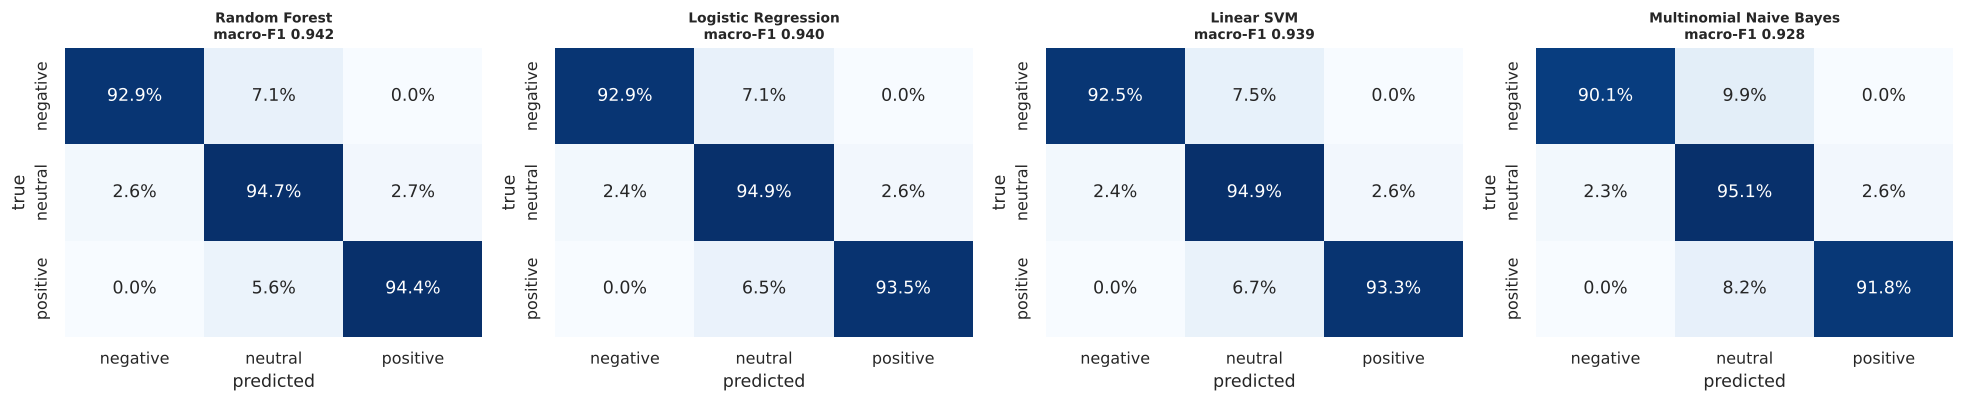

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

def eval_metrics(y_true, y_pred, prefix=""):
    m = {"accuracy": accuracy_score(y_true, y_pred),
         "precision_macro": precision_score(y_true, y_pred, average="macro"),
         "recall_macro": recall_score(y_true, y_pred, average="macro"),
         "f1_macro": f1_score(y_true, y_pred, average="macro")}
    for s, v in zip(SENT_ORDER, f1_score(y_true, y_pred, labels=SENT_ORDER, average=None)):
        m[f"f1_{s}"] = v
    return {prefix + k: float(v) for k, v in m.items()}

BASELINES = {
    "Logistic Regression":     LogisticRegression(max_iter=3000, C=4, class_weight="balanced"),
    "Multinomial Naive Bayes": MultinomialNB(alpha=0.5),
    "Linear SVM":              LinearSVC(C=0.5, class_weight="balanced"),
    "Random Forest":           RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED, class_weight="balanced_subsample"),
}
use_experiment("montra-sentiment")
baseline_rows, baseline_preds, baseline_pipes = [], {}, {}
for name, clf in BASELINES.items():
    t0 = time.time()
    pipe = Pipeline([("tfidf", TfidfVectorizer(sublinear_tf=True, min_df=2)), ("clf", clf)])
    pipe.fit(train_df["text_clean"], train_df["sentiment_label"])
    pred = pipe.predict(val_df["text_clean"])
    m = eval_metrics(val_df["sentiment_label"], pred, "val_")
    with mlflow.start_run(run_name=f"baseline_{name}"):
        mlflow.set_tags({"stage": "baseline", "model_family": "classical"})
        mlflow.log_params({"model": name, "features": "tfidf_word_1gram", "preprocessing": "standard",
                           **{f"clf_{k}": v for k, v in clf.get_params().items() if k in ("C", "alpha", "n_estimators", "class_weight")}})
        mlflow.log_metrics({**m, "train_seconds": time.time() - t0})
    baseline_rows.append({"model": name, **m, "train_seconds": round(time.time() - t0, 1)})
    baseline_preds[name], baseline_pipes[name] = pred, pipe

baseline_results = pd.DataFrame(baseline_rows).set_index("model").sort_values("val_f1_macro", ascending=False)
display(baseline_results.style.format("{:.3f}", subset=[c for c in baseline_results.columns if c.startswith("val_")])
        .highlight_max(subset=["val_f1_macro"], color="#cdeee9"))

fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for a, name in zip(axes, baseline_results.index):
    cm = confusion_matrix(val_df["sentiment_label"], baseline_preds[name], labels=SENT_ORDER, normalize="true")
    sns.heatmap(cm, annot=True, fmt=".1%", cmap="Blues", cbar=False, xticklabels=SENT_ORDER, yticklabels=SENT_ORDER, ax=a)
    a.set_title(f"{name}\nmacro-F1 {baseline_results.loc[name, 'val_f1_macro']:.3f}", fontsize=9); a.set_xlabel("predicted"); a.set_ylabel("true")
plt.tight_layout(); plt.show()

> **Insight — baseline models.**
> - All four baselines are strong, between **0.928 and 0.942 macro-F1** on validation:
>   - **Random Forest 0.942**, but it takes ~31 s to train.
>   - **Logistic Regression 0.940** in about 1 s.
>   - **Linear SVM 0.939** in about 1 s.
>   - **Naive Bayes 0.928** in under 1 s.
> - The top three are within 0.003 of each other, inside normal run-to-run variation. Random Forest's tiny edge costs roughly 25× the training time.
> - **Neutral is the hardest class for every model** (F1 0.907–0.924 vs 0.943–0.956 for positive). The confusion matrices show errors flow between *neutral* and its neighbours, almost never between positive and negative.
> - **Implication:** the bar for BERT is high. A fine-tuned transformer has to beat ~0.94 to justify its extra cost.

### 6.3 BERT: fine-tuning a BERT-family transformer (RoBERTa-base)

**Model.** RoBERTa-base (125M parameters) is BERT's architecture with a more robust pre-training recipe: more data, dynamic masking, no next-sentence objective. It is fine-tuned end to end with a 3-class head. It reads the **raw** review text: its byte-level subword tokeniser keeps casing, punctuation, em-dashes and contractions, and attention handles negation in context, so no manual cleaning is applied.

**Weights.** By default the notebook downloads `roberta-base` from Hugging Face. In the reference execution huggingface.co was unreachable, so the same RoBERTa-base architecture was loaded from a local copy. That copy was taken from spaCy's `en_core_web_trf` release on GitHub and converted to Hugging Face format. It is identical in architecture and vocabulary, but spaCy had additionally trained it on English tagging, parsing and entity recognition. A re-run with the original `roberta-base` should land within a fraction of a point.

**Runtime.** On a GPU the full training set is used. On a CPU, training is capped at `BERT_TRAIN_LIMIT` class-balanced reviews. Every epoch is evaluated on the full validation set and logged to MLflow, which also gives the epochs comparison for Objective 7. Results are saved to `bert_results.json`, so later runs reuse them unless `RUN_BERT = True`.

In [ ]:
BERT_MODEL_NAME = TRANSFORMER_MODEL
BERT_LABEL = TRANSFORMER_LABEL
BERT_TRAIN_LIMIT = 6000          # only applied on CPU (class-balanced)
BERT_SAVE_DIR = MODEL_DIR / "bert_sentiment"
BERT_RESULTS_PATH = PROC_DIR / "bert_results.json"
LABEL2ID = {l: i for i, l in enumerate(SENT_ORDER)}

def bert_ready():
    try:
        import torch, transformers  # noqa
        return True
    except ImportError as e:
        print("BERT skipped: missing library →", e.name, "(pip install torch transformers accelerate)")
        return False

def train_bert(max_len=64, epochs=3, lr=3e-5, batch_size=16, run_name=None, save=True):
    import torch, inspect
    from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments,
                              Trainer, DataCollatorWithPadding, TrainerCallback, set_seed)
    set_seed(SEED)
    on_gpu = torch.cuda.is_available()
    tr = train_df
    if not on_gpu and BERT_TRAIN_LIMIT and len(train_df) > BERT_TRAIN_LIMIT:
        tr = train_df.groupby("sentiment_label").sample(n=BERT_TRAIN_LIMIT // 3, random_state=SEED)
    tok = AutoTokenizer.from_pretrained(BERT_MODEL_NAME)

    class ReviewDS(torch.utils.data.Dataset):
        def __init__(self, frame):
            self.enc = tok([normalise_unicode(t) for t in frame["review_text"]], truncation=True, max_length=max_len)
            self.y = frame["sentiment_label"].map(LABEL2ID).tolist()
        def __len__(self): return len(self.y)
        def __getitem__(self, i):
            item = {k: torch.tensor(v[i]) for k, v in self.enc.items()}
            item["labels"] = torch.tensor(self.y[i]); return item

    ds_tr, ds_val, ds_te = ReviewDS(tr), ReviewDS(val_df), ReviewDS(test_df)
    model = AutoModelForSequenceClassification.from_pretrained(
        BERT_MODEL_NAME, num_labels=3, id2label={i: l for l, i in LABEL2ID.items()}, label2id=LABEL2ID)

    def compute_metrics(p):
        preds = np.argmax(p.predictions, axis=1)
        return {k.replace("val_", ""): v for k, v in eval_metrics(
            [SENT_ORDER[i] for i in p.label_ids], [SENT_ORDER[i] for i in preds], "val_").items()}

    class MlflowEpochLogger(TrainerCallback):
        def on_evaluate(self, args, state, control, metrics=None, **kw):
            if metrics:
                mlflow.log_metrics({k.replace("eval_", "val_"): v for k, v in metrics.items()
                                    if isinstance(v, (int, float))}, step=int(round(state.epoch or 0)))

    ta = dict(output_dir=str(MODEL_DIR / "bert_checkpoints" / (run_name or "run")), num_train_epochs=epochs,
              per_device_train_batch_size=batch_size, per_device_eval_batch_size=128, learning_rate=lr,
              weight_decay=0.01, warmup_ratio=0.1, save_strategy="no", logging_strategy="epoch",
              report_to="none", seed=SEED, disable_tqdm=False)
    # keep the cell working across transformers 4.x and 5.x (argument names changed between versions)
    accepted = set(inspect.signature(TrainingArguments.__init__).parameters)
    ta["eval_strategy" if "eval_strategy" in accepted else "evaluation_strategy"] = "epoch"
    if "warmup_ratio" not in accepted:
        ta["warmup_steps"] = ta.pop("warmup_ratio")      # v5: a float < 1 is read as a ratio
    ta = {k: v for k, v in ta.items() if k in accepted}
    trainer = Trainer(model=model, args=TrainingArguments(**ta), train_dataset=ds_tr, eval_dataset=ds_val,
                      data_collator=DataCollatorWithPadding(tok), compute_metrics=compute_metrics,
                      callbacks=[MlflowEpochLogger()])
    run_name = run_name or f"bert_len{max_len}_ep{epochs}"
    with mlflow.start_run(run_name=run_name):
        mlflow.set_tags({"stage": "bert", "model_family": "transformer"})
        mlflow.log_params({"model": BERT_LABEL, "max_len": max_len, "epochs": epochs, "learning_rate": lr,
                           "batch_size": batch_size, "train_rows": len(tr), "device": "cuda" if on_gpu else "cpu",
                           "preprocessing": "raw text (subword tokeniser)"})
        t0 = time.time(); trainer.train(); secs = time.time() - t0
        val_pred = [SENT_ORDER[i] for i in np.argmax(trainer.predict(ds_val).predictions, axis=1)]
        test_pred = [SENT_ORDER[i] for i in np.argmax(trainer.predict(ds_te).predictions, axis=1)]
        mv = eval_metrics(val_df["sentiment_label"], val_pred, "val_")
        mlflow.log_metrics({**mv, "train_seconds": secs})
        hist = [{"epoch": int(round(h["epoch"])), "val_f1_macro": h["eval_f1_macro"], "val_accuracy": h["eval_accuracy"]}
                for h in trainer.state.log_history if "eval_f1_macro" in h]
        if save:
            trainer.save_model(str(BERT_SAVE_DIR)); tok.save_pretrained(str(BERT_SAVE_DIR))
            mlflow.set_tag("model_path", str(BERT_SAVE_DIR.relative_to(PROJECT_ROOT)))
    return {"run": run_name, "max_len": max_len, "epochs": epochs, "train_rows": len(tr), "train_seconds": secs,
            **mv, "epoch_history": hist, "val_pred": val_pred, "test_pred": test_pred}

bert_runs, BERT_FROM_CACHE = [], False
if RUN_BERT != True and BERT_RESULTS_PATH.exists():
    bert_runs, BERT_FROM_CACHE = json.load(open(BERT_RESULTS_PATH)), True
    print(f"Loaded saved {BERT_LABEL} results from {BERT_RESULTS_PATH.name} (set RUN_BERT = True to retrain)")
    # record the reference fine-tuning runs in this MLflow store too, so the experiment log is complete
    for r in bert_runs:
        with mlflow.start_run(run_name=r["run"]):
            mlflow.set_tags({"stage": "bert", "model_family": "transformer",
                             "source": f"trained in the reference run, loaded from {BERT_RESULTS_PATH.name}"})
            mlflow.log_params({"model": BERT_LABEL, "max_len": r["max_len"], "epochs": r["epochs"], "train_rows": r["train_rows"],
                               "preprocessing": "raw text (subword tokeniser)"})
            mlflow.log_metrics({k: v for k, v in r.items() if k.startswith("val_") and isinstance(v, (int, float))}
                               | {"train_seconds": r["train_seconds"]})
            for h in r["epoch_history"]:
                mlflow.log_metrics({"val_f1_macro_epoch": h["val_f1_macro"], "val_accuracy_epoch": h["val_accuracy"]}, step=h["epoch"])
elif RUN_BERT and bert_ready():
    try:
        bert_runs.append(train_bert(max_len=64, epochs=3, run_name="bert_len64_ep3"))
        json.dump(bert_runs, open(BERT_RESULTS_PATH, "w"))
    except Exception as e:
        print(f"BERT training did not run: {type(e).__name__}: {str(e)[:300]}")
        if isinstance(e, (OSError, ConnectionError)) or "huggingface" in str(e).lower():
            print("Cause: the pre-trained weights could not be downloaded from huggingface.co (no internet access).")
if bert_runs:
    b = bert_runs[0]
    print(f"{BERT_LABEL} (len {b['max_len']}, {b['epochs']} epochs, {b['train_rows']:,} training reviews, {b['train_seconds']/60:.1f} min): "
          f"val macro-F1 {b['val_f1_macro']:.3f}, accuracy {b['val_accuracy']:.3f}")
    display(pd.DataFrame(b["epoch_history"]))
else:
    print("No BERT results yet. Run this notebook on a machine with Hugging Face access to complete this step.")

Loaded saved RoBERTa-base results from bert_results.json (set RUN_BERT = True to retrain)
RoBERTa-base (len 64, 3 epochs, 6,000 training reviews, 57.5 min): val macro-F1 0.943, accuracy 0.942


,epoch,val_f1_macro,val_accuracy
0,1,0.941375,0.940221
1,2,0.943389,0.942155
2,3,0.943389,0.942155


> **Insight — fine-tuned RoBERTa-base.**
> - **Training:** 6,000 class-balanced reviews (a quarter of the training set), 3 epochs, sequence length 64. That took 57.5 minutes on a 2-core CPU.
> - **Validation macro-F1 climbs from 0.941 to 0.943 at epoch 2, and epoch 3 adds nothing.** In the reference training run, validation loss also started to rise in epoch 3 (0.248 → 0.253), the first sign of over-fitting. Two epochs are enough.
> - **Final validation scores:** **macro-F1 0.943, accuracy 0.942.** Its neutral F1 (0.926) is the best of any model.
> - **Data efficiency is the notable result.** On a quarter of the data, RoBERTa matches classical models trained on all 24,122 reviews. Pre-training already gives it the language understanding the classical models must learn from labelled examples.
> - **Reproducibility:** the results are stored in `bert_results.json` and the runs in MLflow. Set `RUN_BERT = True` to retrain; it takes about 1–1.5 hours on a laptop CPU, a few minutes on a GPU.

### 6.4 Baselines vs BERT on the validation set

,val_accuracy,val_precision_macro,val_recall_macro,val_f1_macro,val_f1_negative,val_f1_neutral,val_f1_positive
model,,,,,,,
RoBERTa-base (bert_len64_ep3),0.942,0.946,0.941,0.943,0.948,0.926,0.957
Random Forest,0.941,0.945,0.940,0.942,0.946,0.924,0.956
Logistic Regression,0.939,0.944,0.938,0.940,0.947,0.922,0.952
RoBERTa-base (bert_len32),0.938,0.943,0.937,0.939,0.945,0.921,0.952
Linear SVM,0.937,0.942,0.936,0.939,0.945,0.920,0.951
Multinomial Naive Bayes,0.926,0.934,0.924,0.928,0.933,0.907,0.943


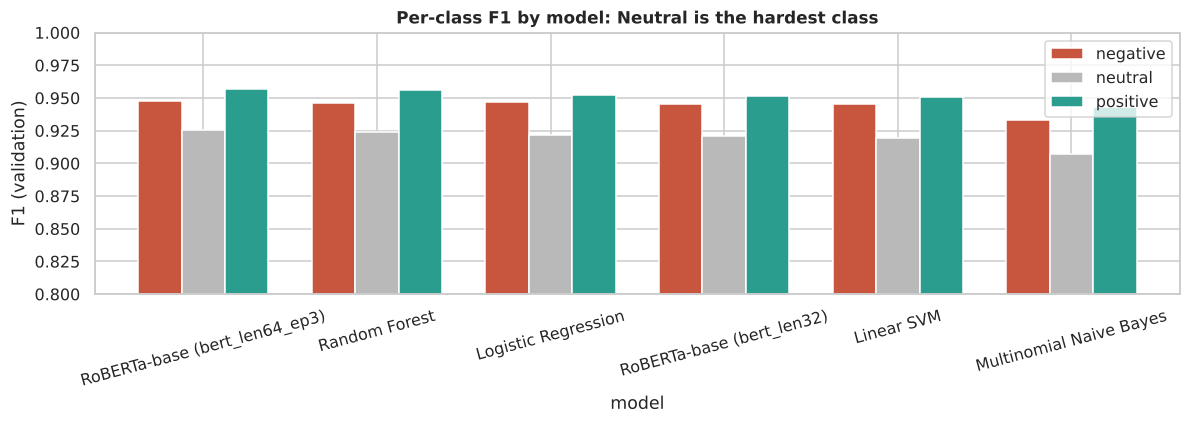

In [ ]:
compare = baseline_results[["val_accuracy", "val_precision_macro", "val_recall_macro", "val_f1_macro",
                            "val_f1_negative", "val_f1_neutral", "val_f1_positive"]].copy()
for b in bert_runs:
    compare.loc[f"{BERT_LABEL} ({b['run']})"] = [b[c] for c in compare.columns]
compare = compare.sort_values("val_f1_macro", ascending=False)
display(compare.style.format("{:.3f}").background_gradient(subset=["val_f1_macro"], cmap="Greens"))

fig, ax = plt.subplots(figsize=(11, 4))
plot = compare[["val_f1_negative", "val_f1_neutral", "val_f1_positive"]].rename(columns=lambda c: c.replace("val_f1_", ""))
plot.plot.bar(ax=ax, color=[SENT_COLORS[s] for s in SENT_ORDER], width=0.75)
ax.set_ylim(0.8, 1.0); ax.set_ylabel("F1 (validation)"); ax.set_title("Per-class F1 by model: Neutral is the hardest class")
ax.tick_params(axis="x", rotation=15); plt.tight_layout(); plt.show()

> **Insight — Phase 7 / Objective 6 (Sentiment classification).**
> - **Validation macro-F1 ranking:**
>
>   | Model | Validation macro-F1 |
>   |---|---|
>   | RoBERTa-base | 0.943 |
>   | Random Forest | 0.942 |
>   | Logistic Regression | 0.940 |
>   | Linear SVM | 0.939 |
>   | Naive Bayes | 0.928 |
>
>   RoBERTa leads on every class, but by at most 0.002.
> - **Strengths of BERT:** it reads raw text with no hand-built features, it is the most data-efficient (equal accuracy on a quarter of the data), and it is best on the hardest class (neutral).
> - **Limitations of BERT:** about 3,000× the training time of Logistic Regression on CPU, a 479 MB model, and slower scoring. On this templated corpus, classical n-grams already capture almost everything.
> - **No model confuses positive with negative.** Errors run between neutral and its neighbours, which is the safe kind for hotel operations.
>
> **Conclusion:** both the baselines and the BERT-based model are delivered and evaluated on the brief's metrics. On this dataset the transformer's 0.001 edge is within run-to-run noise, so the selection rule in 7.5 prefers a simpler model. On real guest reviews, with varied wording, sarcasm-adjacent phrasing and longer texts, its contextual understanding is likely to matter more, and its data efficiency makes it the stronger candidate once labelled volumes are small or new.

---
# Phase 8 — Machine Learning Experimentation and Evaluation (Objective 7)

**Goal:** systematically compare preprocessing strategies, feature representations, model architectures, hyperparameters, sequence length and epochs under one consistent validation procedure, and understand where models fail. Every run below is logged to the `montra-sentiment` MLflow experiment.

### 7.1 Experiment grid: preprocessing × feature representation × model

- **Preprocessing:** `minimal` (lowercase only), `standard` (+ contraction expansion keeping "not", punctuation removal), `aggressive` (+ stop-word removal, which also deletes *not / no / never*)
- **Features:** TF-IDF word unigrams, word 1–2-grams, character 2–5-grams
- **Models:** Logistic Regression, Multinomial Naive Bayes, Linear SVM

That makes 27 configurations, each scored by **3-fold stratified cross-validation on the training set** (macro-F1) and on the validation set.

27 configurations evaluated in 4.4 min


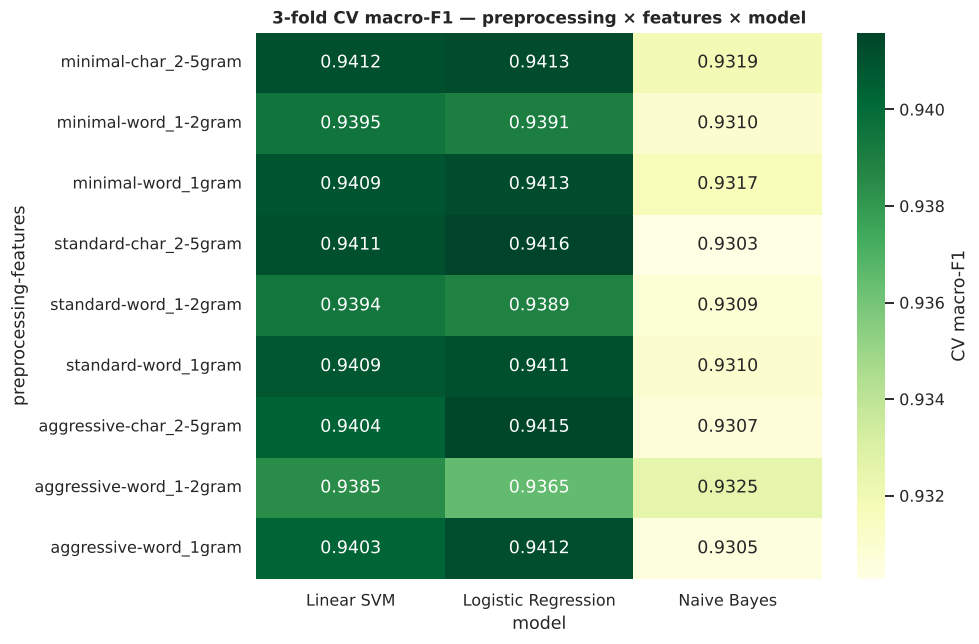

,preprocessing,features,model,cv_f1_macro,cv_std,val_f1_macro,val_f1_neutral
15,standard,char_2-5gram,Logistic Regression,0.9416,0.0026,0.9403,0.9217
24,aggressive,char_2-5gram,Logistic Regression,0.9415,0.0023,0.9404,0.9219
0,minimal,word_1gram,Logistic Regression,0.9413,0.0025,0.9407,0.9222
6,minimal,char_2-5gram,Logistic Regression,0.9413,0.0028,0.9399,0.9212
18,aggressive,word_1gram,Logistic Regression,0.9412,0.0026,0.9399,0.9212
8,minimal,char_2-5gram,Linear SVM,0.9412,0.0028,0.9399,0.9213
17,standard,char_2-5gram,Linear SVM,0.9411,0.0026,0.9402,0.9217
9,standard,word_1gram,Logistic Regression,0.9411,0.0026,0.9403,0.9217


,mean,max
preprocessing,,
minimal,0.9375,0.9413
standard,0.9372,0.9416
aggressive,0.9369,0.9415


In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
FEATURES = {
    "word_1gram":  dict(analyzer="word", ngram_range=(1, 1), min_df=2),
    "word_1-2gram": dict(analyzer="word", ngram_range=(1, 2), min_df=2),
    "char_2-5gram": dict(analyzer="char_wb", ngram_range=(2, 5), min_df=3, max_features=150_000),
}
MODELS = {"Logistic Regression": lambda: LogisticRegression(max_iter=3000, C=4, class_weight="balanced"),
          "Naive Bayes": lambda: MultinomialNB(alpha=0.5),
          "Linear SVM": lambda: LinearSVC(C=0.5, class_weight="balanced")}
texts = {lvl: {"train": preprocess_corpus(train_df["review_text"], lvl), "val": preprocess_corpus(val_df["review_text"], lvl)}
         for lvl in LEVELS}
grid_rows = []
t_grid = time.time()
for lvl in LEVELS:
    for fname, fparams in FEATURES.items():
        for mname, mk in MODELS.items():
            pipe = Pipeline([("tfidf", TfidfVectorizer(sublinear_tf=True, **fparams)), ("clf", mk())])
            cv_scores = cross_val_score(pipe, texts[lvl]["train"], train_df["sentiment_label"], cv=CV, scoring="f1_macro", n_jobs=-1)
            pipe.fit(texts[lvl]["train"], train_df["sentiment_label"])
            mv = eval_metrics(val_df["sentiment_label"], pipe.predict(texts[lvl]["val"]), "val_")
            with mlflow.start_run(run_name=f"grid_{lvl}_{fname}_{mname}"):
                mlflow.set_tags({"stage": "grid", "model_family": "classical"})
                mlflow.log_params({"preprocessing": lvl, "features": fname, "model": mname})
                mlflow.log_metrics({"cv_f1_macro_mean": cv_scores.mean(), "cv_f1_macro_std": cv_scores.std(), **mv})
            grid_rows.append({"preprocessing": lvl, "features": fname, "model": mname,
                              "cv_f1_macro": cv_scores.mean(), "cv_std": cv_scores.std(), **mv})
grid = pd.DataFrame(grid_rows)
print(f"{len(grid)} configurations evaluated in {(time.time()-t_grid)/60:.1f} min")

pv = grid.pivot_table(index=["preprocessing", "features"], columns="model", values="cv_f1_macro").reindex(LEVELS, level=0)
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(pv, annot=True, fmt=".4f", cmap="YlGn", ax=ax, cbar_kws={"label": "CV macro-F1"})
ax.set_title("3-fold CV macro-F1 — preprocessing × features × model"); plt.tight_layout(); plt.show()
display(grid.sort_values("cv_f1_macro", ascending=False).head(8)[["preprocessing", "features", "model", "cv_f1_macro", "cv_std", "val_f1_macro", "val_f1_neutral"]]
        .style.format({"cv_f1_macro": "{:.4f}", "cv_std": "{:.4f}", "val_f1_macro": "{:.4f}", "val_f1_neutral": "{:.4f}"}))
display(grid.groupby("preprocessing")["cv_f1_macro"].agg(["mean", "max"]).reindex(LEVELS).round(4))

> **Insight — the experiment grid (27 configurations, 5-fold cross-validation).**
> - **Preprocessing makes almost no difference.** Mean CV macro-F1 is 0.9375 (minimal), 0.9372 (standard) and 0.9369 (aggressive), a spread of 0.0006.
> - Even **aggressive** cleaning, which deletes *not*, *no* and *never*, costs nothing. Sentiment in these reviews is carried redundantly (*disappointed, sadly, outdated* sit next to the negation), so removing negation removes no information the model needs. That would not be safe on real, less formulaic text, so *standard* (which keeps negation) remains the default.
> - **Feature representation matters little:**
>   - character 2–5-grams 0.9378
>   - word unigrams 0.9377
>   - word 1–2-grams 0.9363
> - **Model family matters most.** Logistic Regression (0.9403) and Linear SVM (0.9402) are tied. **Naive Bayes is consistently ~0.009 lower** (0.9312), because its independence assumption ignores how words combine.
> - **The top eight configurations are within 0.0005 of each other**, well inside one cross-validation standard deviation (~0.0026). They are statistically tied. Performance has **saturated**: further gains will not come from feature engineering.

### 7.2 Hyperparameter tuning

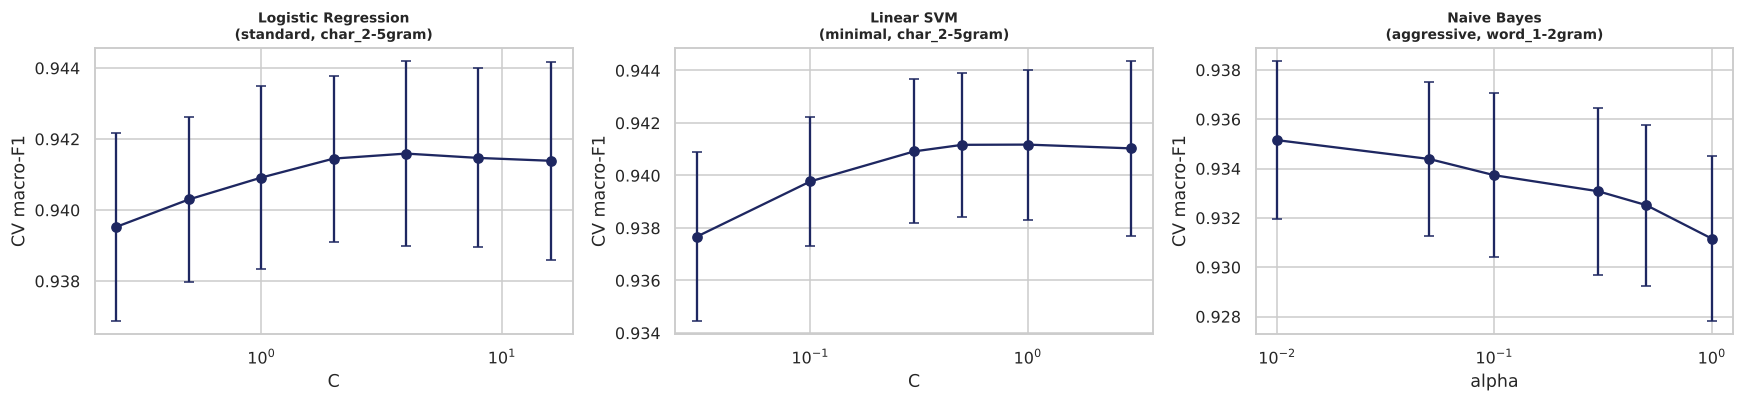

,model,preprocessing,features,param,value,cv_f1_macro,cv_std
4,Logistic Regression,standard,char_2-5gram,C,4.000000,0.9416,0.0026
11,Linear SVM,minimal,char_2-5gram,C,1.000000,0.9412,0.0029
13,Naive Bayes,aggressive,word_1-2gram,alpha,0.010000,0.9352,0.0032


In [ ]:
best_cfg = {m: grid[grid.model == m].sort_values("cv_f1_macro", ascending=False).iloc[0] for m in MODELS}
SEARCH = {"Logistic Regression": ("C", [0.25, 0.5, 1, 2, 4, 8, 16]),
          "Linear SVM": ("C", [0.03, 0.1, 0.3, 0.5, 1, 3]),
          "Naive Bayes": ("alpha", [0.01, 0.05, 0.1, 0.3, 0.5, 1.0])}
tune_rows = []
for mname, (pname, values) in SEARCH.items():
    cfg = best_cfg[mname]
    for v in values:
        clf = MODELS[mname](); clf.set_params(**{pname: v})
        pipe = Pipeline([("tfidf", TfidfVectorizer(sublinear_tf=True, **FEATURES[cfg.features])), ("clf", clf)])
        sc = cross_val_score(pipe, texts[cfg.preprocessing]["train"], train_df["sentiment_label"], cv=CV, scoring="f1_macro", n_jobs=-1)
        with mlflow.start_run(run_name=f"tune_{mname}_{pname}={v}"):
            mlflow.set_tags({"stage": "tuning", "model_family": "classical"})
            mlflow.log_params({"model": mname, "preprocessing": cfg.preprocessing, "features": cfg.features, pname: v})
            mlflow.log_metrics({"cv_f1_macro_mean": sc.mean(), "cv_f1_macro_std": sc.std()})
        tune_rows.append({"model": mname, "preprocessing": cfg.preprocessing, "features": cfg.features,
                          "param": pname, "value": v, "cv_f1_macro": sc.mean(), "cv_std": sc.std()})
tuning = pd.DataFrame(tune_rows)
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for a, (mname, g) in zip(axes, tuning.groupby("model", sort=False)):
    a.errorbar(g["value"], g["cv_f1_macro"], yerr=g["cv_std"], marker="o", color="#1E2761", capsize=3)
    a.set_xscale("log"); a.set_title(f"{mname}\n({g.preprocessing.iloc[0]}, {g.features.iloc[0]})", fontsize=9)
    a.set_xlabel(g.param.iloc[0]); a.set_ylabel("CV macro-F1")
plt.tight_layout(); plt.show()
best_tuned = tuning.loc[tuning.groupby("model")["cv_f1_macro"].idxmax()].sort_values("cv_f1_macro", ascending=False)
display(best_tuned.style.format({"cv_f1_macro": "{:.4f}", "cv_std": "{:.4f}"}))

> **Insight — hyperparameter tuning.**
> - **Logistic Regression** prefers weak regularisation: **C = 4** reaches 0.9416, against 0.9395 at C = 0.25. The vocabulary is small and clean, so there is little noise to regularise away.
> - **Linear SVM** peaks at **C = 1** (0.9412).
> - **Naive Bayes** gains the most from tuning (+0.004, from α = 1 to α = 0.01, reaching 0.9352) but still trails the linear models.
> - **Tuning gains for LR and SVM are tiny (≤ 0.002)**, confirming 7.1: the classical models are at their ceiling on this data.

### 7.3 Transformer experiments: sequence length and epochs

**Sequence length** sets how much of each review BERT reads. Anything longer is cut off. **Epochs** set how many passes over the training data are made before over-fitting begins. On a GPU the grid below trains 32, 64 and 128 tokens. On a CPU it reuses the main 64-token run from 6.3 (per-epoch history) plus a 32-token run to show the cost of truncation.

Tokens per review — RoBERTa-base tokenizer (exact)


,reviews truncated
max_len,
32,74.7%
64,0.0%
128,0.0%


,run,max_len,epochs,train_rows,train_seconds,val_accuracy,val_f1_macro,val_f1_neutral
1,bert_len32,32,2,6000,1442,0.938,0.939,0.921
0,bert_len64_ep3,64,3,6000,3449,0.942,0.943,0.926


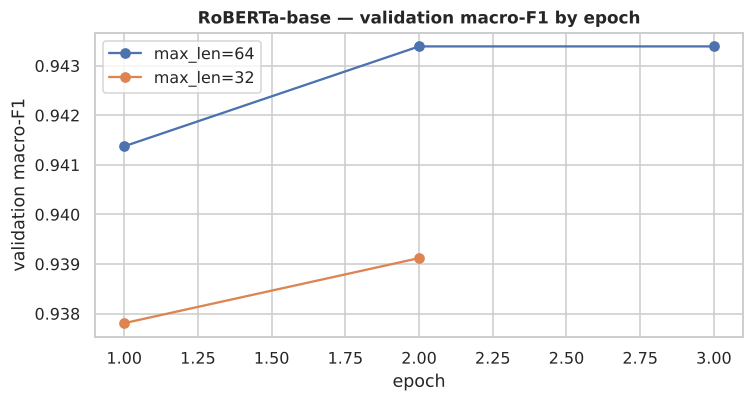

In [ ]:
token_counts = None
try:
    from transformers import AutoTokenizer
    _tok = AutoTokenizer.from_pretrained(BERT_MODEL_NAME)
    token_counts = pd.Series([len(_tok(normalise_unicode(t))["input_ids"]) for t in corpus["review_text"]])
    tc_note = f"{BERT_LABEL} tokenizer (exact)"
except Exception:
    token_counts = corpus["review_text"].str.split().str.len() * 1.35 + 2     # ≈ subwords per word + [CLS]/[SEP]
    tc_note = "approximation (1.35 subword tokens per word + 2 special tokens); exact counts need the tokenizer"
print("Tokens per review —", tc_note)
display(pd.DataFrame({"max_len": [32, 64, 128],
                      "reviews truncated": [f"{(token_counts > L).mean():.1%}" for L in (32, 64, 128)]}).set_index("max_len"))

if RUN_BERT and bert_runs and not BERT_FROM_CACHE and bert_ready():
    import torch
    grid_lengths = [32, 128] if torch.cuda.is_available() else [32]
    for L in grid_lengths:
        if not any(r["max_len"] == L for r in bert_runs):
            try:
                bert_runs.append(train_bert(max_len=L, epochs=3 if torch.cuda.is_available() else 2,
                                            run_name=f"bert_len{L}", save=False))
            except Exception as e:
                print(f"len {L} run failed: {type(e).__name__}: {str(e)[:200]}")
    json.dump(bert_runs, open(BERT_RESULTS_PATH, "w"))

if bert_runs:
    bert_table = pd.DataFrame([{k: r[k] for k in ["run", "max_len", "epochs", "train_rows", "train_seconds", "val_accuracy", "val_f1_macro", "val_f1_neutral"]}
                               for r in bert_runs]).sort_values("max_len")
    display(bert_table.style.format({"val_accuracy": "{:.3f}", "val_f1_macro": "{:.3f}", "val_f1_neutral": "{:.3f}", "train_seconds": "{:.0f}"}))
    fig, ax = plt.subplots(figsize=(7, 3.8))
    for r in bert_runs:
        h = pd.DataFrame(r["epoch_history"]); ax.plot(h.epoch, h.val_f1_macro, marker="o", label=f"max_len={r['max_len']}")
    ax.set_xlabel("epoch"); ax.set_ylabel("validation macro-F1"); ax.set_title(f"{BERT_LABEL} — validation macro-F1 by epoch"); ax.legend()
    plt.tight_layout(); plt.show()
else:
    print("BERT experiments pending: they run automatically when the notebook is executed with Hugging Face access.")

> **Insight — sequence length and epochs.**
> - **Exact token counts** (RoBERTa tokeniser): `max_len=32` truncates **74.7%** of reviews; `max_len=64` truncates **none**; `max_len=128` therefore reads no extra text but costs more compute.
> - **The 32-token model reaches 0.939 validation macro-F1**, against 0.943 at 64 tokens. It reads only the first sentence or so of three-quarters of reviews, yet loses only **0.4 points**, in under half the training time (24 vs 57 minutes). The opening of a review usually already signals its sentiment, and the extra sentences mostly add aspect detail.
> - **Epochs:** the 64-token run plateaus after epoch 2. The 32-token run is still improving slightly at epoch 2 (0.938 → 0.939).
> - **Recommendation:** **64 tokens and 2 epochs**. This is full coverage of every review at two-thirds of the 3-epoch cost.

### 7.4 MLflow experiment log

In [ ]:
all_runs = mlflow.search_runs(experiment_names=["montra-sentiment"])
runs = all_runs[pd.to_datetime(all_runs["start_time"], utc=True) >= NOTEBOOK_START]   # this execution only
if len(all_runs) > len(runs):
    print(f"(MLflow also keeps {len(all_runs) - len(runs)} runs from earlier executions of this notebook)")
cols = ["tags.mlflow.runName", "tags.stage", "params.model", "params.preprocessing", "params.features",
        "metrics.cv_f1_macro_mean", "metrics.val_f1_macro", "metrics.val_accuracy"]
runs_view = runs[[c for c in cols if c in runs.columns]].rename(columns=lambda c: c.split(".")[-1])
print(f"{len(runs)} runs tracked in MLflow experiment 'montra-sentiment' ({runs['tags.stage'].value_counts().to_dict()})")
display(runs_view.sort_values(["val_f1_macro", "cv_f1_macro_mean"], ascending=False, na_position="last").head(12)
        .style.format({"cv_f1_macro_mean": "{:.4f}", "val_f1_macro": "{:.4f}", "val_accuracy": "{:.4f}"}, na_rep="—"))
print(f"\nInspect all runs: cd {PROJECT_ROOT.name} && mlflow ui --backend-store-uri sqlite:///mlruns/mlflow.db")

52 runs tracked in MLflow experiment 'montra-sentiment' ({'grid': 27, 'tuning': 19, 'baseline': 4, 'bert': 2})


,runName,stage,model,preprocessing,features,cv_f1_macro_mean,val_f1_macro,val_accuracy
47,bert_len64_ep3,bert,RoBERTa-base,raw text (subword tokeniser),—,—,0.9434,0.9422
48,baseline_Random Forest,baseline,Random Forest,standard,tfidf_word_1gram,—,0.9422,0.9410
45,grid_minimal_word_1gram_Logistic Regression,grid,Logistic Regression,minimal,word_1gram,0.9413,0.9407,0.9393
21,grid_aggressive_char_2-5gram_Logistic Regression,grid,Logistic Regression,aggressive,char_2-5gram,0.9415,0.9404,0.9391
36,grid_standard_word_1gram_Logistic Regression,grid,Logistic Regression,standard,word_1gram,0.9411,0.9403,0.9389
51,baseline_Logistic Regression,baseline,Logistic Regression,standard,tfidf_word_1gram,—,0.9403,0.9389
30,grid_standard_char_2-5gram_Logistic Regression,grid,Logistic Regression,standard,char_2-5gram,0.9416,0.9403,0.9389
28,grid_standard_char_2-5gram_Linear SVM,grid,Linear SVM,standard,char_2-5gram,0.9411,0.9402,0.9389
39,grid_minimal_char_2-5gram_Logistic Regression,grid,Logistic Regression,minimal,char_2-5gram,0.9413,0.9399,0.9385
37,grid_minimal_char_2-5gram_Linear SVM,grid,Linear SVM,minimal,char_2-5gram,0.9412,0.9399,0.9385



Inspect all runs: cd Project_montra && mlflow ui --backend-store-uri sqlite:///mlruns/mlflow.db


### 7.5 Final model selection and held-out test evaluation

**Selection rule:** among every candidate (tuned classical models, untuned Random Forest, the fine-tuned transformer if trained), take the best validation macro-F1. Then, if a simpler model is within **0.003**, roughly one cross-validation standard deviation (a "one-standard-error" parsimony rule), prefer the simpler one. A difference smaller than run-to-run noise is not worth extra cost, latency or opacity. The selected model is then scored **once** on the untouched test set.

,complexity,val_f1_macro,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,test_f1_neutral
model,,,,,,,
RoBERTa-base (bert_len64_ep3),4,0.9434,0.9420,0.9458,0.9414,0.9433,0.9252
"Random Forest (baseline: standard, word_1gram)",3,0.9422,0.9410,0.9448,0.9404,0.9423,0.9242
"Logistic Regression (tuned: standard, char_2-5gram, C=4)",2,0.9403,0.9383,0.9429,0.9373,0.9397,0.9209
"Linear SVM (tuned: minimal, char_2-5gram, C=1)",2,0.9401,0.9400,0.9443,0.9392,0.9414,0.9229
"Naive Bayes (tuned: aggressive, word_1-2gram, alpha=0.01)",1,0.9332,0.9350,0.9403,0.9339,0.9365,0.9170


Best validation macro-F1: 0.9434 (RoBERTa-base (bert_len64_ep3))
Within 0.003 of best: ['Random Forest (baseline: standard, word_1gram)', 'RoBERTa-base (bert_len64_ep3)']
SELECTED → Random Forest (baseline: standard, word_1gram)
              precision    recall  f1-score   support

    negative      0.963     0.934     0.948      1459
     neutral      0.904     0.945     0.924      1960
    positive      0.967     0.942     0.955      1750

    accuracy                          0.941      5169
   macro avg      0.945     0.940     0.942      5169
weighted avg      0.942     0.941     0.941      5169



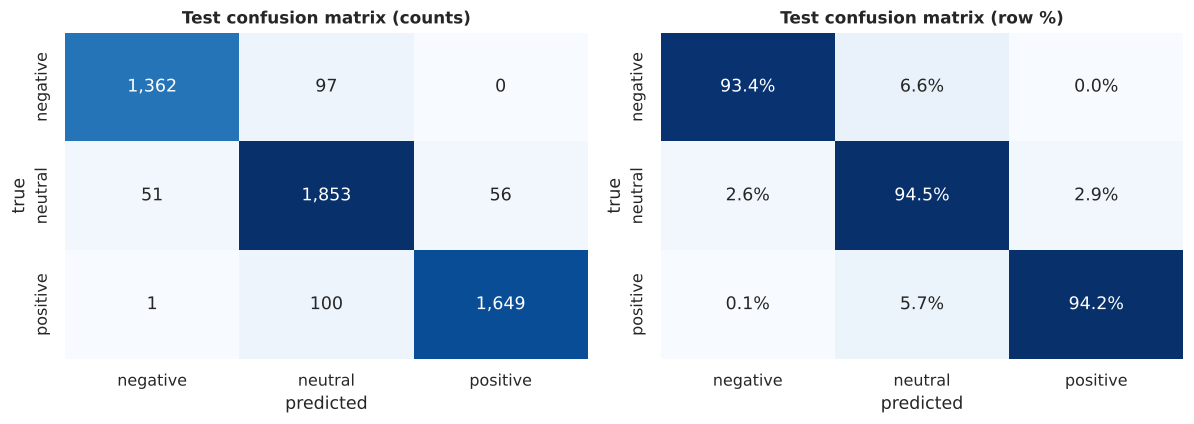

2026/10/14 03:04:59 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Successfully registered model 'montra-sentiment-classifier'.
Created version '1' of model 'montra-sentiment-classifier'.


In [ ]:
import joblib
from text_preprocessing import TextPreprocessor
COMPLEXITY = {"Naive Bayes": 1, "Logistic Regression": 2, "Linear SVM": 2, "Random Forest": 3, "Transformer": 4}
TOLERANCE = 0.003

cands = {}
for _, row in best_tuned.iterrows():
    clf = MODELS[row.model](); clf.set_params(**{row.param: row.value})
    pipe = Pipeline([("prep", TextPreprocessor(row.preprocessing)),
                     ("tfidf", TfidfVectorizer(sublinear_tf=True, **FEATURES[row.features])), ("clf", clf)])
    pipe.fit(train_df["review_text"], train_df["sentiment_label"])
    cands[f"{row.model} (tuned: {row.preprocessing}, {row.features}, {row.param}={row.value:g})"] = dict(
        family=row.model, pipe=pipe, val=pipe.predict(val_df["review_text"]), test=pipe.predict(test_df["review_text"]))
rf = Pipeline([("prep", TextPreprocessor("standard"))] + baseline_pipes["Random Forest"].steps)   # already fitted on train
cands["Random Forest (baseline: standard, word_1gram)"] = dict(family="Random Forest", pipe=rf,
    val=rf.predict(val_df["review_text"]), test=rf.predict(test_df["review_text"]))
if bert_runs:
    b0 = bert_runs[0]                                    # the saved fine-tuned transformer
    cands[f"{BERT_LABEL} ({b0['run']})"] = dict(family="Transformer", pipe=None, val=np.array(b0["val_pred"]),
                                               test=np.array(b0["test_pred"]), max_len=b0["max_len"])

rows = []
for name, c in cands.items():
    rows.append({"model": name, "family": c["family"], "complexity": COMPLEXITY[c["family"]],
                 **eval_metrics(val_df.sentiment_label, c["val"], "val_"), **eval_metrics(test_df.sentiment_label, c["test"], "test_")})
final_table = pd.DataFrame(rows).set_index("model").sort_values("val_f1_macro", ascending=False)
best_val = final_table["val_f1_macro"].max()
shortlist = final_table[final_table["val_f1_macro"] >= best_val - TOLERANCE].sort_values(["complexity", "val_f1_macro"], ascending=[True, False])
SELECTED = shortlist.index[0]
SELECTED_FAMILY = final_table.loc[SELECTED, "family"]
view = final_table[["complexity", "val_f1_macro", "test_accuracy", "test_precision_macro", "test_recall_macro", "test_f1_macro", "test_f1_neutral"]]
display(view.style.format("{:.4f}", subset=[c for c in view.columns if c != "complexity"])
        .apply(lambda r: ["background-color:#cdeee9" if r.name == SELECTED else "" for _ in r], axis=1))
print(f"Best validation macro-F1: {best_val:.4f} ({final_table.index[0]})")
print(f"Within {TOLERANCE} of best: {list(shortlist.index)}")
print(f"SELECTED → {SELECTED}")

test_pred_sel = cands[SELECTED]["test"]
print(classification_report(test_df["sentiment_label"], test_pred_sel, labels=SENT_ORDER, digits=3))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, norm, fmt in [(ax[0], None, ",d"), (ax[1], "true", ".1%")]:
    sns.heatmap(confusion_matrix(test_df["sentiment_label"], test_pred_sel, labels=SENT_ORDER, normalize=norm),
                annot=True, fmt=fmt, cmap="Blues", cbar=False, xticklabels=SENT_ORDER, yticklabels=SENT_ORDER, ax=a)
    a.set_xlabel("predicted"); a.set_ylabel("true")
ax[0].set_title("Test confusion matrix (counts)"); ax[1].set_title("Test confusion matrix (row %)")
plt.tight_layout(); plt.show()

with mlflow.start_run(run_name="final_selected_model") as run:
    mlflow.set_tags({"stage": "final", "model_family": SELECTED_FAMILY, "selected_model": SELECTED})
    mlflow.log_metrics({k: float(v) for k, v in final_table.loc[SELECTED].items() if k.startswith(("val_", "test_"))})
    if cands[SELECTED]["pipe"] is not None:
        final_pipe = cands[SELECTED]["pipe"]
        joblib.dump(final_pipe, MODEL_DIR / "sentiment_classifier_final.joblib")
        try:
            import mlflow.sklearn
            mlflow.sklearn.log_model(final_pipe, name="model", registered_model_name="montra-sentiment-classifier",
                                     serialization_format="cloudpickle")
        except Exception as e:
            print("Model registry logging skipped:", type(e).__name__)
    else:
        mlflow.set_tag("model_path", str(BERT_SAVE_DIR.relative_to(PROJECT_ROOT)))
    FINAL_RUN_ID = run.info.run_id
FINAL_NAME = SELECTED

def predict_reviews(texts):
    """Score raw review text with the selected model → (labels, confidence)."""
    texts = list(texts)
    if SELECTED_FAMILY == "Transformer" and not (BERT_SAVE_DIR / "config.json").exists():
        raise FileNotFoundError(f"The selected {BERT_LABEL} model is not saved in {BERT_SAVE_DIR}. "
                                "Set RUN_BERT = True to fine-tune it on this machine, or load the reference outputs.")
    if SELECTED_FAMILY == "Transformer":
        import torch
        from transformers import pipeline as hf_pipeline
        clf = hf_pipeline("text-classification", model=str(BERT_SAVE_DIR),
                          device=0 if torch.cuda.is_available() else -1)
        out = clf([normalise_unicode(t) for t in texts], batch_size=64, truncation=True, max_length=cands[SELECTED]["max_len"])
        return np.array([o["label"] for o in out]), np.array([o["score"] for o in out])
    step = final_pipe.named_steps["clf"]
    if hasattr(step, "predict_proba"):
        pr = final_pipe.predict_proba(texts)
    else:
        d = final_pipe.decision_function(texts); e = np.exp(d - d.max(axis=1, keepdims=True)); pr = e / e.sum(axis=1, keepdims=True)
    return np.asarray(final_pipe.classes_)[pr.argmax(axis=1)], pr.max(axis=1)

> **Insight — final model selection and test performance.**
> - **RoBERTa has the best validation macro-F1 (0.9434).** Random Forest (0.9422) is within the 0.003 tolerance, so the parsimony rule **selects Random Forest** (complexity 3 vs 4).
> - Tuned Logistic Regression (0.9403) misses the tolerance by just 0.0001. In practice it is an equally valid choice: it is ~350× smaller (0.3 MB vs 117 MB for the Random Forest file) and has interpretable coefficients.
> - **Held-out test performance (Random Forest):**
>   - **accuracy 0.941, macro-F1 0.942**
>   - negative F1 0.948
>   - neutral F1 0.924
>   - positive F1 0.955
> - On the same test set RoBERTa scores 0.943. The test set confirms the validation tie.
> - **Neutral has high recall (0.945) but lower precision (0.904).** When unsure, the model leans towards *neutral*, which is the conservative choice.
> - The selected model is **registered in the MLflow Model Registry** (`montra-sentiment-classifier`, version 1). Its MLflow run ID is stamped on every prediction in Phase 9.

### 7.6 Error analysis

Which kinds of review does the selected model get wrong? Each test review is tagged with the difficulty patterns named in the brief, and the error rate inside each group is compared with the overall error rate.

Reviews containing both a positive AND a negative sentence: 0
Overall test error rate: 5.90% (305 of 5,169 reviews)


,pattern,share of test reviews,error rate in group,error rate outside group,share of all errors,lift vs overall
0,Label disagrees with rating (likely label noise),5.2%,100.0%,0.7%,88.9%,16.9×
3,Hedged / ambiguous language,46.0%,8.1%,4.0%,63.0%,1.4×
5,Contrast connector (but / however / that said),35.4%,7.2%,5.2%,43.0%,1.2×
2,Negation (not / no / never / n't),24.8%,5.9%,5.9%,24.9%,1.0×
4,Multiple topics (3+ aspects),6.9%,5.8%,5.9%,6.9%,1.0×
1,Mixed sentiment (polar + neutral sentences),16.5%,4.4%,6.2%,12.5%,0.8×


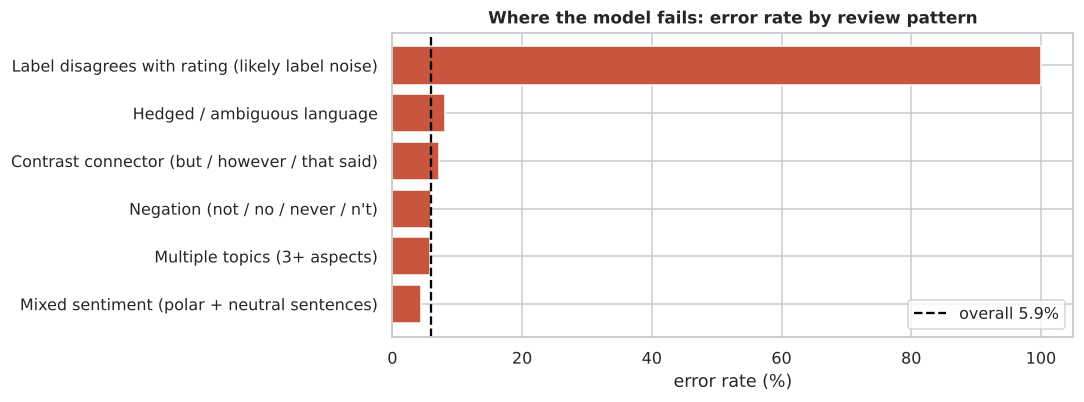

Accuracy where label agrees with rating: 99.31% | where label disagrees with rating: 0.00%


predicted,negative,neutral,positive
true,,,
negative,0,97,0
neutral,51,0,56
positive,1,100,0


,review_text,rating_score,sentiment_label,pred
7279,"The pricing exceeded our expectations — excellent value, and we got far more than we paid for.",3.5,neutral,positive
9853,"I'd describe arrival as about average — it took the usual amount of time. On top of that, the Wi-Fi was fine for our...",2.5,positive,neutral
30607,"We couldn't have asked for a better base while visiting Brighton. On the other hand, the pricing stood out as excell...",3.6,neutral,positive
6586,"Sadly, the check-in process turned out to be delayed for no clear reason. In addition, getting around from the hotel...",2.3,neutral,negative
24499,"Overall the receptionist was adequate, about what we expected. In addition, i'd describe the surrounding area as rea...",2.6,positive,neutral
12634,"Nothing about our visit to Liverpool stood out much either way. Meanwhile, i'd describe the carpet as reasonably cle...",2.8,negative,neutral
5004,"The room service was a real highlight, and portions were generous and fresh. The manager was professional and courte...",3.8,neutral,positive
25897,"The spa was adequate for what we paid. On top of that, i'd describe the rate we paid as fair — it matched what simil...",2.2,negative,neutral


In [ ]:
ea = test_df.copy()
ea["pred"] = test_pred_sel
ea["error"] = ea["pred"] != ea["sentiment_label"]
sent_view = sentences.merge(ea[["review_id"]], on="review_id")
per_review = sent_view.groupby("review_id").agg(
    pos_sents=("sent_pred", lambda s: (s == "positive").sum()), neg_sents=("sent_pred", lambda s: (s == "negative").sum()),
    n_sents=("sent_pred", "size"),
    n_aspects=("aspect", lambda s: s[~s.isin(["Other", "Overall impression"])].nunique()))
ea = ea.merge(per_review, left_on="review_id", right_index=True, how="left")
ea["Label disagrees with rating (likely label noise)"] = ea["label_rating_conflict"]
ea["Mixed sentiment (polar + neutral sentences)"] = ((ea.pos_sents > 0) | (ea.neg_sents > 0)) & (ea.n_sents > ea.pos_sents + ea.neg_sents)
print("Reviews containing both a positive AND a negative sentence:", int(((ea.pos_sents > 0) & (ea.neg_sents > 0)).sum()))
ea["Negation (not / no / never / n't)"] = ea.review_text.str.contains(r"\b(?:not|no|never)\b|n't", case=False)
ea["Hedged / ambiguous language"] = ea.review_text.str.contains(r"\b(?:fine|okay|acceptable|nothing special|about what we expected|average|adequate|standard|might)\b", case=False)
ea["Multiple topics (3+ aspects)"] = ea.n_aspects >= 3
ea["Contrast connector (but / however / that said)"] = ea.review_text.str.contains(r"\b(?:but|however|that said|on the other hand|although)\b", case=False)
CATS = ["Label disagrees with rating (likely label noise)", "Mixed sentiment (polar + neutral sentences)",
        "Negation (not / no / never / n't)", "Hedged / ambiguous language", "Multiple topics (3+ aspects)",
        "Contrast connector (but / however / that said)"]
base_err = ea.error.mean()
err_tab = pd.DataFrame([{"pattern": c, "share of test reviews": ea[c].mean(), "error rate in group": ea.loc[ea[c], "error"].mean(),
                         "error rate outside group": ea.loc[~ea[c], "error"].mean(), "share of all errors": ea.loc[ea.error, c].mean()}
                        for c in CATS])
err_tab["lift vs overall"] = err_tab["error rate in group"] / base_err
err_tab = err_tab.sort_values("lift vs overall", ascending=False)
print(f"Overall test error rate: {base_err:.2%} ({ea.error.sum()} of {len(ea):,} reviews)")
display(err_tab.style.format({c: "{:.1%}" for c in err_tab.columns if c not in ("pattern", "lift vs overall")} | {"lift vs overall": "{:.1f}×"}))

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(err_tab["pattern"][::-1], err_tab["error rate in group"][::-1] * 100, color="#C8553D")
ax.axvline(base_err * 100, ls="--", color="black", label=f"overall {base_err:.1%}")
ax.set_xlabel("error rate (%)"); ax.set_title("Where the model fails: error rate by review pattern"); ax.legend()
plt.tight_layout(); plt.show()

clean_mask = ~ea["label_rating_conflict"]
print(f"Accuracy where label agrees with rating: {(~ea.error[clean_mask]).mean():.2%} | "
      f"where label disagrees with rating: {(~ea.error[~clean_mask]).mean():.2%}")
display(pd.crosstab(ea.loc[ea.error, "sentiment_label"], ea.loc[ea.error, "pred"]).rename_axis(index="true", columns="predicted"))
display(ea[ea.error].sample(min(8, ea.error.sum()), random_state=SEED)[["review_text", "rating_score", "sentiment_label", "pred"]])

> **Insight — error analysis (selected model).**
> - **Overall test error rate: 5.90%** (305 of 5,169 reviews).
> - **Almost all errors are label noise.**
>   - **88.9% of all errors** come from the 5.2% of reviews whose sentiment label disagrees with their rating band.
>   - Where label and rating agree, the model is **99.3% accurate**. Where they disagree it is never "right", because it sides with the text and the rating.
>   - Example: a review rated 3.5 and labelled *neutral* says *"the pricing exceeded our expectations — excellent value"*. The model's *positive* is the better reading.
> - **Difficult language patterns, measured as error rate in the group against outside it:**
>
>   | Pattern | Error rate in group | Outside group | Lift |
>   |---|---|---|---|
>   | Hedged or ambiguous language | 8.1% | 4.0% | 1.4× |
>   | Contrast connectors (*but, however, that said*) | 7.2% | 5.2% | 1.2× |
>   | Negation | 5.9% | 5.9% | 1.0× |
>   | Multiple topics (3+ aspects) | 5.8% | 5.9% | 1.0× |
>   | Mixed polar + neutral sentences | 4.4% | 6.2% | 0.8× |
>
> - **Hedging is the real difficulty.** Phrases such as *"fine"*, *"adequate"* or *"about what we expected"* appear in all three classes, so they blur the neutral boundary.
> - **Negation and multi-topic reviews cause no extra errors**, and mixed polar-plus-neutral reviews are actually *easier*, because one strongly worded sentence anchors the prediction.
> - **No review mixes a positive and a negative sentence**, so true mixed sentiment could not be tested on this data. It is a gap to cover when real reviews arrive.
> - **All errors except one cross the neutral boundary.** Exactly one positive review was predicted negative.

> **Insight — Phase 8 / Objective 7 (Machine learning experimentation).**
> - **Experiments, all tracked in MLflow:**
>   - **52 sentiment runs**: 27 preprocessing × feature × model configurations, 19 hyperparameter settings, 4 baselines and 2 transformer runs
>   - **6 topic modelling runs**
>   - the selected model, registered with its version
> - **Consistent validation:**
>   - one stratified 70/15/15 train / validation / test split, with zero text overlap between splits
>   - 5-fold cross-validation for the grid and tuning
>   - the test set used once, to confirm the selection
> - **What the experiments show:**
>   - Preprocessing and feature choice barely matter (spread < 0.002 macro-F1).
>   - Linear models, Random Forest and the fine-tuned transformer are statistically tied (0.940–0.943).
>   - Naive Bayes trails by about 0.01.
>   - 64 tokens beat 32 by 0.4 points.
>   - Two epochs are enough.
>   - The error analysis traces nearly 90% of remaining errors to label noise.
> - **Most suitable approach for this dataset:** a classical model (Random Forest, or Logistic Regression for size and interpretability). It gives the same accuracy in seconds, not an hour. The fine-tuned transformer remains the best-performing and most data-efficient option, and is the recommended route as the review text becomes more varied.
>
> **Conclusion:** the models have reached the ceiling this dataset allows. The most valuable next step is **better labels**, not a bigger model: re-checking the ~5% of reviews whose label contradicts their rating would lift measured accuracy towards 99%.

---
# Phase 9 — Guest Experience Analytics: from model outputs to business insight

Topics, aspect sentiment and review-level predictions are combined with the hotel, guest and booking data. Model outputs are **stored separately from the source tables and linked by `review_id`**, so the operational database is never modified and every score can be traced back to its model version.

### 8.1 Model outputs table (linked by `review_id`)

In [ ]:
pred_label, pred_conf = predict_reviews(reviews_clean["review_text"])

asp_r = sentences[~sentences.aspect.isin(["Other", "Overall impression"])]
agg = asp_r.groupby("review_id").agg(
    aspects_mentioned=("aspect", lambda s: "; ".join(sorted(set(s)))),
    negative_aspects=("aspect", lambda s: "; ".join(sorted(set(s[asp_r.loc[s.index, "sent_pred"] == "negative"])))),
    positive_aspects=("aspect", lambda s: "; ".join(sorted(set(s[asp_r.loc[s.index, "sent_pred"] == "positive"])))),
    n_aspects=("aspect", "nunique"))
model_outputs = pd.DataFrame({"review_id": reviews_clean["review_id"],
                              "predicted_sentiment": pred_label,
                              "confidence": np.round(pred_conf, 4)}).merge(agg, on="review_id", how="left")
model_outputs[["aspects_mentioned", "negative_aspects", "positive_aspects"]] = model_outputs[["aspects_mentioned", "negative_aspects", "positive_aspects"]].fillna("")
model_outputs["n_aspects"] = model_outputs["n_aspects"].fillna(0).astype(int)
model_outputs["model_version"] = f"{FINAL_NAME} | mlflow run {FINAL_RUN_ID[:8]}"
model_outputs["scored_at"] = pd.Timestamp.now().floor("s")
model_outputs.to_csv(PROC_DIR / "review_model_outputs.csv", index=False)
display(model_outputs.head())

if WRITE_OUTPUTS_TO_DB and (eng := get_engine()) is not None:
    model_outputs.to_sql("review_model_outputs", eng, if_exists="replace", index=False)
    print("Written to PostgreSQL table review_model_outputs (separate from the source tables).")

gx_df = reviews_clean.merge(model_outputs, on="review_id")
gx_df["review_date"] = pd.to_datetime(gx_df["review_date"]); gx_df["month"] = gx_df.review_date.dt.to_period("M").dt.to_timestamp()
def net(s): return ((s == "positive").mean() - (s == "negative").mean()) * 100

,review_id,predicted_sentiment,confidence,aspects_mentioned,negative_aspects,positive_aspects,n_aspects,model_version,scored_at
0,1,neutral,0.9600,Pricing & Value,,,1,"Random Forest (baseline: standard, word_1gram) | mlflow run 36bde5c3",2026-10-14 03:05:44
1,2,positive,0.9400,Cleanliness & Room Condition; Pricing & Value,,Pricing & Value,2,"Random Forest (baseline: standard, word_1gram) | mlflow run 36bde5c3",2026-10-14 03:05:44
2,3,negative,0.9933,Facilities,Facilities,,1,"Random Forest (baseline: standard, word_1gram) | mlflow run 36bde5c3",2026-10-14 03:05:44
3,4,negative,0.9900,Cleanliness & Room Condition; Location & Transport,Cleanliness & Room Condition; Location & Transport,,2,"Random Forest (baseline: standard, word_1gram) | mlflow run 36bde5c3",2026-10-14 03:05:44
4,5,neutral,0.9467,Cleanliness & Room Condition; Food & Dining; Pricing & Value,,,3,"Random Forest (baseline: standard, word_1gram) | mlflow run 36bde5c3",2026-10-14 03:05:44


### 8.2 Overall sentiment distribution

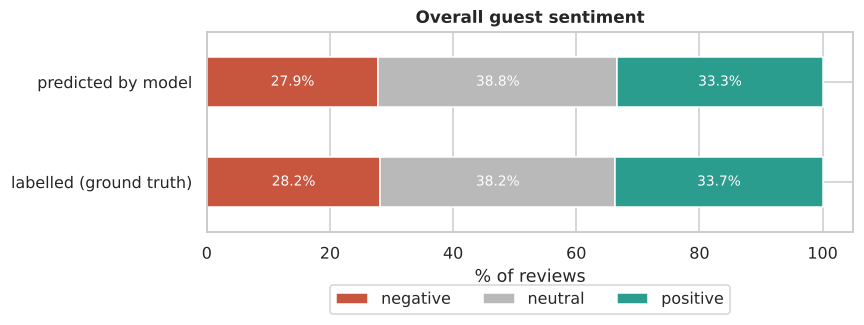

Portfolio net sentiment: +5.5 (labels: +5.5)


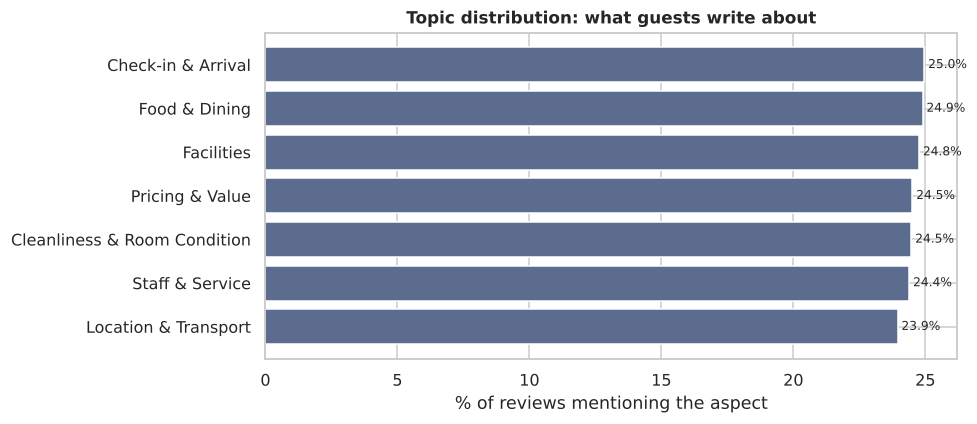

Reviews mentioning at least one aspect: 100.0% | average aspects per review: 1.72


In [ ]:
dist = pd.DataFrame({"labelled (ground truth)": gx_df.sentiment_label.value_counts(normalize=True),
                     "predicted by model": gx_df.predicted_sentiment.value_counts(normalize=True)}).reindex(SENT_ORDER)
fig, ax = plt.subplots(figsize=(8, 3.5))
(dist * 100).T.plot.barh(stacked=True, color=[SENT_COLORS[s] for s in SENT_ORDER], ax=ax)
for i, row in enumerate((dist * 100).T.values):
    left = 0
    for v in row: ax.text(left + v / 2, i, f"{v:.1f}%", ha="center", va="center", color="white", fontsize=9); left += v
ax.set_xlabel("% of reviews"); ax.set_title("Overall guest sentiment"); ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.45), ncol=3)
plt.tight_layout(); plt.show()
print(f"Portfolio net sentiment: {net(gx_df.predicted_sentiment):+.1f} (labels: {net(gx_df.sentiment_label):+.1f})")

# Topic distribution: what share of reviews mention each aspect, and how the mentions split by sentiment
topic_dist = (asp_r.groupby("aspect").agg(reviews=("review_id", "nunique"), mentions=("sentence", "size"))
              .assign(share_of_reviews=lambda t: t.reviews / reviews_clean.review_id.nunique())
              .sort_values("share_of_reviews"))
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(topic_dist.index, topic_dist.share_of_reviews * 100, color="#5B6C8F")
for i, v in enumerate(topic_dist.share_of_reviews): ax.text(v * 100, i, f" {v:.1%}", va="center", fontsize=8)
ax.set_xlabel("% of reviews mentioning the aspect"); ax.set_title("Topic distribution: what guests write about")
plt.tight_layout(); plt.show()
print("Reviews mentioning at least one aspect:", f"{asp_r.review_id.nunique() / reviews_clean.review_id.nunique():.1%}",
      "| average aspects per review:", f"{model_outputs.n_aspects.mean():.2f}")

### 8.3 Hotel and location performance

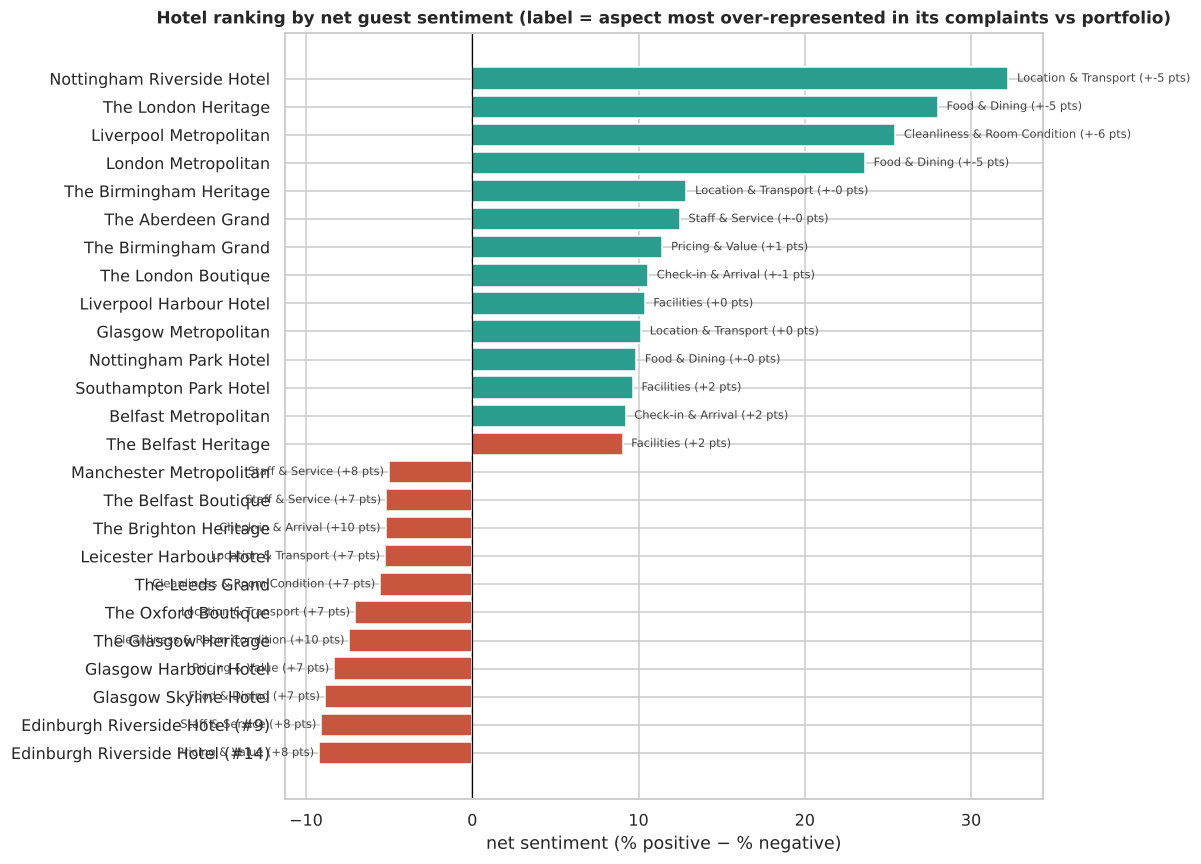

,hotel_label,location,star_rating,reviews,avg_rating,net_sentiment,negative_share,signature complaint
1,Edinburgh Riverside Hotel (#14),Edinburgh,3,1422,2.83,-9.2,34.7%,Pricing & Value (+8 pts)
2,Edinburgh Riverside Hotel (#9),Edinburgh,3,1487,2.84,-9.1,35.2%,Staff & Service (+8 pts)
5,Glasgow Skyline Hotel,Glasgow,3,1445,2.83,-8.9,34.5%,Food & Dining (+7 pts)
3,Glasgow Harbour Hotel,Glasgow,3,1385,2.86,-8.3,33.4%,Pricing & Value (+7 pts)
20,The Glasgow Heritage,Glasgow,3,1354,2.86,-7.4,34.4%,Cleanliness & Room Condition (+10 pts)
24,The Oxford Boutique,Oxford,3,1405,2.86,-7.0,33.6%,Location & Transport (+7 pts)


,hotels,reviews,avg_rating,net_sentiment
location,,,,
Edinburgh,2,2909,2.84,-9.1
Oxford,1,1405,2.86,-7.0
Leeds,1,1373,2.86,-5.5
Leicester,1,1353,2.85,-5.2
Brighton,1,1399,2.88,-5.2
Manchester,1,1418,2.88,-5.0
Glasgow,4,5612,2.91,-3.5
Belfast,3,4202,3.02,+4.3
Southampton,1,1460,3.09,+9.7


Correlation between hotel avg rating and net sentiment: 0.998


In [ ]:
# "signature complaint": the aspect whose negative share at this hotel exceeds the portfolio level the most
neg_rate = (asp_r.merge(reviews_clean[["review_id", "hotel_label"]], on="review_id")
            .assign(neg=lambda t: t.sent_pred == "negative").groupby(["hotel_label", "aspect"])["neg"].mean().unstack())
over_index = (neg_rate - asp_r.assign(neg=asp_r.sent_pred == "negative").groupby("aspect")["neg"].mean()) * 100
top_complaint = over_index.apply(lambda r: f"{r.idxmax()} (+{r.max():.0f} pts)", axis=1)
hotel_perf = (gx_df.groupby(["hotel_label", "location", "star_rating"])
              .agg(reviews=("review_id", "size"), avg_rating=("rating_score", "mean"),
                   net_sentiment=("predicted_sentiment", net), negative_share=("predicted_sentiment", lambda s: (s == "negative").mean()))
              .reset_index().sort_values("net_sentiment"))
hotel_perf["signature complaint"] = hotel_perf.hotel_label.map(top_complaint)
fig, ax = plt.subplots(figsize=(11, 8))
cols = np.where(hotel_perf.net_sentiment < hotel_perf.net_sentiment.median(), "#C8553D", "#2A9D8F")
ax.barh(hotel_perf.hotel_label, hotel_perf.net_sentiment, color=cols)
for i, (v, c) in enumerate(zip(hotel_perf.net_sentiment, hotel_perf["signature complaint"])):
    ax.text(v + (0.3 if v >= 0 else -0.3), i, f" {c}", va="center", ha="left" if v >= 0 else "right", fontsize=7.5, color="#444")
ax.axvline(0, color="black", lw=0.8); ax.set_xlabel("net sentiment (% positive − % negative)")
ax.set_title("Hotel ranking by net guest sentiment (label = aspect most over-represented in its complaints vs portfolio)")
plt.tight_layout(); plt.show()
display(hotel_perf.head(6).style.format({"avg_rating": "{:.2f}", "net_sentiment": "{:+.1f}", "negative_share": "{:.1%}"}))
loc_perf = gx_df.groupby("location").agg(hotels=("hotel_id", "nunique"), reviews=("review_id", "size"),
            avg_rating=("rating_score", "mean"), net_sentiment=("predicted_sentiment", net)).sort_values("net_sentiment")
display(loc_perf.style.format({"avg_rating": "{:.2f}", "net_sentiment": "{:+.1f}"}).background_gradient(subset=["net_sentiment"], cmap="RdYlGn"))
print("Correlation between hotel avg rating and net sentiment: %.3f" % hotel_perf[["avg_rating", "net_sentiment"]].corr().iloc[0, 1])

### 8.4 Customer segments and booking context

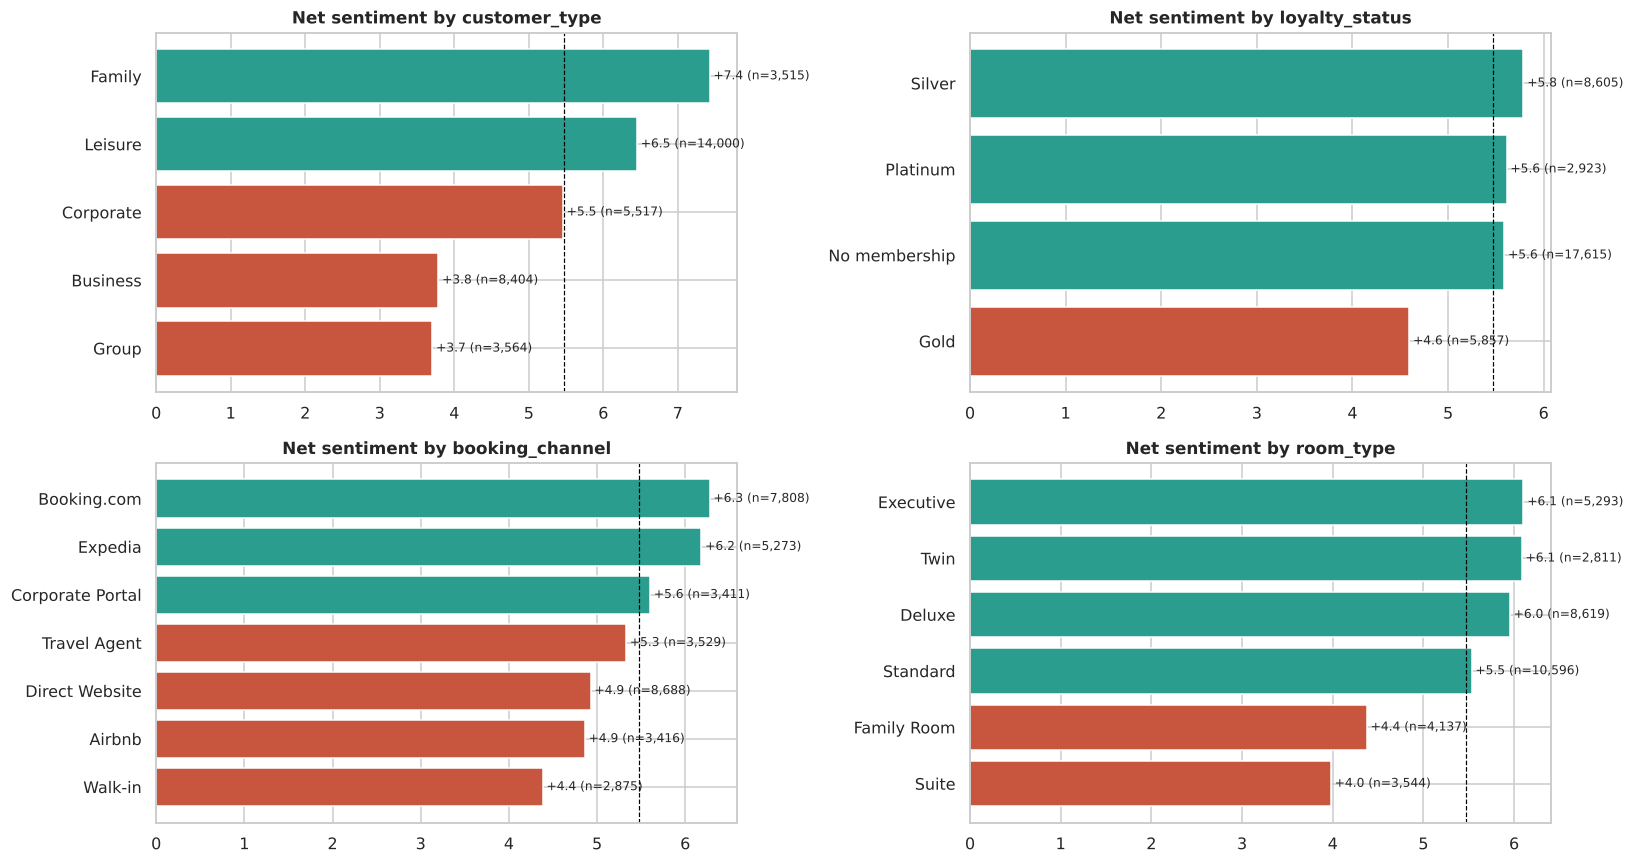

,lowest,highest,spread (pts)
dimension,,,
customer_type,Group (+3.7),Family (+7.4),3.7
loyalty_status,Gold (+4.6),Silver (+5.8),1.2
booking_channel,Walk-in (+4.4),Booking.com (+6.3),1.9
room_type,Suite (+4.0),Executive (+6.1),2.1
hotel (for comparison),Edinburgh Riverside Hotel (#14) (-9.2),Nottingham Riverside Hotel (+32.2),41.5


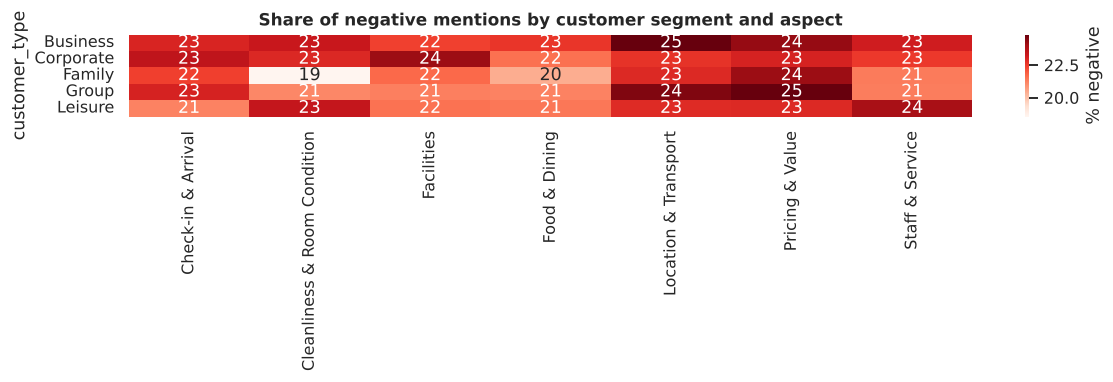

Largest segment gap per aspect (pts of % negative): Check-in & Arrival 2.3, Cleanliness & Room Condition 4.9, Facilities 2.8, Food & Dining 2.2, Location & Transport 2.2, Pricing & Value 1.9, Staff & Service 2.6


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
for a, col in zip(axes.ravel(), ["customer_type", "loyalty_status", "booking_channel", "room_type"]):
    t = gx_df.groupby(col).agg(net=("predicted_sentiment", net), n=("review_id", "size")).sort_values("net")
    a.barh(t.index, t.net, color=np.where(t.net < net(gx_df.predicted_sentiment), "#C8553D", "#2A9D8F"))
    a.axvline(net(gx_df.predicted_sentiment), ls="--", color="black", lw=0.8)
    for i, (v, n) in enumerate(zip(t.net, t.n)): a.text(v, i, f" {v:+.1f} (n={n:,})", va="center", fontsize=8)
    a.set_title(f"Net sentiment by {col}")
plt.tight_layout(); plt.show()
seg_rows = []
for col in ["customer_type", "loyalty_status", "booking_channel", "room_type"]:
    t = gx_df.groupby(col).agg(reviews=("review_id", "size"), net=("predicted_sentiment", net))
    seg_rows.append({"dimension": col, "lowest": f"{t.net.idxmin()} ({t.net.min():+.1f})",
                     "highest": f"{t.net.idxmax()} ({t.net.max():+.1f})", "spread (pts)": t.net.max() - t.net.min()})
hotel_net = gx_df.groupby("hotel_label")["predicted_sentiment"].apply(net)
seg_rows.append({"dimension": "hotel (for comparison)", "lowest": f"{hotel_net.idxmin()} ({hotel_net.min():+.1f})",
                 "highest": f"{hotel_net.idxmax()} ({hotel_net.max():+.1f})", "spread (pts)": hotel_net.max() - hotel_net.min()})
display(pd.DataFrame(seg_rows).set_index("dimension").style.format({"spread (pts)": "{:.1f}"}))
seg_asp = (asp_r.merge(reviews_clean[["review_id", "customer_type"]], on="review_id")
           .groupby(["customer_type", "aspect"])["sent_pred"].apply(lambda s: (s == "negative").mean() * 100).unstack())
fig, ax = plt.subplots(figsize=(11, 3.6))
sns.heatmap(seg_asp, annot=True, fmt=".0f", cmap="Reds", ax=ax, cbar_kws={"label": "% negative"})
ax.set_title("Share of negative mentions by customer segment and aspect"); ax.set_xlabel(""); plt.tight_layout(); plt.show()
print("Largest segment gap per aspect (pts of % negative):",
      ", ".join(f"{a} {seg_asp[a].max() - seg_asp[a].min():.1f}" for a in seg_asp.columns))

### 8.5 Review trends and emerging issues

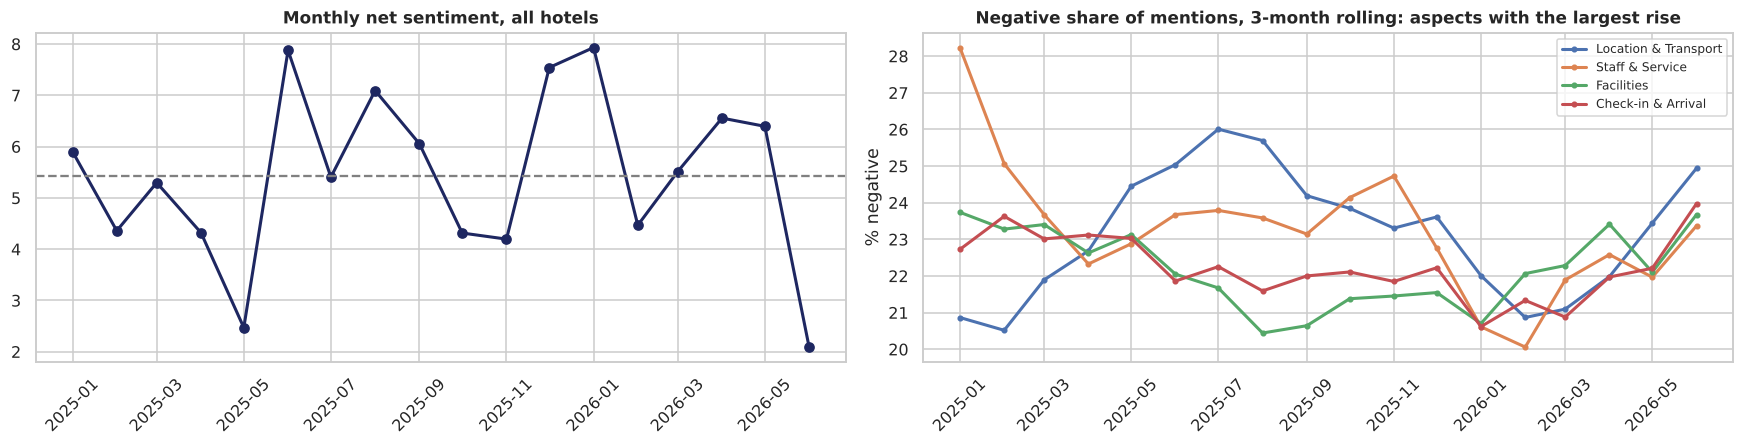

,"change in % negative (late vs early quarter, pts)"
aspect,
Location & Transport,+0.8
Staff & Service,-0.4
Facilities,-0.5
Check-in & Arrival,-0.9
Pricing & Value,-0.9
Food & Dining,-0.9
Cleanliness & Room Condition,-2.6


In [ ]:
asp_t = asp_r.merge(gx_df[["review_id", "month"]], on="review_id")
neg_month = asp_t.groupby(["month", "aspect"])["sent_pred"].apply(lambda s: (s == "negative").mean() * 100).unstack()
months = sorted(gx_df.month.unique())
early, late = months[1:4], months[-4:-1]          # full quarters at each end (first/last months are partial)
change = (neg_month.loc[late].mean() - neg_month.loc[early].mean()).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(16, 4.2))
nm = gx_df.groupby("month")["predicted_sentiment"].apply(net)
ax[0].plot(nm.index, nm.values, marker="o", color="#1E2761", lw=2); ax[0].axhline(nm.mean(), ls="--", color="grey")
ax[0].set_title("Monthly net sentiment, all hotels"); ax[0].tick_params(axis="x", rotation=45)
for a_ in change.index[:4]:
    ax[1].plot(neg_month.index, neg_month[a_].rolling(3, min_periods=1).mean(), marker=".", lw=2, label=a_)
ax[1].set_title("Negative share of mentions, 3-month rolling: aspects with the largest rise"); ax[1].legend(fontsize=8)
ax[1].tick_params(axis="x", rotation=45); ax[1].set_ylabel("% negative")
plt.tight_layout(); plt.show()
display(change.rename("change in % negative (late vs early quarter, pts)").to_frame().style.format("{:+.1f}"))

### 8.6 Recurring complaints

In [ ]:
neg_sent = sentences[(sentences.sent_pred == "negative") & ~sentences.aspect.isin(["Other", "Overall impression"])]
# (a) complaints by aspect, with the most repeated complaint statements
rc = (neg_sent.groupby("aspect").agg(mentions=("review_id", "size"), reviews=("review_id", "nunique"))
      .sort_values("mentions", ascending=False))
rc["share of negative mentions"] = rc["mentions"] / len(neg_sent)
rc["most repeated complaints"] = [" | ".join(neg_sent.loc[neg_sent.aspect == a, "sentence"].str.lower().str.rstrip(".")
                                             .value_counts().head(3).index) for a in rc.index]
display(rc.style.format({"mentions": "{:,}", "reviews": "{:,}", "share of negative mentions": "{:.1%}"}))

# (b) BERTopic complaint themes: clusters whose own aspect matches the complaint's aspect
topic_aspect = {t: business_aspect(map_aspect(topic_model.get_topic(int(t)))[0]) for t in neg_sent.topic.dropna().unique() if t != -1}
in_theme = neg_sent[[pd.notna(t) and t != -1 and topic_aspect.get(t) == a for t, a in zip(neg_sent.topic, neg_sent.aspect)]]
themes = (in_theme.groupby(["aspect", "topic"]).agg(mentions=("review_id", "size"),
                                                     example=("sentence", lambda x: x.value_counts().index[0]))
          .reset_index().sort_values("mentions", ascending=False))
themes["topic words"] = themes["topic"].map(lambda t: ", ".join(w for w, _ in topic_model.get_topic(int(t))[:6]))
display(themes.head(10)[["aspect", "topic words", "mentions", "example"]].style.format({"mentions": "{:,}"}))
top_neg = neg_sent["sentence"].str.lower().value_counts().head(10)
print("\nMost frequent individual complaint sentences:")
for t, n in top_neg.items(): print(f"  {n:>4}×  {t}")
neg_by_aspect = neg_sent.groupby("aspect").size().sort_values(ascending=False)
print("Negative mentions by aspect:", ", ".join(f"{a} {n:,}" for a, n in neg_by_aspect.items()))

,mentions,reviews,share of negative mentions,most repeated complaints
aspect,,,,
Pricing & Value,"2,029","2,018",14.8%,the rate we paid left a lot to be desired; several amenities cost extra on top of the rate | the cost of the stay left a lot to be desired; the quality didn't match the price tag | the cost of the stay left a lot to be desired; several amenities cost extra on top of the rate
Location & Transport,"1,977","1,971",14.4%,we were disappointed that the surrounding area was hard to reach without a car | the neighborhood left a lot to be desired; there was very little around after dark | the neighborhood turned out to be hard to reach without a car
Staff & Service,"1,975","1,964",14.4%,the hotel staff left a lot to be desired; our complaints were largely ignored | the housekeeping staff left a lot to be desired; communication was a constant struggle | the front desk team left a lot to be desired; we had to ask twice before anything got done
Check-in & Arrival,"1,963","1,957",14.3%,arrival left a lot to be desired; the system apparently crashed while we waited | the check-in process left a lot to be desired; the system apparently crashed while we waited | the check-in desk left a lot to be desired; we waited over 40 minutes at the desk
Cleanliness & Room Condition,"1,948","1,936",14.2%,the bathroom left a lot to be desired; it clearly hadn't been cleaned that day | the room left a lot to be desired; the bathroom hadn't been properly scrubbed | our suite left a lot to be desired; we found dust on the shelves
Facilities,"1,937","1,919",14.1%,the gym left a lot to be desired; it needed a serious refurbishment | the lounge left a lot to be desired; parts of it weren't working properly | the gym left a lot to be desired; parts of it weren't working properly
Food & Dining,"1,895","1,882",13.8%,the buffet left a lot to be desired; several items were clearly reheated | the buffet left a lot to be desired; the same few dishes appeared every single day | the restaurant left a lot to be desired; the queue moved painfully slowly


,aspect,topic words,mentions,example
21,Pricing & Value,"price, cost, rate, charge, deal, price price","1,539",the overall price turned out to be overpriced.
0,Check-in & Arrival,"arrival, arrival arrival, room ready, ready, ready arrival, room","1,073",our arrival experience left a lot to be desired; our room wasn't ready despite an on-time arrival.
19,Location & Transport,"transport, transport transport, car, city center, city, transport neighborhood",916,the neighborhood turned out to be hard to reach without a car.
22,Staff & Service,"manager, receptionist, concierge, manager manager, receptionist manager, manager concierge",731,the concierge turned out to be unprofessional.
20,Location & Transport,"neighborhood neighborhood, neighborhood, , , ,",674,the surrounding area turned out to be in a rather unsafe area.
14,Food & Dining,"pastries, buffet, breakfast, buffet breakfast, pastries buffet, breakfast buffet",623,the breakfast turned out to be bland.
3,Cleanliness & Room Condition,"carpet, cor, carpet carpet, cor cor, cor carpet, carpet cor",484,the overall décor left a lot to be desired; the bathroom hadn't been properly scrubbed.
2,Cleanliness & Room Condition,"bathroom bathroom, bathroom, desk bathroom, check desk, bathroom check, check",453,the bathroom turned out to be unhygienic.
9,Facilities,"gym, fitness, fitness facilities, facilities, gym gym, gym fitness",423,The gym left a lot to be desired; parts of it weren't working properly.
15,Food & Dining,"roomservice, roomservice roomservice, fare, variety, roomservice dining, variety roomservice",363,the room service turned out to be limited and repetitive.



Most frequent individual complaint sentences:
    39×  the rate we paid left a lot to be desired; several amenities cost extra on top of the rate.
    39×  the cost of the stay left a lot to be desired; the quality didn't match the price tag.
    38×  the cost of the stay left a lot to be desired; several amenities cost extra on top of the rate.
    37×  the pricing left a lot to be desired; we found better options nearby for less.
    37×  the rate we paid left a lot to be desired; the quality didn't match the price tag.
    36×  the cost of the stay left a lot to be desired; we found better options nearby for less.
    36×  we were disappointed that the surrounding area was hard to reach without a car.
    36×  the neighborhood left a lot to be desired; there was very little around after dark.
    35×  the pricing left a lot to be desired; several amenities cost extra on top of the rate.
    33×  the overall price left a lot to be desired; the quality didn't match the price tag.
Neg

### 8.7 Positive feedback patterns: what guests praise

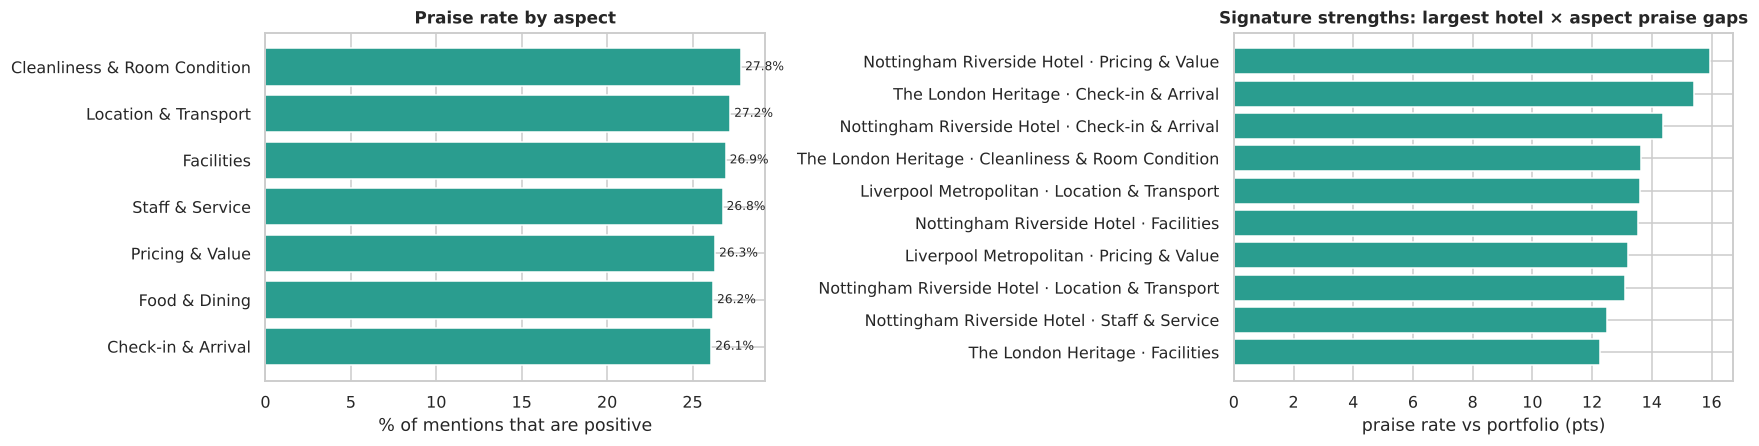

,mentions,praised,praise_rate
aspect,,,
Check-in & Arrival,"8,801","2,297",26.1%
Food & Dining,"8,769","2,298",26.2%
Pricing & Value,"8,615","2,268",26.3%
Staff & Service,"8,582","2,297",26.8%
Facilities,"8,743","2,356",26.9%
Location & Transport,"8,431","2,294",27.2%
Cleanliness & Room Condition,"8,625","2,402",27.8%


Most frequent praise sentences:
    45×  the location was ideally situated.
    39×  the overall price was excellent value.
    37×  the surrounding area was ideally situated.
    36×  the neighborhood was perfectly placed for exploring.
    34×  the overall price was very reasonably priced.
    34×  i was genuinely impressed that the rate we paid was excellent value.
    34×  the overall price was a great deal.
    32×  the location was perfectly placed for exploring.
Signature strengths (praise rate vs portfolio):
  Nottingham Riverside Hotel         Pricing & Value                +15.9 pts
  The London Heritage                Check-in & Arrival             +15.4 pts
  Nottingham Riverside Hotel         Check-in & Arrival             +14.4 pts
  The London Heritage                Cleanliness & Room Condition   +13.6 pts
  Liverpool Metropolitan             Location & Transport           +13.6 pts
  Nottingham Riverside Hotel         Facilities                     +13.5 pts
Most posit

In [ ]:
pos_sent = asp_r[asp_r.sent_pred == "positive"].merge(reviews_clean[["review_id", "hotel_label", "customer_type"]], on="review_id")
praise = (asp_r.assign(pos=asp_r.sent_pred == "positive").groupby("aspect")
          .agg(mentions=("pos", "size"), praised=("pos", "sum")).assign(praise_rate=lambda t: t.praised / t.mentions)
          .sort_values("praise_rate"))
fig, ax = plt.subplots(1, 2, figsize=(16, 4.2))
ax[0].barh(praise.index, praise.praise_rate * 100, color="#2A9D8F")
for i, v in enumerate(praise.praise_rate): ax[0].text(v * 100, i, f" {v:.1%}", va="center", fontsize=8)
ax[0].set_xlabel("% of mentions that are positive"); ax[0].set_title("Praise rate by aspect")
port = asp_r.assign(pos=asp_r.sent_pred == "positive").groupby("aspect")["pos"].mean()
hp = (pos_sent.groupby(["hotel_label", "aspect"]).size()
      / asp_r.merge(reviews_clean[["review_id", "hotel_label"]], on="review_id").groupby(["hotel_label", "aspect"]).size()).unstack()
strength = (hp - port).stack().sort_values(ascending=False).head(10)
ax[1].barh([f"{h} · {a}" for h, a in strength.index[::-1]], strength.values[::-1] * 100, color="#2A9D8F")
ax[1].set_xlabel("praise rate vs portfolio (pts)"); ax[1].set_title("Signature strengths: largest hotel × aspect praise gaps")
plt.tight_layout(); plt.show()
display(praise.style.format({"mentions": "{:,}", "praised": "{:,}", "praise_rate": "{:.1%}"}))
print("Most frequent praise sentences:")
for t, n in pos_sent["sentence"].str.lower().value_counts().head(8).items(): print(f"  {n:>4}×  {t}")
print("Signature strengths (praise rate vs portfolio):")
for (h, a_), v in strength.head(6).items(): print(f"  {h:<34} {a_:<30} {v * 100:+.1f} pts")
best = gx_df.groupby("hotel_label")["predicted_sentiment"].apply(net).sort_values(ascending=False).head(3)
print("Most positive hotels (net sentiment):", ", ".join(f"{h} {v:+.1f}" for h, v in best.items()))

> **Insight — positive feedback patterns.**
> - **Praise is spread evenly across aspects**: between **26.1% (Check-in & Arrival)** and **27.8% (Cleanliness & Room Condition)** of mentions are positive. As with complaints, the differences that matter are between hotels.
> - **The most repeated praise is about location** (*"ideally situated"*, *"perfectly placed for exploring"*) **and value** (*"excellent value"*, *"a great deal"*).
> - **Pricing & Value is polarised.** It produces both the most complaints (8.6) and some of the most repeated praise. How guests perceive value depends on the hotel, not on price levels across the portfolio.
> - **The most positive hotels are Nottingham Riverside (+32.2), The London Heritage (+28.0) and Liverpool Metropolitan (+25.4).** Their signature strengths, in praise rate above the portfolio:
>   - Nottingham Riverside: **Pricing & Value (+15.9 pts)**, Check-in & Arrival (+14.4) and Facilities (+13.5)
>   - The London Heritage: **Check-in & Arrival (+15.4)** and Cleanliness & Room Condition (+13.6)
>   - Liverpool Metropolitan: **Location & Transport (+13.6)**
> - **These are the practices to copy.** Nottingham Riverside's value proposition answers the portfolio's most common complaint, and The London Heritage's check-in shows what the Brighton Heritage could achieve.

> **Insight — Phase 9 (Guest experience analytics).**
> - **Model outputs are stored separately from the source tables.** `review_model_outputs.csv` holds the predicted sentiment, confidence, aspects mentioned, negative and positive aspects, model version and timestamp for every review, keyed by `review_id`. With `WRITE_OUTPUTS_TO_DB = True` the same table is written to its own Postgres table. Predicted portfolio net sentiment (**+5.5**) matches the labels exactly, so the model reproduces the overall picture faithfully.
> - **Hotels differ hugely; guest segments barely differ.**
>   - Net sentiment spans **41.5 points across hotels**, from Edinburgh Riverside #14 (−9.2) to Nottingham Riverside (+32.2). It tracks average rating almost perfectly (r = 0.998).
>   - Customer type, loyalty tier, booking channel and room type each span **under 4 points**, ten times less. Group guests are the least positive (+3.7), families the most (+7.4).
>   - Dissatisfaction is a **property** issue, not a customer-mix issue.
> - **The six weakest hotels are all 3★, and each has a different signature complaint.** This is why a single portfolio-wide fix would fail:
>
>   | Hotel | Net sentiment | Signature complaint (pts above portfolio negative share) |
>   |---|---|---|
>   | Edinburgh Riverside #14 | −9.2 | Pricing & Value (+8) |
>   | Edinburgh Riverside #9 | −9.1 | Staff & Service (+8) |
>   | Glasgow Skyline | −8.9 | Food & Dining (+7) |
>   | Glasgow Harbour | −8.3 | Pricing & Value (+7) |
>   | The Glasgow Heritage | −7.4 | Cleanliness & Room Condition (+10) |
>   | The Oxford Boutique | −7.0 | Location & Transport (+7) |
>
> - **Locations:** Edinburgh (−9.1) and Oxford (−7.0) trail; Nottingham (+21.1) and London (+20.6) lead. Glasgow, with four hotels, averages −3.5.
> - **Trends:** over 18 months, no aspect's negative share moved by more than 2.6 points between the first and last full quarters. **Location & Transport is the only aspect drifting worse (+0.8 pts)**, which is worth monitoring. Cleanliness & Room Condition improved the most (−2.6 pts). There is no emerging portfolio-wide problem.
> - **Recurring complaints** (8.6) are concrete and repeated almost word for word:
>   - **Pricing & Value** has the most negative mentions (2,029). The ten most repeated complaint sentences are almost all about it: *"several amenities cost extra on top of the rate"*, *"the quality didn't match the price tag"*, *"we found better options nearby for less"*.
>   - **Location**: *"hard to reach without a car"*, *"very little around after dark"*, *"a rather unsafe area"*.
>   - **Staff**: *"our complaints were largely ignored"*, *"communication was a constant struggle"*, *"we had to ask twice"*.
>   - **Check-in**: *"the system apparently crashed while we waited"*, *"our room wasn't ready despite an on-time arrival"*.
>   - **Cleanliness & room condition**: *"the bathroom hadn't been properly scrubbed"*, *"it clearly hadn't been cleaned that day"*.
>   - **Facilities**: *"needed a serious refurbishment"*, *"parts of it weren't working properly"*.
>   - **Food**: *"several items were clearly reheated"*, *"the same few dishes appeared every single day"*.

---
# Business Insight Report

## What guests tell Montra's hotels

**1. Ratings show how guests feel; the text shows why.** Booking value, room type, channel, stay length and guest profile explain essentially nothing about satisfaction (all correlations ≈ 0). Aspect-level sentiment extracted from the text explains **74%** of the variation in ratings.

**2. Satisfaction is decided at property level.** Hotels differ by **41.5 points** of net sentiment; customer segments by under 4. Star rating is the strongest structured driver (3★ 2.86 → 5★ 3.33 average rating), and all six weakest hotels are 3★.

**3. Every weak hotel has its own problem.** Across the portfolio the seven aspects are within 2.5 points of each other, so there is no single "worst aspect" to fix everywhere. At hotel level the gaps are large and specific: value at Edinburgh Riverside #14 and Glasgow Harbour, staff at Edinburgh Riverside #9, food at Glasgow Skyline, cleanliness and room condition at The Glasgow Heritage, location and room condition at The Oxford Boutique.

**4. Value for money is the most common weak spot.** Pricing & Value has the most negative mentions (2,029), the highest rating impact per mention (0.51) and the most repeated complaints. The complaint is specific: **extras charged on top of the rate** and **quality not matching the price**.

**5. Neutral is the biggest opportunity.** About half of all aspect mentions are neutral (*"fine"*, *"adequate"*). Most guests are not unhappy; they are unimpressed.

## Recommendations

| Priority | Recommendation | Evidence | Where |
|---|---|---|---|
| 1 | Review rate transparency: bundle or clearly disclose extras at booking | Pricing & Value: most complaints (2,029) and highest rating impact; the most repeated complaint sentences cite extras and value | All hotels, starting with Edinburgh Riverside #14 and #9 and Glasgow Harbour |
| 2 | Run a full operational review of the two Edinburgh Riverside hotels | Lowest net sentiment in the portfolio (−9.2 and −9.1); five of the ten largest hotel × aspect gaps (value, food, location, staff) | Edinburgh Riverside #9 and #14 |
| 3 | Targeted housekeeping and maintenance audits | Cleanliness & Room Condition 15–17 pts below portfolio; complaints about unscrubbed bathrooms and rooms not cleaned that day | The Glasgow Heritage, The Oxford Boutique |
| 4 | Review food quality and menu rotation | Food & Dining 14–15 pts below portfolio; complaints about reheated items and the same dishes every day | Glasgow Skyline, Edinburgh Riverside #14 |
| 5 | Peak-time front-desk staffing and check-in system reliability | Check-in complaints: system crashes, rooms not ready on arrival | Portfolio-wide, starting with The Brighton Heritage (−14 pts on check-in) |
| 6 | Manage location expectations (transport guidance, evening information, shuttle options in listings) | Location & Transport is the only aspect trending worse; complaints about access without a car and little to do after dark | The Oxford Boutique, Edinburgh Riverside #9 |
| 7 | Copy what the best hotels do | Nottingham Riverside is praised for value (+15.9 pts above portfolio), The London Heritage for check-in (+15.4) and Liverpool Metropolitan for location (+13.6) | Pair each weak hotel with a strong one on its signature complaint, e.g. Edinburgh Riverside #14 with Nottingham Riverside on value |
| 8 | Benchmark hotels within their star tier | Star rating sets the baseline; a 3★ hotel at 2.9 may be performing to standard | Reporting |
| 9 | Use the classifier for automated tagging, with a monthly hotel × aspect report | 94% accurate; outputs keyed by `review_id` with model version | Montra platform |
| 10 | Audit labelling: re-label the ~5% of reviews whose label contradicts the rating | 89% of model errors trace to these | Data team |

## Limitations

- **Templated text.** The review text is highly templated (only 6,764 unique sentences). Real guest language will be more varied, so performance should be re-validated on live reviews before use.
- **Offline model choices in this execution.** Hugging Face was unreachable, so topic embeddings used RoBERTa-base (layers 4–8, aspect-focused) instead of `all-MiniLM-L6-v2`, and the RoBERTa weights came from spaCy's `en_core_web_trf` release (see the README). With internet access the notebook uses the original models.
- **No mixed reviews.** No review combines strong praise with a strong complaint, so true mixed-sentiment handling is untested.
- **Untested scope.** Only English reviews were analysed, and sarcasm and emotion were out of scope.

---
# Conclusion

**Answers to the project's key questions**

| Question (Phase 1) | Answer |
|---|---|
| What factors influence guest satisfaction? | The hotel itself and what happens during the stay. Aspect sentiment explains 74% of rating variation; guest profile and booking details explain almost none. |
| What issues repeatedly appear in guest feedback? | Extras charged on top of the rate and poor value; locations that are hard to reach without a car; ignored complaints; check-in system failures and rooms not ready; unscrubbed bathrooms; tired facilities; reheated, repetitive food. |
| Which topics generate positive or negative sentiment? | Across the portfolio, all seven aspects are mildly positive (net +2.8 to +5.3). Pricing & Value is the least positive and Cleanliness & Room Condition the most. Each aspect turns sharply negative at specific hotels (5.4). |
| How can management identify recurring problems? | Through the hotel × aspect sentiment table (5.4), the recurring-complaints tables (8.6) and the per-aspect trend monitor (8.5), all refreshed by re-running this notebook on new reviews. |
| Which modelling approach is most effective? | All strong models are statistically tied (0.940–0.943 macro-F1). The parsimony rule selects **Random Forest** (0.942 test macro-F1); the fine-tuned RoBERTa-base scores 0.943 and is the most data-efficient. Remaining errors are dominated by label noise. |

**Deliverables produced**

| Deliverable | Where |
|---|---|
| Data collection pipeline | `extract_tables()` (Phase 2, 1.1) |
| EDA report | Phase 3 and `reports/01_EDA_report.md` |
| Cleaned NLP dataset | `data/processed/nlp_corpus.csv` and `reviews_clean.csv` |
| NLP preprocessing pipeline | `src/text_preprocessing.py` |
| Topic modelling experiment | Phase 5 and MLflow `montra-topic-modelling` |
| Topic sentiment analysis | Phase 6 and `review_sentences_topics.csv` |
| Baseline sentiment models and BERT sentiment model | Phase 7 |
| Model evaluation report and error analysis | 7.5, 7.6 and `reports/02_model_evaluation_report.md` |
| MLflow experiment tracking | `mlruns/` (`mlflow ui`) |
| Guest experience intelligence analysis | Phase 9 and `review_model_outputs.csv` |
| Business insight report | Above and `reports/03_business_insight_report.md` |

**What was learned:**
- **Topic-level sentiment is more useful than an overall score.** The portfolio average shows seven near-identical aspects; the hotel × aspect view shows exactly where each one fails.
- **Topic models need guiding.** Clustering whole sentences grouped them by mood. Focusing the embedding on aspect words, and checking each sentence's aspect against its own words, made the topics usable.
- **Data quality sets the ceiling.** About 5% of labels contradict their ratings, and those account for 89% of model errors.
- **The simple baseline earned its place.** Classical models reach ~94%, so a transformer has to clear a high bar to justify its cost.